# Comprehensive Results Analysis
## Bike Demand Forecasting Study — Multi-City (v7)

Structure:
- **Section 0**: Config & helpers
- **Section 1**: Load data
- **Section 2**: Per-city analysis (loop over the cities in DATASETS)
  - RQ1.1 Model rankings
  - RQ1.2 Weather covariate impact (TabPFN)
  - RQ1.3 Weather degradation impact
  - Variance / stability
- **Section 3**: Cross-city comparison
- **Section 4**: fev-bench metrics (win rate, skill score, week block bootstrap)
- **Section 5**: Answers to the research questions: comparisons with 95 % intervals (replaces statistical_significance_v7.ipynb)
- **Section 6**: Paper figures (page width): skill-score and win-rate heatmaps, MASE by horizon, weather settings

> **Changelog note (consolidation pass):** The original `Fig C6` / `Table C4` cells reported two different degradation percentages for the same models (e.g. SARIMAX 68.5% vs 54.1%) because they aggregated in a different order — pooling MASE across cities/horizons before taking a ratio in one case, averaging per-city ratios in the other.  
**Section 3.5** below replaces both with a single, consistently equal-weighted calculation (percentage computed per (city, horizon) cell first, then averaged with no implicit weighting), feeding both the table and the figure from the same numbers.  
**Sections 3.6–3.8** add per-horizon cross-city robustness tables.

> **11 Oct 2026:** every aggregate over (city, horizon) tasks now uses the geometric mean (helper `gm` in Section 0), and every percentage is computed per task first. Each printed % therefore equals the ratio of the two printed MASE/MAE values next to it. Table C0 no longer reports MAE/RMSE (scale-dependent, not compared across cities).

> **14 Oct 2026 (b):** new Section 5. The comparisons that answer RQ1-RQ3 get 95 % intervals from the week block bootstrap of Section 4 (same week draws), now also between weather scenarios. Replaces the Diebold-Mariano tests per city and horizon of `statistical_significance_v7.ipynb`. Sections 0-4 unchanged.

> **15 Oct 2026:** new Section 6 with the four main-text figures at page width (`results_v7/figures/paper/`). Sections 0-5 unchanged.

> **15 Oct 2026 (b):** Section 6b: appendix table MAE and RMSE per city (`results_v7/tables/paper/table_mae_rmse_by_city.tex`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
from scipy.stats import gmean
import warnings
warnings.filterwarnings('ignore')

import sys
sys.path.append('..')


## Section 0: Config & Helpers

In [2]:
# ── Experiment config ────────────────────────────────────────────────────────
RESULTS_VERSION = "v7"          # primary filter; used everywhere
DATASETS        = ["seoul", "london", "washington"]


MODEL_ORDER = [
    "TabPFN",
    "TabPFN_NoWeather",
    "XGBoost",
    "XGBoost_NoWeather",
    "Seasonal_Naive",
    "Prophet",
    "SARIMAX",
    "NeuralProphet_NoWeather",
    "NeuralProphet",
    "ARIMA",
]


# Models that use weather covariates and therefore appear in the degraded scenario.
# XGBoost_NoWeather, NeuralProphet_NoWeather, TabPFN_NoWeather, Seasonal_Naive, ARIMA, and Prophet
# do NOT use covariates and are intentionally excluded.
WEATHER_MODELS = [
    "XGBoost", 
    "SARIMAX", 
    "TabPFN", 
    "NeuralProphet",
      ]



In [3]:
# ── Display name mapping (figures only — data unchanged) ─────────────────────
DISPLAY_NAMES = {m: m.replace('_NoWeather', '_NW') for m in MODEL_ORDER}

def dn(model):
    """Shortened display name for a single model."""
    return DISPLAY_NAMES.get(model, model)

def relabel(df):
    """Rename both index and columns of a DataFrame using display names."""
    return df.rename(index=DISPLAY_NAMES, columns=DISPLAY_NAMES)

def tex_esc(s):
    """Model name for the LaTeX tables: TabPFN_NoWeather -> TabPFN\\_NoWeather."""
    return s.replace('_', '\\_')

In [4]:
# ── Plotting style ────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi':      300,
    'savefig.dpi':     300,
    'font.size':       10,
    'axes.labelsize':  10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'lines.linewidth': 2,
    'lines.markersize': 8,
})


In [5]:
import seaborn as sns
import matplotlib.colors as mcolors

# Set2's 8 + 7 extensions filling its hue gaps
_extra = [
    "#A368BA",  # violet    (~280°, fills the purple gap)
    "#6AA978",  # green     (~130°, distinct from Set2's yellow-green at ~82°)
    "#D46C6C",  # red       (~0°,  missing from Set2)
    "#55A1B7",  # sky-blue  (~200°, distinct from Set2's periwinkle at ~220°)
    '#4466CC',  # deep blue (~220°, darker/more saturated than periwinkle)
    '#AA6622',  # amber     (~30°,  darker/browner than Set2's bright orange)
    '#667722',  # olive     (~68°,  dark counterpart to Set2's yellow-green)
]
colors = list(sns.color_palette('Set2', 8)) + [mcolors.to_rgb(c) for c in _extra]


In [6]:
def filter_results(df, version, dataset):
    """
    Filter to a single (version, dataset) slice and deduplicate.

    Parameters
    ----------
    df      : raw results DataFrame (agg or detailed)
    version : e.g. 'v5' — matches the `version` column
    dataset : e.g. 'seoul'

    Returns
    -------
    Filtered DataFrame with one row per unique
    (dataset, [fold], model, horizon, weather_scenario) combination,
    keeping the latest timestamp in case of reruns.
    """
    df = df.copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"])

    # ── Level 1: version filter ──────────────────────────────────────────────
    if version not in df["version"].values:
        available = df["version"].unique().tolist()
        raise ValueError(f"version '{version}' not found. Available: {available}")
    df = df[df["version"] == version].copy()

    # ── Level 2: dataset filter ──────────────────────────────────────────────
    if dataset not in df["dataset"].values:
        available = df["dataset"].unique().tolist()
        raise ValueError(f"dataset '{dataset}' not found in version '{version}'. Available: {available}")
    df = df[df["dataset"] == dataset].copy()

    # ── Deduplication grouping keys ──────────────────────────────────────────
    has_fold            = "fold" in df.columns
    has_weather_scenario = "weather_scenario" in df.columns

    group_cols = ["dataset"]
    if has_fold:
        group_cols += ["fold"]
    group_cols += ["model", "horizon"]
    if has_weather_scenario:
        group_cols += ["weather_scenario"]

    # Guard: identical timestamps within same group indicate a logic error
    dupes = df.duplicated(subset=group_cols + ["timestamp"], keep=False)
    if dupes.any():
        raise ValueError(
            f"Identical timestamps found for the same group. "
            f"Indices: {df[dupes].index.tolist()}"
        )

    # Keep latest timestamp per combination (handles partial reruns)
    df = (
        df.sort_values("timestamp")
          .drop_duplicates(subset=group_cols, keep="last")
          .reset_index(drop=True)
    )
    return df

In [7]:
# ── Aggregation across tasks (RS2 Methodology, Section 6) ────────────────────
# Task = (city, horizon). Every aggregate over tasks is a geometric mean, and every
# relative change is computed per task first, then averaged geometrically:
#     level of model j        : gm over tasks of E_rj
#     relative change j vs k  : gm over tasks of (E_rj / E_rk) - 1
# On the same tasks gm(E_j) / gm(E_k) == gm(E_j / E_k), so every percentage printed
# below equals the ratio of the two levels printed next to it.

def gm(x):
    """Geometric mean of the non-NaN values (NaN if there are none). Values must be > 0."""
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    if x.size == 0:
        return np.nan
    if (x <= 0).any():
        raise ValueError("gm(): all values must be positive")
    return float(np.exp(np.log(x).mean()))


def gm_change_pct(a, b):
    """Relative change of a vs b in %: (gm(a_r / b_r) - 1) * 100, ratio per task first.
    a, b: pd.Series aligned on their index, or equal-length arrays."""
    a = a if isinstance(a, pd.Series) else pd.Series(np.asarray(a, dtype=float))
    b = b if isinstance(b, pd.Series) else pd.Series(np.asarray(b, dtype=float))
    return (gm((a / b).dropna()) - 1) * 100


def weather_gain_table(df_clean, m_w, m_nw, value='MAE_mean'):
    """Per horizon: model with / without weather, Improvement, Improvement_%.
    Extra row 'Geo. mean': geometric mean over horizons; its Improvement_% is
    1 - gm(per-horizon ratio) == 1 - (geo. mean with) / (geo. mean without)."""
    w  = df_clean[df_clean['model'] == m_w].set_index('horizon')[value]
    nw = df_clean[df_clean['model'] == m_nw].set_index('horizon')[value]
    t = pd.concat({m_w: w, m_nw: nw}, axis=1).dropna().sort_index()
    t['Improvement']   = t[m_nw] - t[m_w]
    t['Improvement_%'] = (1 - t[m_w] / t[m_nw]) * 100
    g_w, g_nw = gm(t[m_w]), gm(t[m_nw])
    geo = {'Horizon': 'Geo. mean', m_w: g_w, m_nw: g_nw,
           'Improvement': g_nw - g_w, 'Improvement_%': -gm_change_pct(t[m_w], t[m_nw])}
    t = t.reset_index().rename(columns={'horizon': 'Horizon'})
    return t, geo


def degradation_summary(df_clean, df_degraded, models):
    """Per weather model: clean and degraded MAE (geometric mean over horizons) and the
    increase; Increase_% = gm over horizons of degraded/clean - 1 (ratio per horizon first)."""
    rows = []
    for m in models:
        c = df_clean[df_clean['model'] == m].set_index('horizon')['MAE_mean']
        d = df_degraded[df_degraded['model'] == m].set_index('horizon')['MAE_mean']
        both = pd.concat({'c': c, 'd': d}, axis=1).dropna()
        if both.empty:
            continue
        gc, gd = gm(both['c']), gm(both['d'])
        rows.append({'Model': m, 'Clean_MAE': gc, 'Degraded_MAE': gd,
                     'Increase': gd - gc, 'Increase_%': gm_change_pct(both['d'], both['c'])})
    return pd.DataFrame(rows).sort_values('Increase_%')


## Section 1: Load Data

In [8]:
df_agg      = pd.read_csv(f'../results/results_master_{RESULTS_VERSION}.csv')
df_detailed = pd.read_csv(f'../results/detailed_results_master_{RESULTS_VERSION}.csv')


In [9]:
# remove models from analysis:
# df_agg only models in MODEL_ORDER 
df_agg = df_agg[df_agg["model"].isin(MODEL_ORDER)]

# df_detailed only models in MODEL_ORDER
df_detailed = df_detailed[df_detailed["model"].isin(MODEL_ORDER)]


In [10]:

print(f"Aggregated  : {df_agg.shape}")
print(f"Detailed    : {df_detailed.shape}")
print(f"Datasets    : {sorted(df_agg['dataset'].unique())}")
print(f"Versions    : {sorted(df_agg['version'].unique())}")
print(f"Models      : {sorted(df_agg['model'].unique())}")
print(f"Horizons    : {sorted(df_agg['horizon'].unique())}")
print(f"Scenarios   : {sorted(df_agg['weather_scenario'].unique())}")
# ── Use only cities present in the results (v7 may still be running) ─────────
_present = set(df_agg['dataset'].unique())
_missing = [d for d in DATASETS if d not in _present]
if _missing:
    print(f"⚠ No results yet for {_missing} — analysis runs on the remaining cities only (PARTIAL RUN)")
DATASETS = [d for d in DATASETS if d in _present]

# One row per (dataset, [fold], model, horizon, scenario); newest wins. Done once here so
# every later cell (including those that read df_agg directly) sees de-duplicated data.
df_agg      = pd.concat([filter_results(df_agg,      RESULTS_VERSION, d) for d in DATASETS], ignore_index=True)
df_detailed = pd.concat([filter_results(df_detailed, RESULTS_VERSION, d) for d in DATASETS], ignore_index=True)

print(f"PARTIAL RUN CHECK — cities analysed: {DATASETS}")
print(df_agg.groupby(['dataset','weather_scenario'])['model'].nunique().unstack())



Aggregated  : (168, 39)
Detailed    : (58086, 26)
Datasets    : ['london', 'seoul', 'washington']
Versions    : ['v7']
Models      : ['ARIMA', 'NeuralProphet', 'NeuralProphet_NoWeather', 'Prophet', 'SARIMAX', 'Seasonal_Naive', 'TabPFN', 'TabPFN_NoWeather', 'XGBoost', 'XGBoost_NoWeather']
Horizons    : [6, 24, 48, 168]
Scenarios   : ['clean_only', 'degraded']
PARTIAL RUN CHECK — cities analysed: ['seoul', 'london', 'washington']
weather_scenario  clean_only  degraded
dataset                               
london                    10         4
seoul                     10         4
washington                10         4


In [11]:
# Create output directories
for ds in DATASETS:
    Path(f'../results_v7/figures/{ds}').mkdir(parents=True, exist_ok=True)
    Path(f'../results_v7/tables/{ds}').mkdir(parents=True, exist_ok=True)

Path('../results_v7/figures/cross_city').mkdir(parents=True, exist_ok=True)
Path('../results_v7/tables/cross_city').mkdir(parents=True, exist_ok=True)

print("Output directories ready.")

Output directories ready.


In [12]:
# ── Cross-city overall ranking (order of every figure and table) ─────────────
# Primary metric MASE, clean weather; geometric mean over the 12 (city, horizon)
# tasks (RS2 Methodology, Sec. 6). Table C0 itself is written further down
# ("Table C0" cell) from the same numbers.
df_clean_all = df_agg[df_agg['weather_scenario'] == 'clean_only'].copy()

_n_tasks = df_clean_all.groupby('model')['MASE_mean'].count()
_full    = df_clean_all['dataset'].nunique() * df_clean_all['horizon'].nunique()
if (_n_tasks != _full).any():
    raise ValueError(f"Models without all {_full} tasks: {_n_tasks[_n_tasks < _full].to_dict()}")

mase_gm_ranking    = df_clean_all.groupby('model')['MASE_mean'].agg(gm).sort_values()
MODEL_ORDER_RANKED = mase_gm_ranking.index.tolist()
print("MASE, geometric mean over cities and horizons (clean weather):")
print(mase_gm_ranking.round(3).to_string())


MASE, geometric mean over cities and horizons (clean weather):
model
TabPFN                     0.588
XGBoost                    0.687
TabPFN_NoWeather           0.744
XGBoost_NoWeather          0.753
Seasonal_Naive             1.107
SARIMAX                    1.118
NeuralProphet_NoWeather    1.164
NeuralProphet              1.166
Prophet                    1.235
ARIMA                      1.902


## Section 2: Per-City Analysis

Sections 2.1–2.4 run identically for each city. All outputs are written to
`results_v7/figures/{dataset}/` and `results_v7/tables/{dataset}/`.

In [13]:
for dataset in DATASETS:
    print(f"\n{'='*60}")
    print(f"  Processing: {dataset.upper()}")
    print(f"{'='*60}")

    FIG  = lambda name: f'../results_v7/figures/{dataset}/{dataset}_{name}'
    TAB  = lambda name: f'../results_v7/tables/{dataset}/{dataset}_{name}'

    # ── Load & split ──────────────────────────────────────────────────────────
    df_city     = filter_results(df_agg,      RESULTS_VERSION, dataset)
    df_det_city = filter_results(df_detailed, RESULTS_VERSION, dataset)

    df_clean    = df_city[df_city['weather_scenario'] == 'clean_only'].copy()
    df_degraded = df_city[df_city['weather_scenario'] == 'degraded'].copy()

    df_det_clean    = df_det_city[df_det_city['weather_scenario'] == 'clean_only'].copy()
    df_det_degraded = df_det_city[df_det_city['weather_scenario'] == 'degraded'].copy()

    horizons = sorted(df_clean['horizon'].astype(int).unique())
    horizon_labels = [f"{h}h" for h in horizons]

    available_models = [m for m in MODEL_ORDER_RANKED if m in df_clean['model'].unique()]
    weather_models   = [m for m in WEATHER_MODELS if m in df_clean['model'].unique()
                        and m in df_degraded['model'].unique()]

    print(f"  Models     : {available_models}")
    print(f"  Horizons   : {horizons}")
    print(f"  Folds      : {df_det_city.groupby('horizon')['fold'].nunique().to_dict()}")


    # ────────────────────────────────────────────────────────────────────────
    # 2.1  RQ1.1 — Model Rankings
    # ────────────────────────────────────────────────────────────────────────

    # ── Table 1: Overall rankings with delta columns ──────────────────────
    # Over the 4 horizons (= the 4 tasks of this city): geometric mean.
    overall = (
        df_clean.groupby('model')
        .agg(MAE=('MAE_mean', gm), RMSE=('RMSE_mean', gm),
             MASE=('MASE_mean', gm), sMAPE=('sMAPE_mean', gm))
        .sort_values('MAE')
    )
    overall.insert(0, 'Rank', range(1, len(overall) + 1))

    best = overall.iloc[0]
    for metric in ['MAE', 'RMSE', 'MASE', 'sMAPE']:
        overall[f'delta_{metric}'] = overall[metric] - best[metric]
        overall.loc[overall.index[0], f'delta_{metric}'] = np.nan
    overall = overall.round(3)

    overall.to_csv(TAB('table1_overall_rankings.csv'))

    # LaTeX matching paper format
    tex  = "\\begin{table}[ht!]\n\\centering\n"
    tex += f"\\caption{{Overall model rankings — {dataset} (clean weather, geometric mean across all horizons).}}\n"
    tex += f"\\label{{tab:overall_rankings_{dataset}}}\n"
    tex += "{\\small\n\\setlength{\\tabcolsep}{3pt}\n\\scriptsize\n"
    tex += "\\begin{tabular}{clrlrlrlrl}\n\\toprule\n"
    tex += "Rank & Model & MAE & ~~\\(\\Delta\\) & RMSE & ~~\\(\\Delta\\) & MASE & ~~\\(\\Delta\\) & sMAPE & ~~\\(\\Delta\\) \\\\\n"
    tex += "\\midrule\n"
    for _, row in overall.iterrows():
        def d(col):
            v = row[f'delta_{col}']
            return '' if pd.isna(v) else f'{v:+.2f}'
        tex += (f"{int(row['Rank'])} & {tex_esc(row.name)} & {row['MAE']:.2f} & {d('MAE')} "
                f"& {row['RMSE']:.2f} & {d('RMSE')} "
                f"& {row['MASE']:.2f} & {d('MASE')} "
                f"& {row['sMAPE']:.2f} & {d('sMAPE')} \\\\\n")
    tex += "\\bottomrule\n\\end{tabular}\n}\n\\end{table}\n"
    with open(TAB('table1_overall_rankings.tex'), 'w') as f:
        f.write(tex)
    print(f"  Table 1 saved ({dataset})")

    # ── Table 5: MAE by horizon ───────────────────────────────────────────
    mae_by_h = (
        df_clean.pivot_table(index='horizon', columns='model', values='MAE_mean')
        .round(3)
    )
    mae_by_h = mae_by_h[[m for m in MODEL_ORDER_RANKED if m in mae_by_h.columns]]
    mae_by_h.to_csv(TAB('table5_mae_by_horizon.csv'))

    tex  = "\\begin{table}[ht!]\n\\centering\n"
    tex += f"\\caption{{MAE by forecast horizon — {dataset} (clean weather).}}\n"
    tex += f"\\label{{tab:mae_by_horizon_{dataset}}}\n"
    tex += "\\begin{tabular}{r" + "r"*len(mae_by_h.columns) + "}\n\\toprule\n"
    tex += "Horizon & " + " & ".join(tex_esc(m) for m in mae_by_h.columns) + " \\\\\n\\midrule\n"
    for h, row in mae_by_h.iterrows():
        tex += f"{int(h)} & " + " & ".join(f"{v:.2f}" for v in row) + " \\\\\n"
    tex += "\\bottomrule\n\\end{tabular}\n\\end{table}\n"
    with open(TAB('table5_mae_by_horizon.tex'), 'w') as f:
        f.write(tex)
    print(f"  Table 5 saved ({dataset})")


    # ────────────────────────────────────────────────────────────────────────
    # 2.2 I RQ1.2 — Weather Covariate Impact (TabPFN)
    # ────────────────────────────────────────────────────────────────────────

    if {'TabPFN', 'TabPFN_NoWeather'} <= set(df_clean['model']):
        wb, geo = weather_gain_table(df_clean, 'TabPFN', 'TabPFN_NoWeather')
        wb_export = pd.concat([wb, pd.DataFrame([geo])], ignore_index=True)
        wb_export.round(3).to_csv(TAB('table2_tabpfn_weather.csv'), index=False)

        # LaTeX matching paper format
        tex  = "\\begin{table}\n\\centering\n"
        tex += f"\\caption{{Impact of weather information on TabPFN performance — {dataset}. Last row: geometric mean over horizons.}}\n"
        tex += f"\\label{{tab:tabpfn_weather_{dataset}}}\n"
        tex += "\\begin{tabular}{crrrr}\n\\toprule\n"
        tex += "Horizon & TabPFN & TabPFN\\_NoWeather & Improvement & Improvement \\% \\\\\n"
        tex += "\\midrule\n"
        for _, row in wb.iterrows():
            tex += f"{int(row['Horizon'])} & {row['TabPFN']:.2f} & {row['TabPFN_NoWeather']:.2f} & {row['Improvement']:.2f} & {row['Improvement_%']:.2f} \\\\\n"
        tex += "\\midrule\n"
        tex += f"Geo.\\ mean & {geo['TabPFN']:.2f} & {geo['TabPFN_NoWeather']:.2f} & {geo['Improvement']:.2f} & {geo['Improvement_%']:.2f} \\\\\n"
        tex += "\\bottomrule\n\\end{tabular}\n\\end{table}\n"
        with open(TAB('table2_tabpfn_weather.tex'), 'w') as f:
            f.write(tex)
        print(f"  Table 2 saved ({dataset})")
    else:
        print(f"  Table 2 skipped — TabPFN or TabPFN_NoWeather not in {dataset} results")

    # ────────────────────────────────────────────────────────────────────────
    # 2.2 II  RQ1.2 — Weather Covariate Impact (NeuralProphet)
    # (no `continue` here: a missing variant must not skip sections 2.3–2.7)
    # ────────────────────────────────────────────────────────────────────────

    if {'NeuralProphet', 'NeuralProphet_NoWeather'} <= set(df_clean['model']):
        wb, geo = weather_gain_table(df_clean, 'NeuralProphet', 'NeuralProphet_NoWeather')
        wb_export = pd.concat([wb, pd.DataFrame([geo])], ignore_index=True)
        wb_export.round(3).to_csv(TAB('table2b_neuralprophet_weather.csv'), index=False)
        print(f"\n{dataset.upper()}:")
        print(wb_export.round(3).to_string(index=False))
    else:
        print(f"  Table 2b skipped — NeuralProphet variant missing in {dataset}")


    # ────────────────────────────────────────────────────────────────────────
    # 2.3  RQ1.3 — Weather Degradation Impact
    # ────────────────────────────────────────────────────────────────────────

    if len(weather_models) > 0 and len(df_degraded) > 0:

        # ── Table 3: Degradation summary (geometric mean over horizons) ─────
        deg_df = degradation_summary(df_clean, df_degraded, weather_models)
        deg_df.round(2).to_csv(TAB('table3_degradation_summary.csv'), index=False)

        tex  = "\\begin{table}[h]\n\\centering\n"
        tex += (f"\\caption{{Performance degradation — {dataset}. MAE: geometric mean across horizons; "
                f"Increase \\%: geometric mean of the per-horizon degraded/clean ratios.}}\n")
        tex += f"\\label{{tab:degradation_summary_{dataset}}}\n"
        tex += "\\begin{tabular}{lrrrr}\n\\toprule\n"
        tex += "Model & Clean MAE & Degraded MAE & Increase & Increase \\% \\\\\n\\midrule\n"
        for _, row in deg_df.iterrows():
            tex += f"{row['Model']} & {row['Clean_MAE']:.2f} & {row['Degraded_MAE']:.2f} & {row['Increase']:.2f} & {row['Increase_%']:.2f} \\\\\n"
        tex += "\\bottomrule\n\\end{tabular}\n\\end{table}\n"
        with open(TAB('table3_degradation_summary.tex'), 'w') as f:
            f.write(tex)
        print(f"  Table 3 saved ({dataset})")

        # ── Table 4: Degradation by horizon ──────────────────────────────────
        deg_h_rows = []
        for h in horizons:
            row_data = {'Horizon': h}
            for model in weather_models:
                c_vals = df_clean[(df_clean['model']==model) & (df_clean['horizon']==h)]['MAE_mean'].values
                d_vals = df_degraded[(df_degraded['model']==model) & (df_degraded['horizon']==h)]['MAE_mean'].values
                if len(c_vals) and len(d_vals):
                    row_data[f'{model}_%'] = round((d_vals[0]-c_vals[0])/c_vals[0]*100, 2)
            deg_h_rows.append(row_data)
        deg_h_df = pd.DataFrame(deg_h_rows)
        deg_h_df.to_csv(TAB('table4_degradation_by_horizon.csv'), index=False)

        tex  = "\\begin{table}[h]\n\\centering\n"
        tex += f"\\caption{{Performance degradation by horizon — {dataset}.}}\n"
        tex += f"\\label{{tab:degradation_horizon_{dataset}}}\n"
        tex += "\\begin{tabular}{c" + "r"*len(weather_models) + "}\n\\toprule\n"
        tex += "Horizon & " + " & ".join(f"{m} \\%" for m in weather_models) + " \\\\\n\\midrule\n"
        for _, row in deg_h_df.iterrows():
            tex += f"{int(row['Horizon'])}"
            for model in weather_models:
                col = f'{model}_%'
                tex += f" & {row[col]:.2f}" if col in row and pd.notna(row[col]) else " & —"
            tex += " \\\\\n"
        tex += "\\bottomrule\n\\end{tabular}\n\\end{table}\n"
        with open(TAB('table4_degradation_by_horizon.tex'), 'w') as f:
            f.write(tex)
        print(f"  Table 4 saved ({dataset})")


    # ────────────────────────────────────────────────────────────────────────
    # 2.4  Variance / Stability
    # ────────────────────────────────────────────────────────────────────────

    # Stability = spread of fold-level MAE, computed SEPARATELY for each horizon
    # (folds of different horizons cover different periods and error scales and must not be pooled).
    stab_rows = []
    for scenario in ['clean_only', 'degraded']:
        sc_data = df_det_city[df_det_city['weather_scenario'] == scenario]
        for model in sc_data['model'].unique():
            for h in horizons:
                v = sc_data[(sc_data['model'] == model) & (sc_data['horizon'].astype(int) == h)]['MAE'].dropna()
                if len(v) < 2:
                    continue
                mu, std = v.mean(), v.std()
                stab_rows.append({'Model': model, 'Scenario': scenario, 'Horizon': h, 'n_folds': len(v),
                                  'Mean_MAE': round(mu, 2), 'Std_MAE': round(std, 2),
                                  'CV_%': round(std / mu * 100, 2) if mu > 0 else np.nan})

    stab_df = pd.DataFrame(stab_rows).sort_values(['Scenario', 'Model', 'Horizon'])
    stab_df.to_csv(TAB('table6_stability.csv'), index=False)

    # LaTeX: coefficient of variation (%) of fold-level MAE, one column per horizon
    cv_wide = stab_df.pivot_table(index=['Model', 'Scenario'], columns='Horizon', values='CV_%')
    tex  = "\\begin{table}[h]\n\\centering\n"
    tex += f"\\caption{{Model stability — {dataset}: coefficient of variation (\\%) of fold-level MAE, by forecast horizon.}}\n"
    tex += f"\\label{{tab:stability_{dataset}}}\n"
    tex += "\\begin{tabular}{ll" + "r" * len(cv_wide.columns) + "}\n\\toprule\n"
    tex += "Model & Scenario & " + " & ".join(f"{int(h)}h" for h in cv_wide.columns) + " \\\\\n\\midrule\n"
    for (model, sc), row in cv_wide.iterrows():
        tex += f"{model.replace('_', chr(92) + '_')} & {sc.replace('_', chr(92) + '_')} & " + \
               " & ".join('—' if pd.isna(v) else f"{v:.2f}" for v in row) + " \\\\\n"
    tex += "\\bottomrule\n\\end{tabular}\n\\end{table}\n"
    with open(TAB('table6_stability.tex'), 'w') as f:
        f.write(tex)
    print(f"  Table 6 saved ({dataset})")


    # ────────────────────────────────────────────────────────────────────────
    # 2.5  Figure 12 — Ranking Heatmap + MAE Line Plot
    # (the main per-city figure used in the paper)
    # ────────────────────────────────────────────────────────────────────────

    metrics = ['MAE', 'RMSE', 'MASE', 'sMAPE']

    rank_rows = []
    for h in horizons:
        df_h = df_clean[df_clean['horizon'].astype(int) == h].copy()
        for m in metrics:
            col = f'{m}_mean'
            if col not in df_h.columns:
                continue
            df_h[f'{m}_rank'] = df_h[col].rank(method='min', ascending=True)
            rank_rows.append(
                df_h[['model', f'{m}_rank']]
                .assign(Horizon=f'{h}h', Metric=m)
                .rename(columns={f'{m}_rank': 'Rank'})
            )

    df_ranks = pd.concat(rank_rows, ignore_index=True)
    df_pivot  = df_ranks.pivot_table(index='model', columns=['Horizon','Metric'], values='Rank')
    df_pivot  = df_pivot.reindex([m for m in MODEL_ORDER_RANKED if m in df_pivot.index])
    desired_cols = pd.MultiIndex.from_product([horizon_labels, metrics],
                                               names=['Horizon','Metric'])
    df_pivot = df_pivot.reindex(columns=desired_cols)
    df_pivot.index.name = None

    fig, (ax_hm, ax_ln) = plt.subplots(
        1, 2, figsize=(12, 4.2), constrained_layout=True,
        gridspec_kw={'width_ratios': [1.0, 1.35]}
    )

    sns.heatmap(relabel(df_pivot), annot=True, fmt='.0f', cmap='PRGn_r',
                ax=ax_hm, cbar=False, annot_kws={'fontsize': 7})
    ax_hm.set_xlabel('')
    ax_hm.tick_params(axis='x', labelrotation=90, labelsize=7)
    ax_hm.tick_params(axis='y', labelsize=8)

    for i, model in enumerate(available_models):
        md = df_clean[df_clean['model'] == model].sort_values('horizon')
        ax_ln.plot(md['horizon'].astype(int), md['MAE_mean'],
                   marker='o', label=dn(model), color=colors[i % len(colors)])

    ax_ln.set_xlabel('Horizon (h)')
    ax_ln.set_ylabel('MAE')
    ax_ln.set_xticks([6, 24, 48, 168])
    ax_ln.grid(True, alpha=0.3, linestyle='--')
    ax_ln.legend(loc='upper right', framealpha=0.9, fontsize=8)

    fig.savefig(FIG('fig12_heatmap_MAE_by_horizon.png'), dpi=300, bbox_inches='tight')
    plt.close(fig)
    print(f"  Fig 12 saved ({dataset})")


    # ────────────────────────────────────────────────────────────────────────
    # 2.6  Degradation figures (only for datasets with weather models)
    # ────────────────────────────────────────────────────────────────────────

    if len(weather_models) > 0 and len(df_degraded) > 0:
        # deg_df and deg_h_df come from 2.3 (same condition, same city)

        # Fig 6: Degradation grouped bars (bars: geometric mean over horizons;
        # label: gm of per-horizon ratios == ratio of the two bars)
        wm_ordered = [m for m in MODEL_ORDER_RANKED if m in deg_df['Model'].values]
        x = np.arange(len(wm_ordered))
        width = 0.35
        clean_v   = [deg_df[deg_df['Model']==m]['Clean_MAE'].values[0] for m in wm_ordered]
        deg_v     = [deg_df[deg_df['Model']==m]['Degraded_MAE'].values[0] for m in wm_ordered]
        pct_v     = [deg_df[deg_df['Model']==m]['Increase_%'].values[0] for m in wm_ordered]

        fig, ax = plt.subplots(figsize=(10, 6))
        bars1 = ax.bar(x - width/2, clean_v,   width, label='Clean weather',    color=colors[0])
        bars2 = ax.bar(x + width/2, deg_v,     width, label='Degraded weather', color=colors[3])
        for i, (b2, pct) in enumerate(zip(bars2, pct_v)):
            ax.text(i + width/2, b2.get_height() + 0.5, f'{pct:+.1f}%',
                    ha='center', va='bottom', fontsize=9)
        ax.set_xlabel('Model'); ax.set_ylabel('MAE (bikes/hour), geometric mean over horizons')
        ax.set_xticks(x); ax.set_xticklabels([dn(m) for m in wm_ordered])
        ax.legend(loc='best', framealpha=0.9)
        ax.grid(axis='y', alpha=0.3, linestyle='--')
        plt.tight_layout()
        fig.savefig(FIG('fig6_degradation_overview.png'), dpi=300, bbox_inches='tight')
        plt.close(fig)

        # Fig 7: Degradation by horizon line
        fig, ax = plt.subplots(figsize=(10, 6))
        for i, model in enumerate(weather_models):
            col = f'{model}_%'
            if col in deg_h_df.columns:
                ax.plot(deg_h_df['Horizon'], deg_h_df[col],
                        marker='o', label=dn(model),
                        color=colors[MODEL_ORDER_RANKED.index(model) % len(colors)])
        ax.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
        ax.set_xlabel('Forecast Horizon (hours)'); ax.set_ylabel('Performance Degradation (%)')
        ax.set_xticks(horizons)
        ax.legend(loc='best', framealpha=0.9)
        ax.grid(True, alpha=0.3, linestyle='--')
        plt.tight_layout()
        fig.savefig(FIG('fig7_degradation_by_horizon.png'), dpi=300, bbox_inches='tight')
        plt.close(fig)

        # Fig 9: Degradation heatmap
        pct_cols = [f'{m}_%' for m in weather_models if f'{m}_%' in deg_h_df.columns]
        hm_data  = deg_h_df.set_index('Horizon')[pct_cols]
        hm_data.columns = [c.replace('_%','') for c in hm_data.columns]
        hm_data  = hm_data.T

        fig, ax = plt.subplots(figsize=(8, max(3, len(hm_data)*1.2)))
        im = ax.imshow(hm_data.values, cmap='Reds', aspect='auto')
        ax.set_xticks(np.arange(len(hm_data.columns))); ax.set_xticklabels(hm_data.columns)
        ax.set_yticks(np.arange(len(hm_data.index)));  ax.set_yticklabels([dn(m) for m in hm_data.index])
        ax.set_xlabel('Forecast Horizon (hours)'); ax.set_ylabel('Model')
        cbar = plt.colorbar(im, ax=ax); cbar.set_label('MAE Increase (%)', rotation=270, labelpad=20)
        for i in range(len(hm_data.index)):
            for j in range(len(hm_data.columns)):
                ax.text(j, i, f'{hm_data.values[i,j]:.1f}', ha='center', va='center',
                        color='black', fontsize=9)
        plt.tight_layout()
        fig.savefig(FIG('fig9_degradation_heatmap.png'), dpi=300, bbox_inches='tight')
        plt.close(fig)

        print(f"  Figs 6/7/9 saved ({dataset})")


    # ────────────────────────────────────────────────────────────────────────
    # 2.7  Figure 10 — Variance comparison (clean vs degraded, box plots)
    # ────────────────────────────────────────────────────────────────────────

    models_both = sorted(set(df_det_clean['model'].unique()) &
                         set(df_det_degraded['model'].unique()))
    if models_both:
        from matplotlib.patches import Patch
        n_m   = len(models_both)
        n_c   = min(3, n_m)
        n_r   = int(np.ceil(n_m / n_c))
        fig, axes = plt.subplots(n_r, n_c, figsize=(5*n_c, 4*n_r), squeeze=False)
        axes = axes.flatten()

        for idx, model in enumerate(models_both):
            ax = axes[idx]
            data, pos, cols = [], [], []
            # one pair of boxes (clean, degraded) per horizon: folds are only compared within a horizon
            for k, h in enumerate(horizons):
                for s_i, (dfm, col) in enumerate([(df_det_clean, colors[0]), (df_det_degraded, colors[3])]):
                    v = dfm[(dfm['model'] == model) & (dfm['horizon'].astype(int) == h)]['MAE'].dropna().values
                    if len(v):
                        data.append(v); pos.append(k * 3 + s_i); cols.append(col)
            bp = ax.boxplot(data, positions=pos, widths=0.8, patch_artist=True)
            for patch, col in zip(bp['boxes'], cols):
                patch.set_facecolor(col); patch.set_alpha(0.7)
            ax.set_xticks([k * 3 + 0.5 for k in range(len(horizons))])
            ax.set_xticklabels(horizon_labels)
            ax.set_xlabel('Forecast horizon')
            ax.set_ylabel('MAE (bikes/hour)')
            ax.set_title(dn(model), fontsize=10, pad=10)
            ax.grid(axis='y', alpha=0.3, linestyle='--')
            if idx == 0:
                ax.legend(handles=[Patch(facecolor=colors[0], alpha=0.7, label='Clean'),
                                   Patch(facecolor=colors[3], alpha=0.7, label='Degraded')],
                          loc='upper left', fontsize=8)

        for idx in range(n_m, len(axes)):
            axes[idx].set_visible(False)

        plt.tight_layout()
        fig.savefig(FIG('fig10_variance_comparison.png'), dpi=300, bbox_inches='tight')
        plt.close(fig)
        print(f"  Fig 10 saved ({dataset})")

print("\n" + "="*60)
print("  Per-city analysis complete")
print("="*60)



  Processing: SEOUL
  Models     : ['TabPFN', 'XGBoost', 'TabPFN_NoWeather', 'XGBoost_NoWeather', 'Seasonal_Naive', 'SARIMAX', 'NeuralProphet_NoWeather', 'NeuralProphet', 'Prophet', 'ARIMA']
  Horizons   : [6, 24, 48, 168]
  Folds      : {6: 980, 24: 245, 48: 123, 168: 35}
  Table 1 saved (seoul)
  Table 5 saved (seoul)
  Table 2 saved (seoul)

SEOUL:
  Horizon  NeuralProphet  NeuralProphet_NoWeather  Improvement  Improvement_%
        6        250.164                  275.691       25.526          9.259
       24        318.578                  369.043       50.466         13.675
       48        355.560                  435.880       80.320         18.427
      168        396.189                  482.058       85.869         17.813
Geo. mean        325.510                  382.377       56.867         14.872
  Table 3 saved (seoul)
  Table 4 saved (seoul)
  Table 6 saved (seoul)
  Fig 12 saved (seoul)
  Figs 6/7/9 saved (seoul)
  Fig 10 saved (seoul)

  Processing: LONDON
  Models  

## Section 3: Cross-City Comparison

All cross-city metrics use **MASE** (not MAE) because absolute demand scales
differ across the cities in DATASETS. MASE is scaled by the in-sample
seasonal-naive (24 h) MAE of each fold's training window, which makes it scale-free and
comparable across cities. (The Seasonal_Naive model's own test MASE is not exactly 1.)

In [14]:
# ── Build a combined clean-scenario dataframe across all cities ───────────────
frames = []
for ds in DATASETS:
    df_city = filter_results(df_agg, RESULTS_VERSION, ds)
    frames.append(df_city[df_city['weather_scenario'] == 'clean_only'].copy())

df_all_clean = pd.concat(frames, ignore_index=True)

# Same for degraded
frames_deg = []
for ds in DATASETS:
    df_city = filter_results(df_agg, RESULTS_VERSION, ds)
    deg = df_city[df_city['weather_scenario'] == 'degraded'].copy()
    if len(deg):
        frames_deg.append(deg)

df_all_degraded = pd.concat(frames_deg, ignore_index=True) if frames_deg else pd.DataFrame()

print(f"Combined clean    : {df_all_clean.shape}")
print(f"Combined degraded : {df_all_degraded.shape}")

Combined clean    : (120, 39)
Combined degraded : (48, 39)


In [15]:
# ── Figure C1: MASE by model × city (grouped bar, geometric mean over horizons) ─
#
# One bar group per model, one bar per city. The Seasonal_Naive model is one of the bars.

# city_colors = {ds: colors[i] for i, ds in enumerate(DATASETS)}
city_color_palette = sns.color_palette("colorblind", n_colors=len(DATASETS))
city_colors = {ds: city_color_palette[i] for i, ds in enumerate(DATASETS)}

mase_summary = (
    df_all_clean.groupby(['dataset', 'model'])['MASE_mean']
    .agg(gm).reset_index()          # geometric mean over horizons
)

models_present = [m for m in MODEL_ORDER_RANKED if m in mase_summary['model'].unique()]
x = np.arange(len(models_present))
n_cities = len(DATASETS)
width = 0.8 / n_cities

fig, ax = plt.subplots(figsize=(12, 6))

for i, ds in enumerate(DATASETS):
    vals = [
        mase_summary[(mase_summary['dataset']==ds) & (mase_summary['model']==m)]['MASE_mean'].values[0]
        if len(mase_summary[(mase_summary['dataset']==ds) & (mase_summary['model']==m)]) else np.nan
        for m in models_present
    ]
    offset = (i - n_cities/2 + 0.5) * width
    ax.bar(x + offset, vals, width, label=ds.capitalize(), color=city_colors[ds], alpha=0.85)

# Seasonal Naive model's actual MASE per city, dotted line in the city's colour
for ds in DATASETS:
    sn = mase_summary[(mase_summary['dataset'] == ds) & (mase_summary['model'] == 'Seasonal_Naive')]['MASE_mean']
    if len(sn):
        ax.axhline(y=sn.values[0], color=city_colors[ds], linestyle=':', linewidth=1.8,
                   label=f'Seasonal Naive ({ds.capitalize()})')
ax.set_xlabel('Model'); ax.set_ylabel('MASE, geometric mean over horizons (lower is better)')
ax.set_xticks(x); ax.set_xticklabels([dn(m) for m in models_present], rotation=20, ha='right')
ax.legend(loc='upper right', framealpha=0.9)
ax.grid(axis='y', alpha=0.3, linestyle='--')
# ax.set_title('Cross-City: MASE by Model (clean weather, averaged over all horizons)')

plt.tight_layout()
fig.savefig('../results_v7/figures/cross_city/figC1_mase_by_model_city.png', dpi=300, bbox_inches='tight')
plt.close(fig)
print("Fig C1 saved")

Fig C1 saved


In [16]:
# ── Figure C2: Rank consistency heatmap (models × cities) ────────────────────
#
# Average MASE rank across all horizons for each (model, city) pair.
# Answers: does the ranking generalise across cities?

rank_records = []
for ds in DATASETS:
    for h in sorted(df_all_clean['horizon'].unique()):
        df_h = df_all_clean[(df_all_clean['dataset']==ds) &
                             (df_all_clean['horizon']==h)].copy()
        if df_h.empty:
            continue
        df_h['rank'] = df_h['MASE_mean'].rank(method='min', ascending=True)
        for _, row in df_h.iterrows():
            rank_records.append({'dataset': ds, 'model': row['model'],
                                  'horizon': h, 'rank': row['rank']})

rank_df = pd.DataFrame(rank_records)
rank_pivot = (
    rank_df.groupby(['model','dataset'])['rank']
    .mean().round(1)
    .unstack('dataset')
)
rank_pivot = rank_pivot.reindex([m for m in MODEL_ORDER_RANKED if m in rank_pivot.index])
rank_pivot.columns = rank_pivot.columns.str.title()
rank_pivot.index.name = None

# Also export as table
rank_pivot.round(1).to_csv('../results_v7/tables/cross_city/tableC1_rank_consistency.csv')

fig, ax = plt.subplots(figsize=(6, max(3, len(rank_pivot)*0.7)))
sns.heatmap(relabel(rank_pivot), annot=True, fmt='.1f', cmap='PRGn_r',
            ax=ax, cbar_kws={'label': 'Average rank by MASE'})
ax.set_xlabel(''); ax.set_ylabel('')
ax.tick_params(axis='x', labelsize=9)
# ax.set_title('Cross-City: Average MASE Rank Consistency (clean weather)')
plt.tight_layout()
fig.savefig('../results_v7/figures/cross_city/figC2_rank_consistency.png', dpi=300, bbox_inches='tight')
plt.close(fig)
print("Fig C2 saved")

Fig C2 saved


In [17]:
# ── Figure C3: Weather degradation impact across cities ───────────────────────
#
# For each weather-using model, bar = % MASE increase (clean → degraded),
# grouped by city. Shows whether location affects degradation sensitivity.
#
# Ratio computed per (dataset, model, horizon) cell first, then aggregated
# across horizons with a geometric mean (Davydenko & Fildes, 2013) — not a
# pooled MASE ratio.

if not df_all_degraded.empty:

    deg_cross = []
    for ds in DATASETS:
        c_ds = df_all_clean[df_all_clean['dataset'] == ds]
        d_ds = df_all_degraded[df_all_degraded['dataset'] == ds]
        if d_ds.empty:
            continue
        wm_ds = [m for m in WEATHER_MODELS
                 if m in c_ds['model'].unique() and m in d_ds['model'].unique()]
        for model in wm_ds:
            ratios = []
            for h in sorted(c_ds['horizon'].unique()):
                c_row = c_ds[(c_ds['model'] == model) & (c_ds['horizon'] == h)]
                d_row = d_ds[(d_ds['model'] == model) & (d_ds['horizon'] == h)]
                if c_row.empty or d_row.empty:
                    continue
                c_val = c_row['MASE_mean'].values[0]
                d_val = d_row['MASE_mean'].values[0]
                ratios.append(d_val / c_val)

            if not ratios:
                continue
            deg_cross.append({'dataset': ds, 'model': model,
                              'degradation_%': round((gmean(ratios) - 1) * 100, 2)})

    deg_cross_df = pd.DataFrame(deg_cross)
    deg_cross_df.to_csv('../results_v7/tables/cross_city/tableC2_degradation_cross_city.csv', index=False)

    models_cross = [m for m in MODEL_ORDER_RANKED if m in deg_cross_df['model'].unique()]
    x = np.arange(len(models_cross))
    width = 0.8 / n_cities

    fig, ax = plt.subplots(figsize=(10, 6))
    for i, ds in enumerate(DATASETS):
        ds_data = deg_cross_df[deg_cross_df['dataset']==ds]
        vals = [
            ds_data[ds_data['model']==m]['degradation_%'].values[0]
            if len(ds_data[ds_data['model']==m]) else np.nan
            for m in models_cross
        ]
        offset = (i - n_cities/2 + 0.5) * width
        bars = ax.bar(x + offset, vals, width, label=ds.capitalize(),
                      color=city_colors[ds], alpha=0.85)
        for b, v in zip(bars, vals):
            if pd.notna(v):
                ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.3,
                        f'{v:.1f}%', ha='center', va='bottom', fontsize=8)

    ax.axhline(y=0, color='black', linewidth=0.8, alpha=0.5)
    ax.set_xlabel('Model'); ax.set_ylabel('MASE increase: clean → degraded (%)')
    ax.set_xticks(x); ax.set_xticklabels([dn(m) for m in models_cross])
    ax.legend(loc='upper right', framealpha=0.9)
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    # ax.set_title('Cross-City: Weather Degradation Sensitivity (averaged over all horizons)')

    plt.tight_layout()
    fig.savefig('../results_v7/figures/cross_city/figC3_degradation_cross_city.png',
                dpi=300, bbox_inches='tight')
    plt.close(fig)
    print("Fig C3 saved")
else:
    print("Fig C3 skipped — no degraded results found")


Fig C3 saved


In [18]:
# ── Headline numbers (clean weather unless stated) ───────────────────────────
# Levels: geometric mean of MASE over the 12 tasks. Percentages: pct_better_geo
# (ratio per task first, geometric mean second) == 1 - level_A / level_B.
avg = df_all_clean.groupby('model')['MASE_mean'].agg(gm)
tabpfn     = avg['TabPFN']
tabpfn_nw  = avg['TabPFN_NoWeather']
fm_models = [
    'TabPFN',
    'TabPFN_NoWeather',
    ]
best_baseline = avg.drop(fm_models).min()
best_model    = avg.drop(fm_models).idxmin()

def pct_better_geo(model_a, model_b, df=df_all_clean):
    """% by which model_a beats model_b, aggregated as a geometric mean of
    per-(dataset, horizon) MASE ratios (ratio per cell first, then aggregate —
    see Davydenko & Fildes, 2013)."""
    ratios = []
    for ds in DATASETS:
        for h in sorted(df['horizon'].unique()):
            a_row = df[(df['dataset']==ds) & (df['model']==model_a) & (df['horizon']==h)]
            b_row = df[(df['dataset']==ds) & (df['model']==model_b) & (df['horizon']==h)]
            if a_row.empty or b_row.empty:
                continue
            ratios.append(a_row['MASE_mean'].values[0] / b_row['MASE_mean'].values[0])
    return (1 - gmean(ratios)) * 100

pct_tabpfn    = pct_better_geo('TabPFN', best_model)
pct_tabpfn_nw = pct_better_geo('TabPFN_NoWeather', best_model)            # intentional: no weather vs best baseline WITH weather
pct_nw_vs_nw  = pct_better_geo('TabPFN_NoWeather', 'XGBoost_NoWeather')   # like-for-like: both without weather

print(f'TabPFN: {tabpfn:.3f} | Best baseline: {best_model} {best_baseline:.3f} | TabPFN better by {pct_tabpfn:.1f}%')
print(f'TabPFN_NoWeather: {tabpfn_nw:.3f} | Best baseline: {best_model} {best_baseline:.3f} | TabPFN_NoWeather better by {pct_tabpfn_nw:.1f}%')
print(f"TabPFN_NoWeather: {tabpfn_nw:.3f} | XGBoost_NoWeather {avg['XGBoost_NoWeather']:.3f} | TabPFN_NoWeather better by {pct_nw_vs_nw:.1f}%")
print("---")
pct_tabpfn_vs_xgb_degraded = pct_better_geo('TabPFN', 'XGBoost', df=df_all_degraded)
print(f'Degraded weather: TabPFN better than XGBoost by {pct_tabpfn_vs_xgb_degraded:.1f}%')


TabPFN: 0.588 | Best baseline: XGBoost 0.687 | TabPFN better by 14.4%
TabPFN_NoWeather: 0.744 | Best baseline: XGBoost 0.687 | TabPFN_NoWeather better by -8.3%
TabPFN_NoWeather: 0.744 | XGBoost_NoWeather 0.753 | TabPFN_NoWeather better by 1.3%
---
Degraded weather: TabPFN better than XGBoost by 10.5%


In [19]:
# ── Figure C4: MASE by horizon, faceted by city ───────────────────────────────
#
# Three-panel line plot. Same structure as Fig 14 per-city but with MASE
# on a shared y-axis so the panels are directly comparable.

horizons_cross = sorted(df_all_clean['horizon'].astype(int).unique())

fig, axes = plt.subplots(1, len(DATASETS),
                          figsize=(5.5*len(DATASETS), 5),
                          sharey=True,
                          constrained_layout=True)

if len(DATASETS) == 1:
    axes = [axes]

for ax, ds in zip(axes, DATASETS):
    df_ds = df_all_clean[df_all_clean['dataset'] == ds]
    models_ds = [m for m in MODEL_ORDER_RANKED if m in df_ds['model'].unique()]

    for i, model in enumerate(models_ds):
        md = df_ds[df_ds['model']==model].sort_values('horizon')
        ax.plot(md['horizon'].astype(int), md['MASE_mean'],
                marker='o', label=dn(model), color=colors[MODEL_ORDER_RANKED.index(model) % len(colors)])

    # (no constant reference line; Seasonal_Naive is plotted as a model)
    ax.set_xlabel('Horizon (h)')
    ax.set_ylabel('MASE' if ax is axes[0] else '')
    ax.set_xticks([6, 24, 48, 168])
    ax.set_title(ds.capitalize())
    ax.grid(True, alpha=0.3, linestyle='--')

# Single shared legend below the figure
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center',
           ncol=len(MODEL_ORDER_RANKED), bbox_to_anchor=(0.5, -0.12),
           framealpha=0.9, fontsize=9)

# fig.suptitle('Cross-City: MASE by Forecast Horizon (clean weather)', fontsize=11)
fig.savefig('../results_v7/figures/cross_city/figC4_mase_by_horizon_faceted.png',
            dpi=300, bbox_inches='tight')
plt.close(fig)
print("Fig C4 saved")

Fig C4 saved


In [20]:
# ── Table C3: Full MASE summary table across cities ───────────────────────────
#
# Rows = models, columns = (city, horizon) — a compact paper-ready overview.

mase_full = (
    df_all_clean.groupby(['dataset','model','horizon'])['MASE_mean']
    .mean().round(3).reset_index()
)
mase_pivot = mase_full.pivot_table(index='model', columns=['dataset','horizon'], values='MASE_mean')
mase_pivot = mase_pivot.reindex([m for m in MODEL_ORDER_RANKED if m in mase_pivot.index])
mase_pivot = mase_pivot.reindex(columns=DATASETS, level=0)       # Seoul, London, Washington as in C7/C8
mase_pivot.index.name = None
mase_pivot.round(3).to_csv('../results_v7/tables/cross_city/tableC3_mase_full.csv')

# LaTeX version
cities_h = list(mase_pivot.columns)  # (dataset, horizon) tuples
tex  = "\\begin{table}[ht!]\n\\centering\n"
tex += "\\caption{MASE across all cities and forecast horizons (clean weather). "
tex += "MASE is scaled by the in-sample seasonal-naive error of the training window; MASE $< 1$ means the forecast error is below that scale. The Seasonal\\_Naive row is the seasonal-naive forecast itself.}\n"
tex += "\\label{tab:mase_cross_city}\n"
tex += "{\\small\\setlength{\\tabcolsep}{3pt}\\scriptsize\n"
n_cols = len(cities_h)
tex += "\\begin{tabular}{l" + "r"*n_cols + "}\n\\toprule\n"

# Header row 1: cities
prev_city = None
city_spans = []
count = 0
for (city, _) in cities_h:
    if city != prev_city:
        if prev_city is not None:
            city_spans.append((prev_city, count))
        prev_city = city; count = 1
    else:
        count += 1
city_spans.append((prev_city, count))

tex += " & " + " & ".join(f"\\multicolumn{{{n}}}{{c}}{{{c.capitalize()}}}" for c, n in city_spans) + " \\\\\n"
tex += " & " + " & ".join(str(int(h)) for _, h in cities_h) + " \\\\\n"
tex += "\\midrule\n"

for model, row in mase_pivot.iterrows():
    tex += tex_esc(model) + " & " + " & ".join(
        f"{v:.3f}" if pd.notna(v) else "—" for v in row
    ) + " \\\\\n"

tex += "\\bottomrule\n\\end{tabular}\n}\n\\end{table}\n"
with open('../results_v7/tables/cross_city/tableC3_mase_full.tex', 'w') as f:
    f.write(tex)
print("Table C3 saved")

Table C3 saved


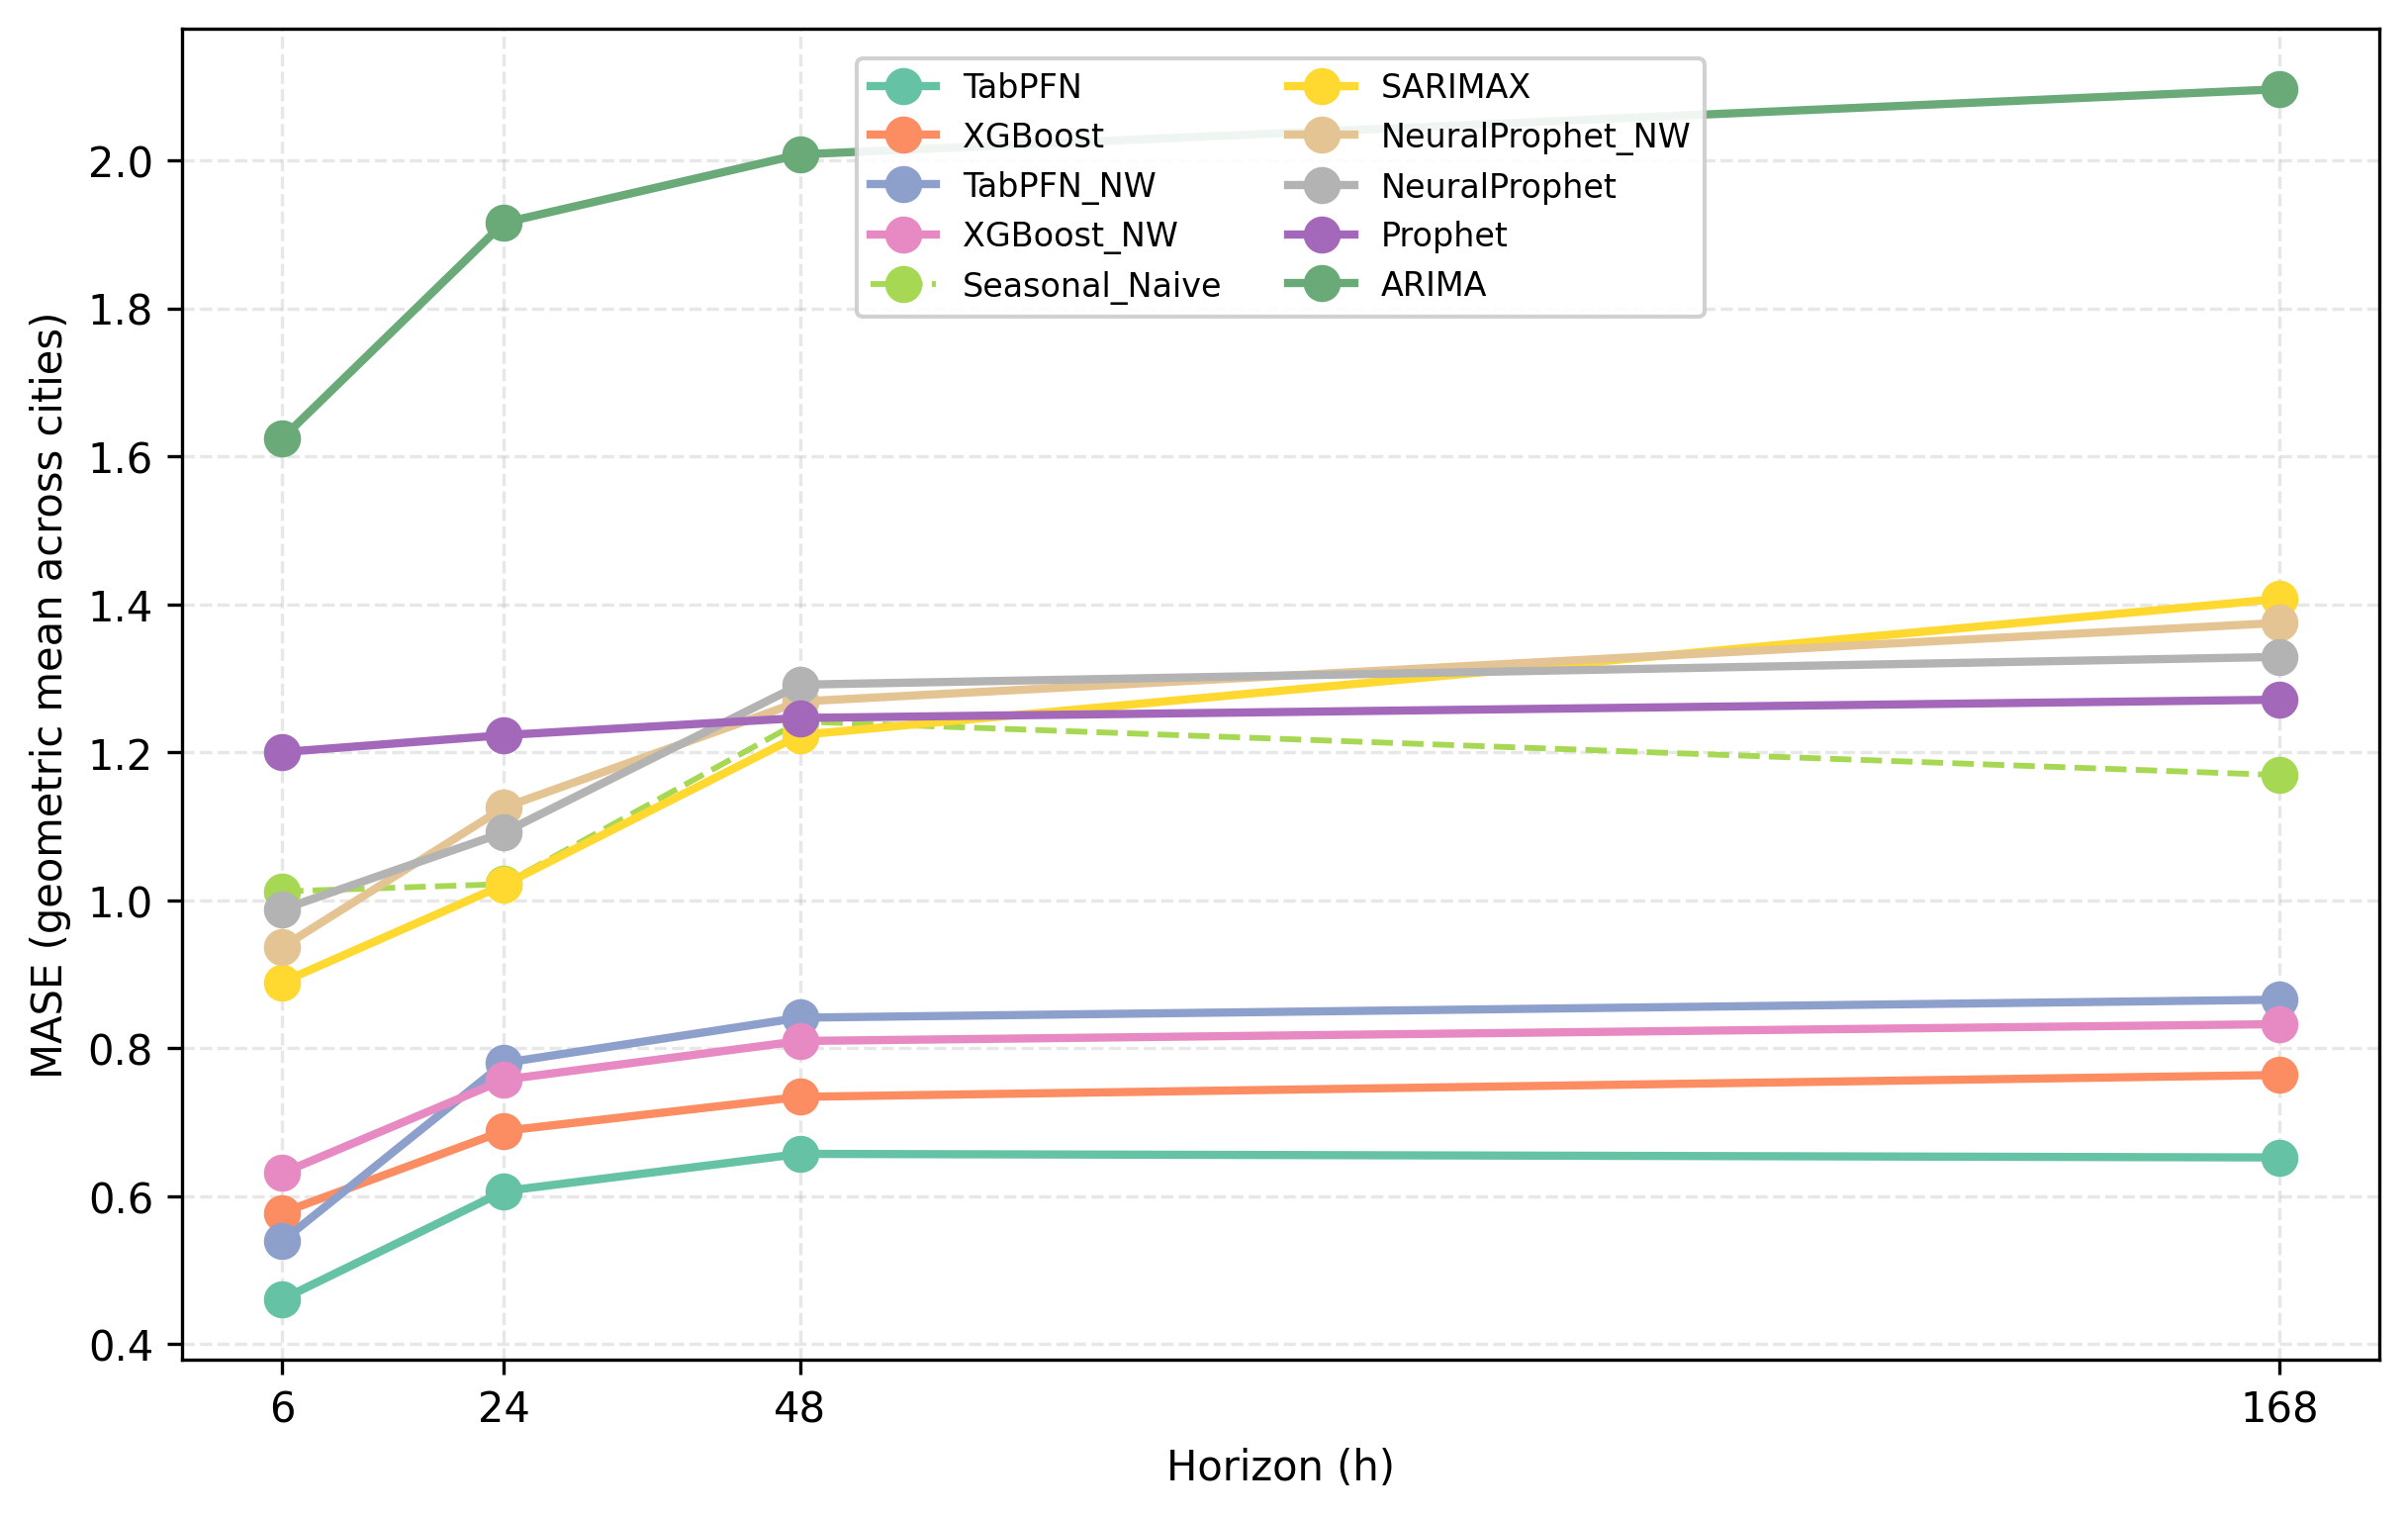

Saved → figC5_mase_by_horizon.png


In [21]:
# Figure CX — Cross-City MASE by Horizon (single panel)

city_avg_mase = (
    df_all_clean
    .groupby(['model', 'horizon'], as_index=False)['MASE_mean']
    .agg(gm)                        # geometric mean across cities
)

available_m = [m for m in MODEL_ORDER_RANKED if m in city_avg_mase['model'].unique()]
horizons_m  = sorted(city_avg_mase['horizon'].astype(int).unique())

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)

for model in available_m:
    idx = MODEL_ORDER_RANKED.index(model)
    md  = city_avg_mase[city_avg_mase['model'] == model].sort_values('horizon')
    ax.plot(
        md['horizon'].astype(int), md['MASE_mean'],
        marker='o', label=dn(model),
        color=colors[idx % len(colors)],
        linestyle='--' if model == 'Seasonal_Naive' else '-',
        linewidth=1.4  if model == 'Seasonal_Naive' else 2.0,
    )

ax.set_xlabel('Horizon (h)')
ax.set_ylabel('MASE (geometric mean across cities)')
ax.set_xticks(horizons_m)
ax.grid(True, alpha=0.3, linestyle='--')
# ax.set_title(
    # 'Cross-City: MASE by Forecast Horizon', fontsize=10
# )
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 0.99), ncol=2,
          framealpha=0.9, fontsize=8)

fig.savefig('../results_v7/figures/cross_city/figC5_mase_by_horizon.png',
            dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)
print('Saved → figC5_mase_by_horizon.png')

### 3.5 Weather Degradation Impact — Cross-City (MASE, equal-weighting)

One calculation feeds both the summary table and the bar chart below, so they cannot diverge. Percentage change is computed per (city, horizon) cell first, then averaged with equal weight — see changelog note above.


        model  Clean_MASE  Degraded_MASE  Increase_abs  Increase_pct
      XGBoost       0.687          0.703         0.016           2.3
      SARIMAX       1.118          1.148         0.030           2.7
NeuralProphet       1.166          1.231         0.065           5.5
       TabPFN       0.588          0.629         0.041           6.9


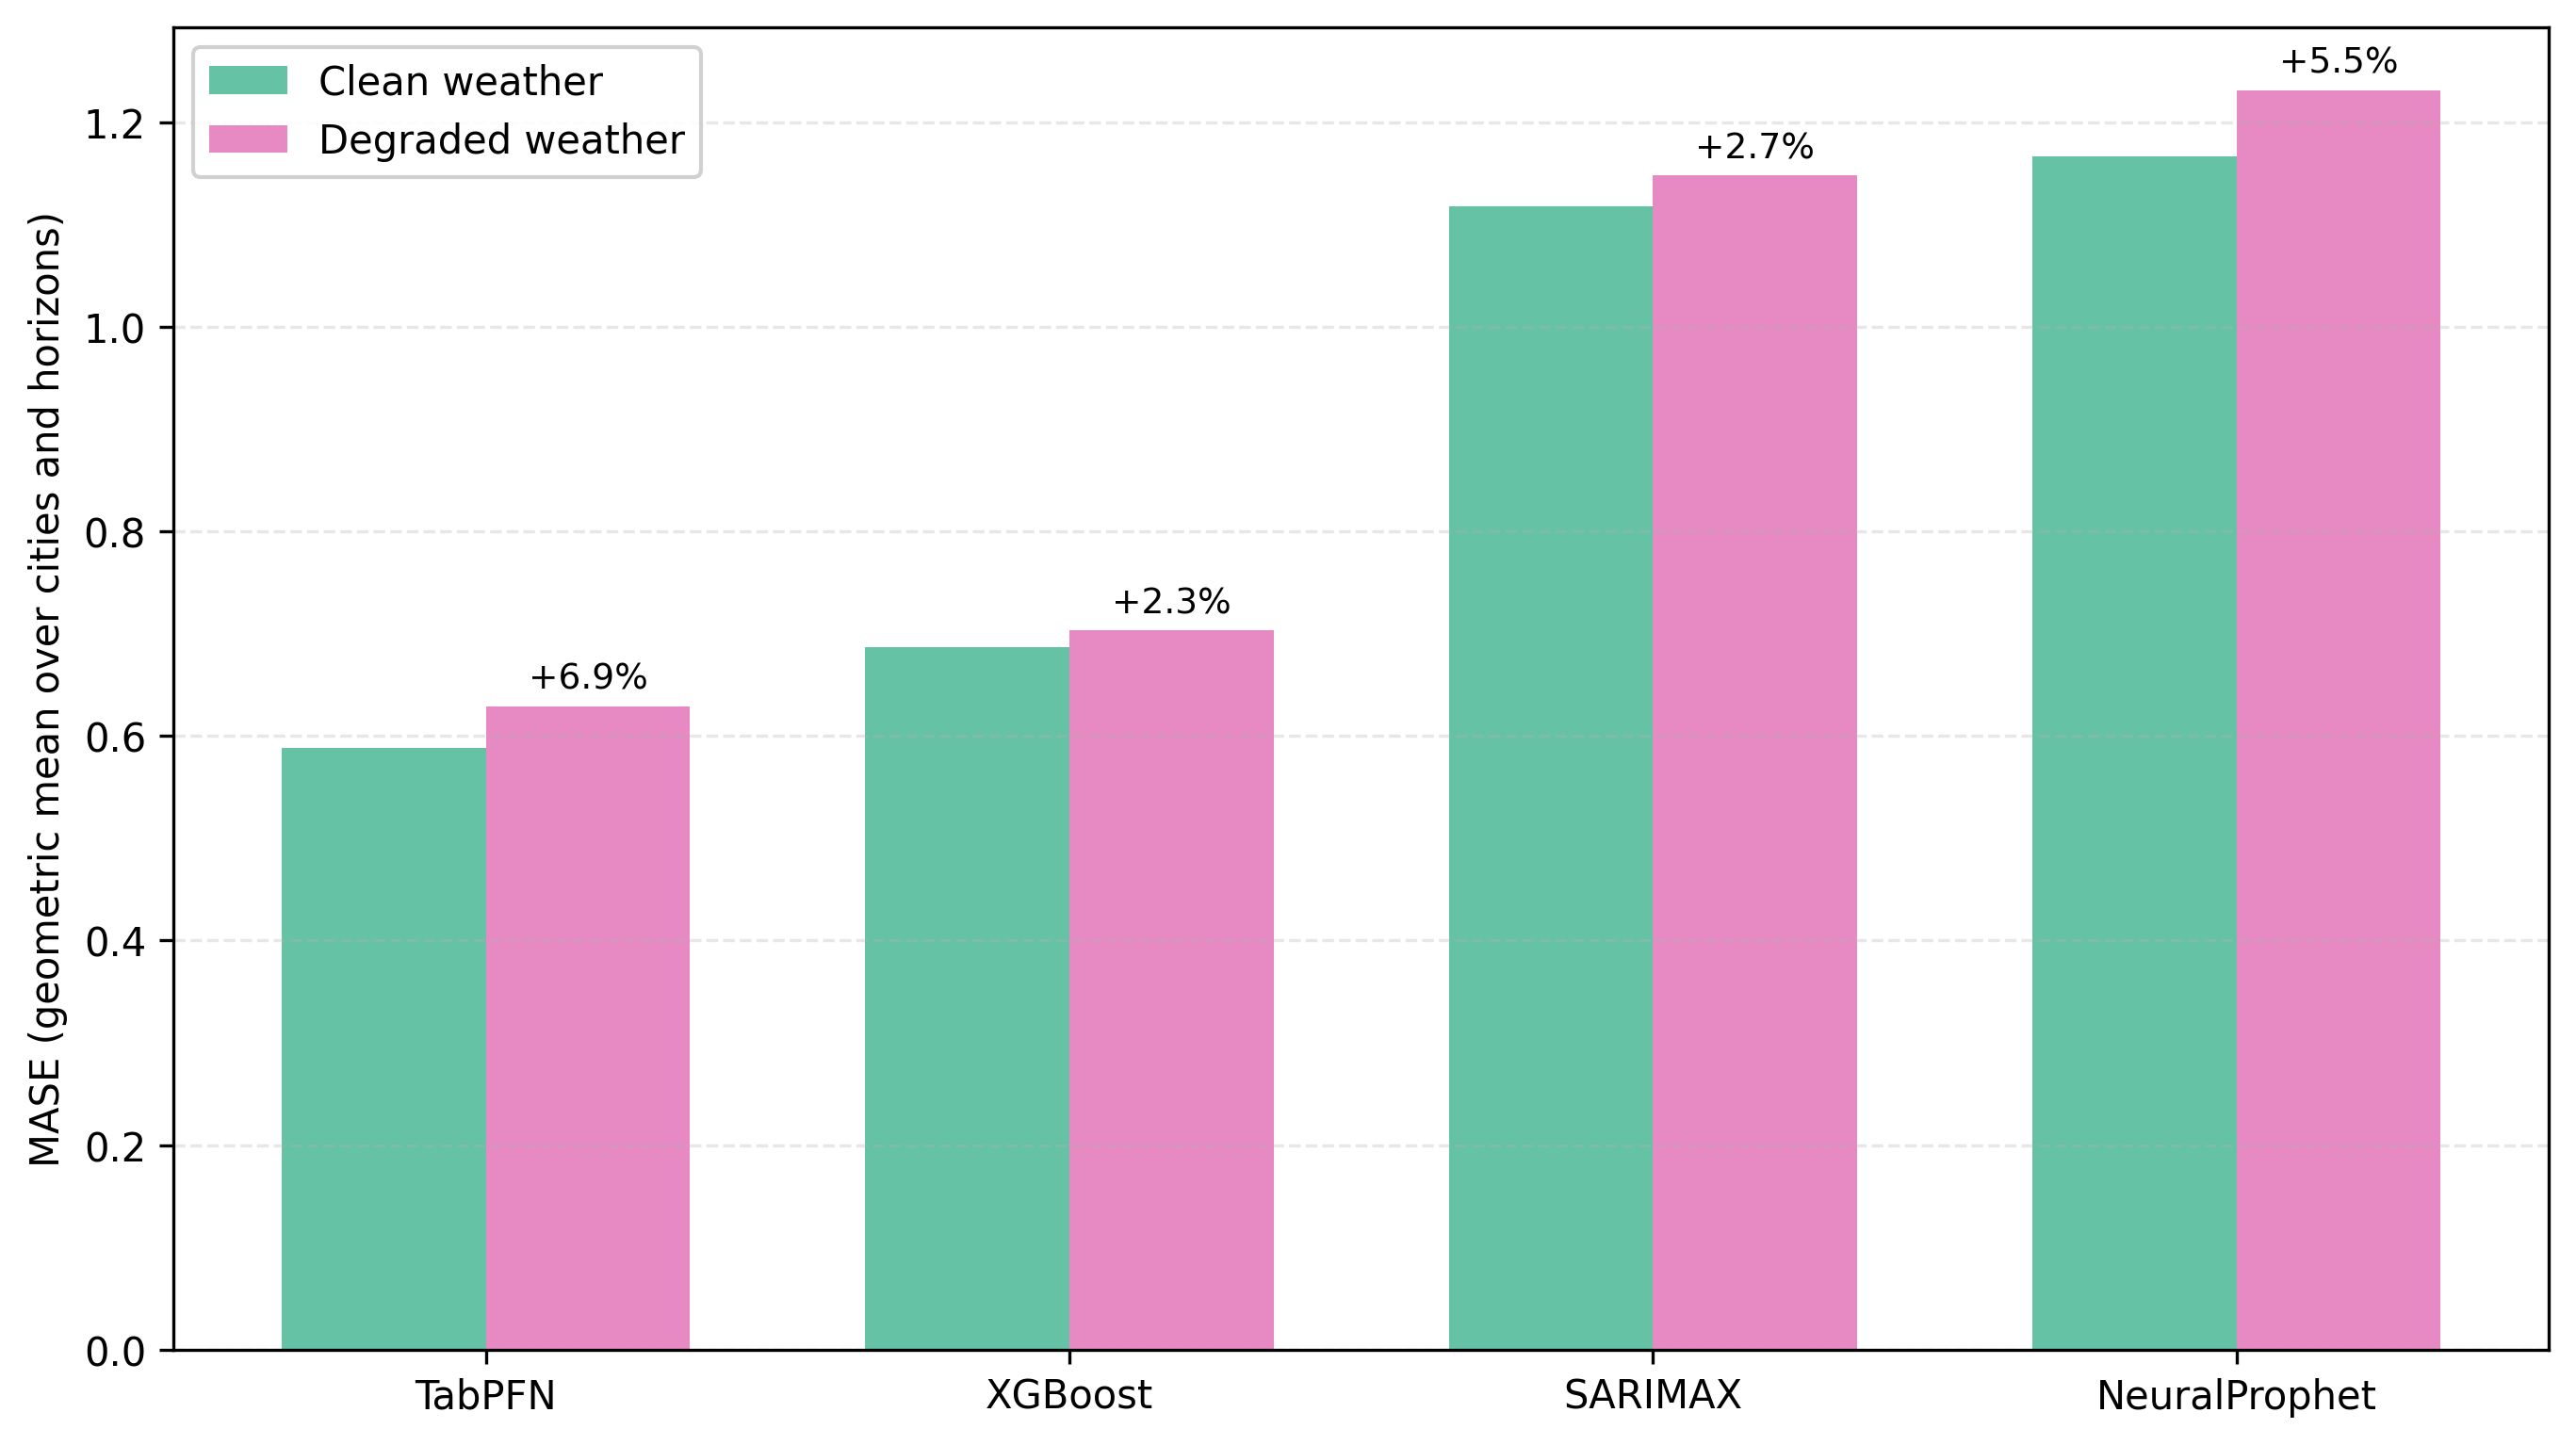

In [22]:
# ── 3.5 Weather Degradation Impact — Cross-City (MASE, equal-weighting) ──
# One calculation feeds both the table and the figure below, so they
# cannot diverge. Supersedes the old separate Fig C6 / Table C4 cells.
#
# Ratio computed per (city, horizon) cell first, then aggregated across
# cells with a geometric mean (Davydenko & Fildes, 2013) — not pooled MASE,
# not an arithmetic mean of percentages.

deg_rows = []
for model in WEATHER_MODELS:
    for ds in DATASETS:
        for h in sorted(df_all_clean['horizon'].unique()):
            c_row = df_all_clean[(df_all_clean['dataset']==ds) & (df_all_clean['model']==model) & (df_all_clean['horizon']==h)]
            d_row = df_all_degraded[(df_all_degraded['dataset']==ds) & (df_all_degraded['model']==model) & (df_all_degraded['horizon']==h)]
            if c_row.empty or d_row.empty:
                continue
            c_val = c_row['MASE_mean'].values[0]
            d_val = d_row['MASE_mean'].values[0]
            deg_rows.append({'model': model, 'dataset': ds, 'horizon': h,
                              'Clean': c_val, 'Degraded': d_val,
                              'ratio': d_val / c_val})

deg_cells_df = pd.DataFrame(deg_rows)

# Equal-weight summary: ratio per (city, horizon) cell first, geometric mean second
deg_summary = (
    deg_cells_df.groupby('model')
    .agg(Clean_MASE=('Clean', gmean), Degraded_MASE=('Degraded', gmean),
         geo_mean_ratio=('ratio', gmean))
    .reset_index()
)

# Compute derived columns from full-precision values before any rounding,
# so the abs/pct increase always agrees exactly with Clean/Degraded MASE.
deg_summary['Increase_abs'] = deg_summary['Degraded_MASE'] - deg_summary['Clean_MASE']
# gmean(Degraded)/gmean(Clean) == gmean(Degraded/Clean), so this equals Degraded_MASE/Clean_MASE - 1 exactly
deg_summary['Increase_pct'] = (deg_summary['geo_mean_ratio'] - 1) * 100

# Round for display: MASE-scale columns to 3 dp (consistent with the rest
# of the cross-city tables), percentage to 1 dp.
deg_summary[['Clean_MASE', 'Degraded_MASE', 'Increase_abs']] = \
    deg_summary[['Clean_MASE', 'Degraded_MASE', 'Increase_abs']].round(3)
deg_summary['Increase_pct'] = deg_summary['Increase_pct'].round(1)

deg_summary = deg_summary.drop(columns='geo_mean_ratio').sort_values('Increase_pct')

print(deg_summary.to_string(index=False))
deg_summary.to_csv('../results_v7/tables/cross_city/tableC4_degradation_mase.csv', index=False)

# Bar chart — reuses deg_summary directly, so table and figure always match
models_plot = [m for m in MODEL_ORDER_RANKED if m in deg_summary['model'].values]
x = np.arange(len(models_plot)); width = 0.35
clean_v = [deg_summary[deg_summary['model']==m]['Clean_MASE'].values[0] for m in models_plot]
deg_v   = [deg_summary[deg_summary['model']==m]['Degraded_MASE'].values[0] for m in models_plot]
pct_v   = [deg_summary[deg_summary['model']==m]['Increase_pct'].values[0] for m in models_plot]

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
bars1 = ax.bar(x - width/2, clean_v, width, label='Clean weather', color=colors[0])
bars2 = ax.bar(x + width/2, deg_v,   width, label='Degraded weather', color=colors[3])
for b, pct in zip(bars2, pct_v):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.01, f'{pct:+.1f}%', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('MASE (geometric mean over cities and horizons)'); ax.set_xticks(x); ax.set_xticklabels([dn(m) for m in models_plot])
ax.legend(framealpha=0.9); ax.grid(axis='y', alpha=0.3, linestyle='--')
fig.savefig('../results_v7/figures/cross_city/figC6_degradation_mase_bars.png', dpi=300, bbox_inches='tight')
plt.show(); plt.close(fig)


Note: Clean_MASE and Degraded_MASE are geometric means over all (city, horizon) cells. Increase % is the geometric mean of the per-cell Degraded/Clean ratios, which equals Degraded_MASE / Clean_MASE − 1 exactly, so table, bars and labels agree.


### 3.6 TabPFN Weather-Covariate Impact by Horizon (Cross-City)

MASE columns: geometric mean over cities. Improvement %: 1 − geometric mean of the per-city ratios (= 1 − ratio of the two MASE columns). Last row: over all 12 city–horizon tasks.


In [23]:
# ── 3.6 TabPFN Weather-Covariate Impact by Horizon (Cross-City) ──
# MASE columns: geometric mean over cities. Improvement_%: 1 - gm(per-city ratio),
# which equals 1 - TabPFN / TabPFN_NoWeather of the two printed columns.
# Last row: the same over all 12 (city, horizon) tasks.
MODEL_A  = "TabPFN"
MODEL_B  = "TabPFN_NoWeather"
SCENARIO = "clean_only"
HORIZONS = [6, 24, 48, 168]

src = df_agg[df_agg['weather_scenario'] == SCENARIO]
rows, missing, all_a, all_b = [], [], [], []

for h in HORIZONS:
    a_vals, b_vals = {}, {}
    for ds in DATASETS:
        a_row = src[(src['dataset'] == ds) & (src['model'] == MODEL_A) & (src['horizon'] == h)]
        b_row = src[(src['dataset'] == ds) & (src['model'] == MODEL_B) & (src['horizon'] == h)]
        if a_row.empty or b_row.empty:
            missing.append((ds, h, MODEL_A if a_row.empty else MODEL_B))
            continue
        a_vals[ds] = a_row['MASE_mean'].values[0]
        b_vals[ds] = b_row['MASE_mean'].values[0]

    if len(a_vals) < len(DATASETS):
        print(f"⚠ Horizon {h}: only {len(a_vals)}/{len(DATASETS)} cities available — row skipped")
        continue

    a, b = pd.Series(a_vals), pd.Series(b_vals)
    ga, gb = gm(a), gm(b)
    rows.append({'Horizon': h, MODEL_A: ga, MODEL_B: gb,
                 'Improvement': gb - ga, 'Improvement_%': -gm_change_pct(a, b)})
    all_a.extend(a.values)
    all_b.extend(b.values)

if missing:
    print("⚠ MISSING (model, city, horizon) combinations — NOT filled:")
    for ds, h, m in missing:
        print(f"   {m} / {ds} / h={h}")

tabpfn_weather_by_horizon = pd.DataFrame(rows)
ga, gb = gm(all_a), gm(all_b)
mean_row = {'Horizon': 'Geo. mean', MODEL_A: ga, MODEL_B: gb,
            'Improvement': gb - ga, 'Improvement_%': -gm_change_pct(all_a, all_b)}

_all = pd.concat([tabpfn_weather_by_horizon, pd.DataFrame([mean_row])], ignore_index=True)
assert np.allclose(_all['Improvement_%'].astype(float),
                   (1 - _all[MODEL_A].astype(float) / _all[MODEL_B].astype(float)) * 100), \
    "Improvement_% does not equal 1 - TabPFN / TabPFN_NoWeather"

tabpfn_weather_by_horizon_export = _all.round(3)
print("\n" + tabpfn_weather_by_horizon_export.to_string(index=False))

TAB = lambda name: f'../results_v7/tables/cross_city/{name}'
tabpfn_weather_by_horizon_export.to_csv(TAB('tableC5_tabpfn_weather_by_horizon.csv'), index=False)

tex  = "\\begin{table}\n\\centering\n"
tex += "\\caption{Impact of weather information on TabPFN performance across horizons "
tex += "(MASE, geometric mean over cities; last row: over all city--horizon combinations).}\n"
tex += "\\label{tab:tabpfn_weather_cross_city_by_horizon}\n"
tex += "\\begin{tabular}{crrrr}\n\\toprule\n"
tex += "Horizon & TabPFN & TabPFN\\_NoWeather & Improvement & Improvement \\% \\\\\n"
tex += "\\midrule\n"
for _, row in tabpfn_weather_by_horizon.iterrows():
    tex += (f"{int(row['Horizon'])} & {row['TabPFN']:.3f} & {row['TabPFN_NoWeather']:.3f} "
            f"& {row['Improvement']:.3f} & {row['Improvement_%']:.3f} \\\\\n")
tex += "\\midrule\n"
mr = mean_row
tex += (f"Geo.\\ mean & {mr['TabPFN']:.3f} & {mr['TabPFN_NoWeather']:.3f} "
        f"& {mr['Improvement']:.3f} & {mr['Improvement_%']:.3f} \\\\\n")
tex += "\\bottomrule\n\\end{tabular}\n\\end{table}\n"
with open(TAB('tableC5_tabpfn_weather_by_horizon.tex'), 'w') as f:
    f.write(tex)
print(f"\nSaved: {TAB('tableC5_tabpfn_weather_by_horizon.csv')}")
print(f"Saved: {TAB('tableC5_tabpfn_weather_by_horizon.tex')}")



  Horizon  TabPFN  TabPFN_NoWeather  Improvement  Improvement_%
        6   0.461             0.539        0.079         14.562
       24   0.607             0.780        0.173         22.212
       48   0.657             0.841        0.184         21.878
      168   0.652             0.866        0.213         24.634
Geo. mean   0.588             0.744        0.156         20.909

Saved: ../results_v7/tables/cross_city/tableC5_tabpfn_weather_by_horizon.csv
Saved: ../results_v7/tables/cross_city/tableC5_tabpfn_weather_by_horizon.tex


### 3.7 Clean vs Degraded MASE by Horizon — TabPFN & XGBoost (Cross-City)

Same method as 3.6 (geometric means; percentage per task first).


In [24]:
# ── 3.7 Clean vs Degraded MASE by Horizon — TabPFN & XGBoost (Cross-City) ──
# Clean / Degraded: geometric mean over cities. Degraded_%: gm(per-city ratio) - 1,
# which equals Degraded / Clean - 1 of the two printed columns.
# Last row: the same over all 12 (city, horizon) tasks.
MODELS   = ["TabPFN", "XGBoost"]
HORIZONS = [6, 24, 48, 168]

src_c = df_agg[df_agg['weather_scenario'] == 'clean_only']
src_d = df_agg[df_agg['weather_scenario'] == 'degraded']

rows, missing = [], []
all_c = {model: [] for model in MODELS}
all_d = {model: [] for model in MODELS}

for h in HORIZONS:
    row_data = {'Horizon': h}
    row_ok = True

    for model in MODELS:
        c_vals, d_vals = {}, {}
        for ds in DATASETS:
            c_row = src_c[(src_c['dataset'] == ds) & (src_c['model'] == model) & (src_c['horizon'] == h)]
            d_row = src_d[(src_d['dataset'] == ds) & (src_d['model'] == model) & (src_d['horizon'] == h)]
            if c_row.empty or d_row.empty:
                missing.append((ds, h, model, 'clean' if c_row.empty else 'degraded'))
                continue
            c_vals[ds] = c_row['MASE_mean'].values[0]
            d_vals[ds] = d_row['MASE_mean'].values[0]

        if len(c_vals) < len(DATASETS):
            print(f"⚠ Horizon {h}, {model}: only {len(c_vals)}/{len(DATASETS)} cities available — row skipped")
            row_ok = False
            continue

        c, d = pd.Series(c_vals), pd.Series(d_vals)
        row_data[f'{model}_Clean']      = gm(c)
        row_data[f'{model}_Degraded']   = gm(d)
        row_data[f'{model}_Degraded_%'] = gm_change_pct(d, c)
        all_c[model].extend(c.values)
        all_d[model].extend(d.values)

    if row_ok:
        rows.append(row_data)

if missing:
    print("⚠ MISSING (model, city, horizon, scenario) combinations — NOT filled:")
    for ds, h, m, sc in missing:
        print(f"   {m} / {ds} / h={h} / {sc}")

degradation_tabpfn_xgb_by_horizon = pd.DataFrame(rows)

mean_row = {'Horizon': 'Geo. mean'}
for model in MODELS:
    mean_row[f'{model}_Clean']      = gm(all_c[model])
    mean_row[f'{model}_Degraded']   = gm(all_d[model])
    mean_row[f'{model}_Degraded_%'] = gm_change_pct(all_d[model], all_c[model])

_all = pd.concat([degradation_tabpfn_xgb_by_horizon, pd.DataFrame([mean_row])], ignore_index=True)
for model in MODELS:
    assert np.allclose(_all[f'{model}_Degraded_%'].astype(float),
                       (_all[f'{model}_Degraded'].astype(float) / _all[f'{model}_Clean'].astype(float) - 1) * 100), \
        f"{model}: Degraded_% does not equal Degraded / Clean - 1"

degradation_tabpfn_xgb_by_horizon_export = _all.round(3)
print("\n" + degradation_tabpfn_xgb_by_horizon_export.to_string(index=False))

TAB = lambda name: f'../results_v7/tables/cross_city/{name}'
degradation_tabpfn_xgb_by_horizon_export.to_csv(TAB('tableC6_degradation_tabpfn_xgboost_by_horizon.csv'), index=False)

def fmt_deg(val, pct):
    return f"{val:.3f} ({pct:+.1f}\\%)"

tex  = "\\begin{table}\n\\centering\n"
tex += "\\caption{Weather degradation impact on TabPFN and XGBoost across horizons "
tex += "(MASE, geometric mean over cities; last row: over all city--horizon combinations).}\n"
tex += "\\label{tab:degradation_tabpfn_xgboost_by_horizon}\n"
tex += "\\begin{tabular}{crrrr}\n\\toprule\n"
tex += "Horizon & TabPFN Clean & TabPFN Degraded (\\%) & XGBoost Clean & XGBoost Degraded (\\%) \\\\\n"
tex += "\\midrule\n"
for _, row in degradation_tabpfn_xgb_by_horizon.iterrows():
    tex += (f"{int(row['Horizon'])} & {row['TabPFN_Clean']:.3f} "
            f"& {fmt_deg(row['TabPFN_Degraded'], row['TabPFN_Degraded_%'])} "
            f"& {row['XGBoost_Clean']:.3f} "
            f"& {fmt_deg(row['XGBoost_Degraded'], row['XGBoost_Degraded_%'])} \\\\\n")
tex += "\\midrule\n"
mr = mean_row
tex += (f"Geo.\\ mean & {mr['TabPFN_Clean']:.3f} "
        f"& {fmt_deg(mr['TabPFN_Degraded'], mr['TabPFN_Degraded_%'])} "
        f"& {mr['XGBoost_Clean']:.3f} "
        f"& {fmt_deg(mr['XGBoost_Degraded'], mr['XGBoost_Degraded_%'])} \\\\\n")
tex += "\\bottomrule\n\\end{tabular}\n\\end{table}\n"
with open(TAB('tableC6_degradation_tabpfn_xgboost_by_horizon.tex'), 'w') as f:
    f.write(tex)
print(f"\nSaved: {TAB('tableC6_degradation_tabpfn_xgboost_by_horizon.csv')}")
print(f"Saved: {TAB('tableC6_degradation_tabpfn_xgboost_by_horizon.tex')}")



  Horizon  TabPFN_Clean  TabPFN_Degraded  TabPFN_Degraded_%  XGBoost_Clean  XGBoost_Degraded  XGBoost_Degraded_%
        6         0.461            0.496              7.700          0.578             0.591               2.331
       24         0.607            0.638              5.178          0.688             0.703               2.136
       48         0.657            0.694              5.657          0.734             0.747               1.805
      168         0.652            0.712              9.074          0.764             0.786               2.925
Geo. mean         0.588            0.629              6.890          0.687             0.703               2.298

Saved: ../results_v7/tables/cross_city/tableC6_degradation_tabpfn_xgboost_by_horizon.csv
Saved: ../results_v7/tables/cross_city/tableC6_degradation_tabpfn_xgboost_by_horizon.tex


### 3.8 MASE by City × Horizon — Top Models vs Baseline

No aggregation — each cell is a single (city, horizon, model) `MASE_mean` value read directly from the data.


In [25]:
# ── 3.8 MASE by City × Horizon — Top Models vs Baseline ──
MODELS_38 = ["TabPFN", "XGBoost", "TabPFN_NoWeather", "Seasonal_Naive"]
CITIES_38 = list(DATASETS)
HORIZONS  = [6, 24, 48, 168]

rows, missing = [], []

for model in MODELS_38:
    row = {'Model': model}
    for city in CITIES_38:
        df_city  = filter_results(df_agg, RESULTS_VERSION, city)
        df_clean = df_city[df_city['weather_scenario'] == 'clean_only']

        for h in HORIZONS:
            cell = df_clean[(df_clean['model'] == model) & (df_clean['horizon'] == h)]
            col_name = f"{city}_{h}"
            if cell.empty:
                row[col_name] = None
                missing.append((model, city, h))
            else:
                row[col_name] = round(cell['MASE_mean'].values[0], 3)
    rows.append(row)

if missing:
    print("⚠ MISSING (model, city, horizon) combinations — NOT filled:")
    for model, city, h in missing:
        print(f"   {model} / {city} / h={h}")

mase_by_city_horizon_top_models = pd.DataFrame(rows).set_index('Model').loc[MODELS_38]
col_order_38 = [f"{city}_{h}" for city in CITIES_38 for h in HORIZONS]
mase_by_city_horizon_top_models = mase_by_city_horizon_top_models[col_order_38]

print("\n" + mase_by_city_horizon_top_models.to_string())

TAB = lambda name: f'../results_v7/tables/cross_city/{name}'
mase_by_city_horizon_top_models.to_csv(TAB('tableC7_mase_by_city_horizon.csv'))

tex  = "\\begin{table}[ht!]\n\\centering\n"
tex += "\\caption{MASE by city and horizon (clean weather) — TabPFN, XGBoost, "
tex += "TabPFN\\_NoWeather, Seasonal\\_Naive.}\n"
tex += "\\label{tab:mase_by_city_horizon}\n"
tex += "{\\small\n\\setlength{\\tabcolsep}{3pt}\n\\scriptsize\n"
tex += "\\begin{tabular}{l" + "r" * len(col_order_38) + "}\n\\toprule\n"
tex += "Model"
for city in CITIES_38:
    tex += f" & \\multicolumn{{{len(HORIZONS)}}}{{c}}{{{city.capitalize()}}}"
tex += " \\\\\n"
tex += " "
for city in CITIES_38:
    for h in HORIZONS:
        tex += f" & {h}h"
tex += " \\\\\n\\midrule\n"
for model in MODELS_38:
    tex += model.replace('_', '\\_')
    for col in col_order_38:
        val = mase_by_city_horizon_top_models.loc[model, col]
        tex += f" & {val:.3f}" if pd.notna(val) else " & —"
    tex += " \\\\\n"
tex += "\\bottomrule\n\\end{tabular}\n}\n\\end{table}\n"
with open(TAB('tableC7_mase_by_city_horizon.tex'), 'w') as f:
    f.write(tex)
print(f"\nSaved: {TAB('tableC7_mase_by_city_horizon.csv')}")
print(f"Saved: {TAB('tableC7_mase_by_city_horizon.tex')}")



                  seoul_6  seoul_24  seoul_48  seoul_168  london_6  london_24  london_48  london_168  washington_6  washington_24  washington_48  washington_168
Model                                                                                                                                                           
TabPFN              0.502     0.668     0.736      0.787     0.436      0.594      0.631       0.609         0.446          0.563          0.611           0.579
XGBoost             0.644     0.812     0.885      1.001     0.543      0.629      0.656       0.675         0.551          0.639          0.681           0.659
TabPFN_NoWeather    0.633     0.971     1.104      1.200     0.492      0.714      0.756       0.766         0.503          0.685          0.713           0.706
Seasonal_Naive      1.070     1.082     1.244      1.230     1.005      1.018      1.263       1.196         0.964          0.969          1.218           1.086

Saved: ../results_v7/tables/cros

### 3.9 Additions for the paper (v7)

Degraded MASE per task (Table C8) and TabPFN vs XGBoost in both weather cases. Run after Sections 1-3.

In [26]:
# ── 3.9 Additions for the paper (v7) ─────────────────────────────────────────
# (a) degraded MASE per city x horizon  (b) TabPFN vs XGBoost, both weather cases
# Uses df_all_clean, df_all_degraded (Section 3) and pct_better_geo (cell above).
OUT_39 = Path('../results_v7/tables/cross_city')
WM_39  = ['TabPFN', 'XGBoost']

# (a)
deg_cells = (df_all_degraded[df_all_degraded['model'].isin(WM_39)]
             .pivot_table(index='model', columns=['dataset', 'horizon'], values='MASE_mean')
             .reindex(columns=DATASETS, level=0))
deg_cells.round(3).to_csv(OUT_39 / 'tableC8_mase_degraded_by_city_horizon.csv')
print('(a) Degraded MASE per task')
print(deg_cells.round(3).to_string())
print('    tasks with MASE > 1:', {m: int((deg_cells.loc[m] > 1).sum()) for m in WM_39})
print('    geometric mean over tasks:', {m: round(gm(deg_cells.loc[m]), 3) for m in WM_39})

# (b) same direction as the clean headline: 1 - gmean(TabPFN / XGBoost)
print(f"\n(b) TabPFN better than XGBoost: clean {pct_better_geo('TabPFN', 'XGBoost'):.2f}% | "
      f"degraded {pct_better_geo('TabPFN', 'XGBoost', df=df_all_degraded):.2f}%")

print(f"\nSaved: tableC8_mase_degraded_by_city_horizon.csv in {OUT_39}")


(a) Degraded MASE per task
dataset  seoul                      london                      washington                    
horizon    6      24     48     168    6      24     48     168        6      24    48     168
model                                                                                         
TabPFN   0.541  0.704  0.804  0.905  0.470  0.624  0.651  0.652      0.480  0.592  0.64  0.611
XGBoost  0.665  0.836  0.908  1.040  0.556  0.645  0.667  0.696      0.559  0.644  0.69  0.671
    tasks with MASE > 1: {'TabPFN': 0, 'XGBoost': 1}
    geometric mean over tasks: {'TabPFN': 0.629, 'XGBoost': 0.703}

(b) TabPFN better than XGBoost: clean 14.38% | degraded 10.53%

Saved: tableC8_mase_degraded_by_city_horizon.csv in ../results_v7/tables/cross_city


In [27]:
#TODO: 3.10: add all models!!

Realistic setting (weather models with forecast weather, others without weather)
                  model weather_input  MASE  vs_SeasonalNaive_%  vs_NoWeather_% tasks_better_than_NoWeather  in_bar_chart
                 TabPFN      forecast 0.629               -43.2           -15.5                       12/12          True
                XGBoost      forecast 0.703               -36.5            -6.7                       12/12          True
       TabPFN_NoWeather          none 0.744               -32.8             NaN                         NaN          True
      XGBoost_NoWeather          none 0.753               -31.9             NaN                         NaN          True
         Seasonal_Naive          none 1.107                 0.0             NaN                         NaN         False
                SARIMAX      forecast 1.148                 3.8             NaN                         NaN         False
NeuralProphet_NoWeather          none 1.164                 5.2  

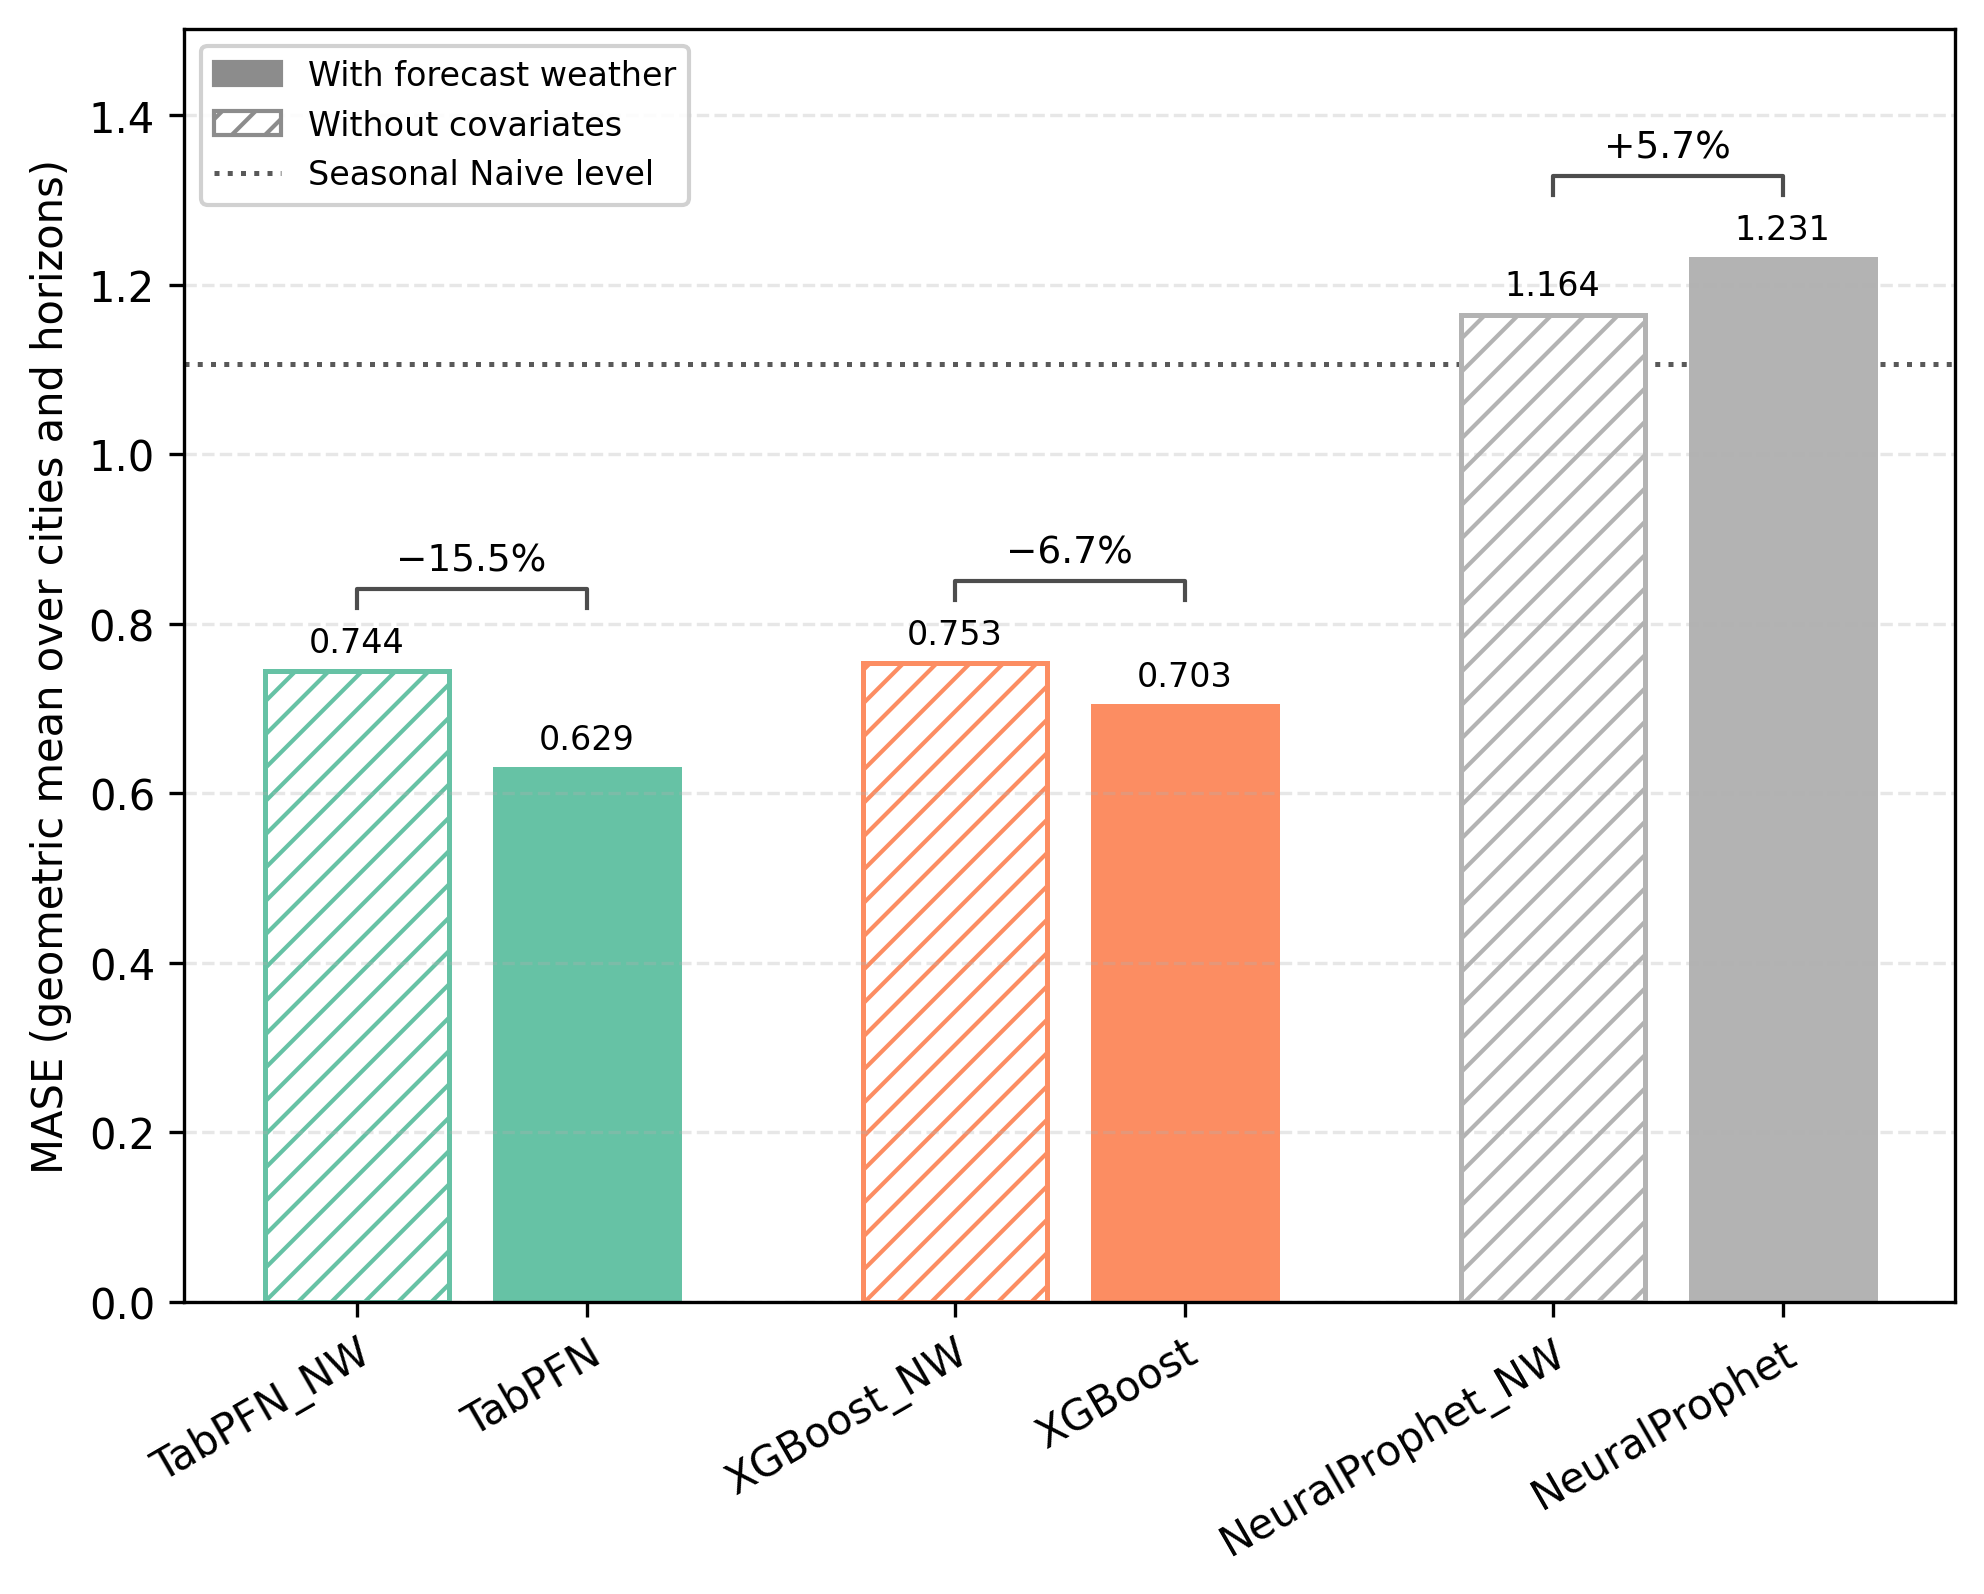

Saved: ../results_v7/figures/cross_city/figC7a_realistic_forecast_vs_noweather_bars.png, ../results_v7/figures/paper/fig_realistic_use_bars.pdf / .png


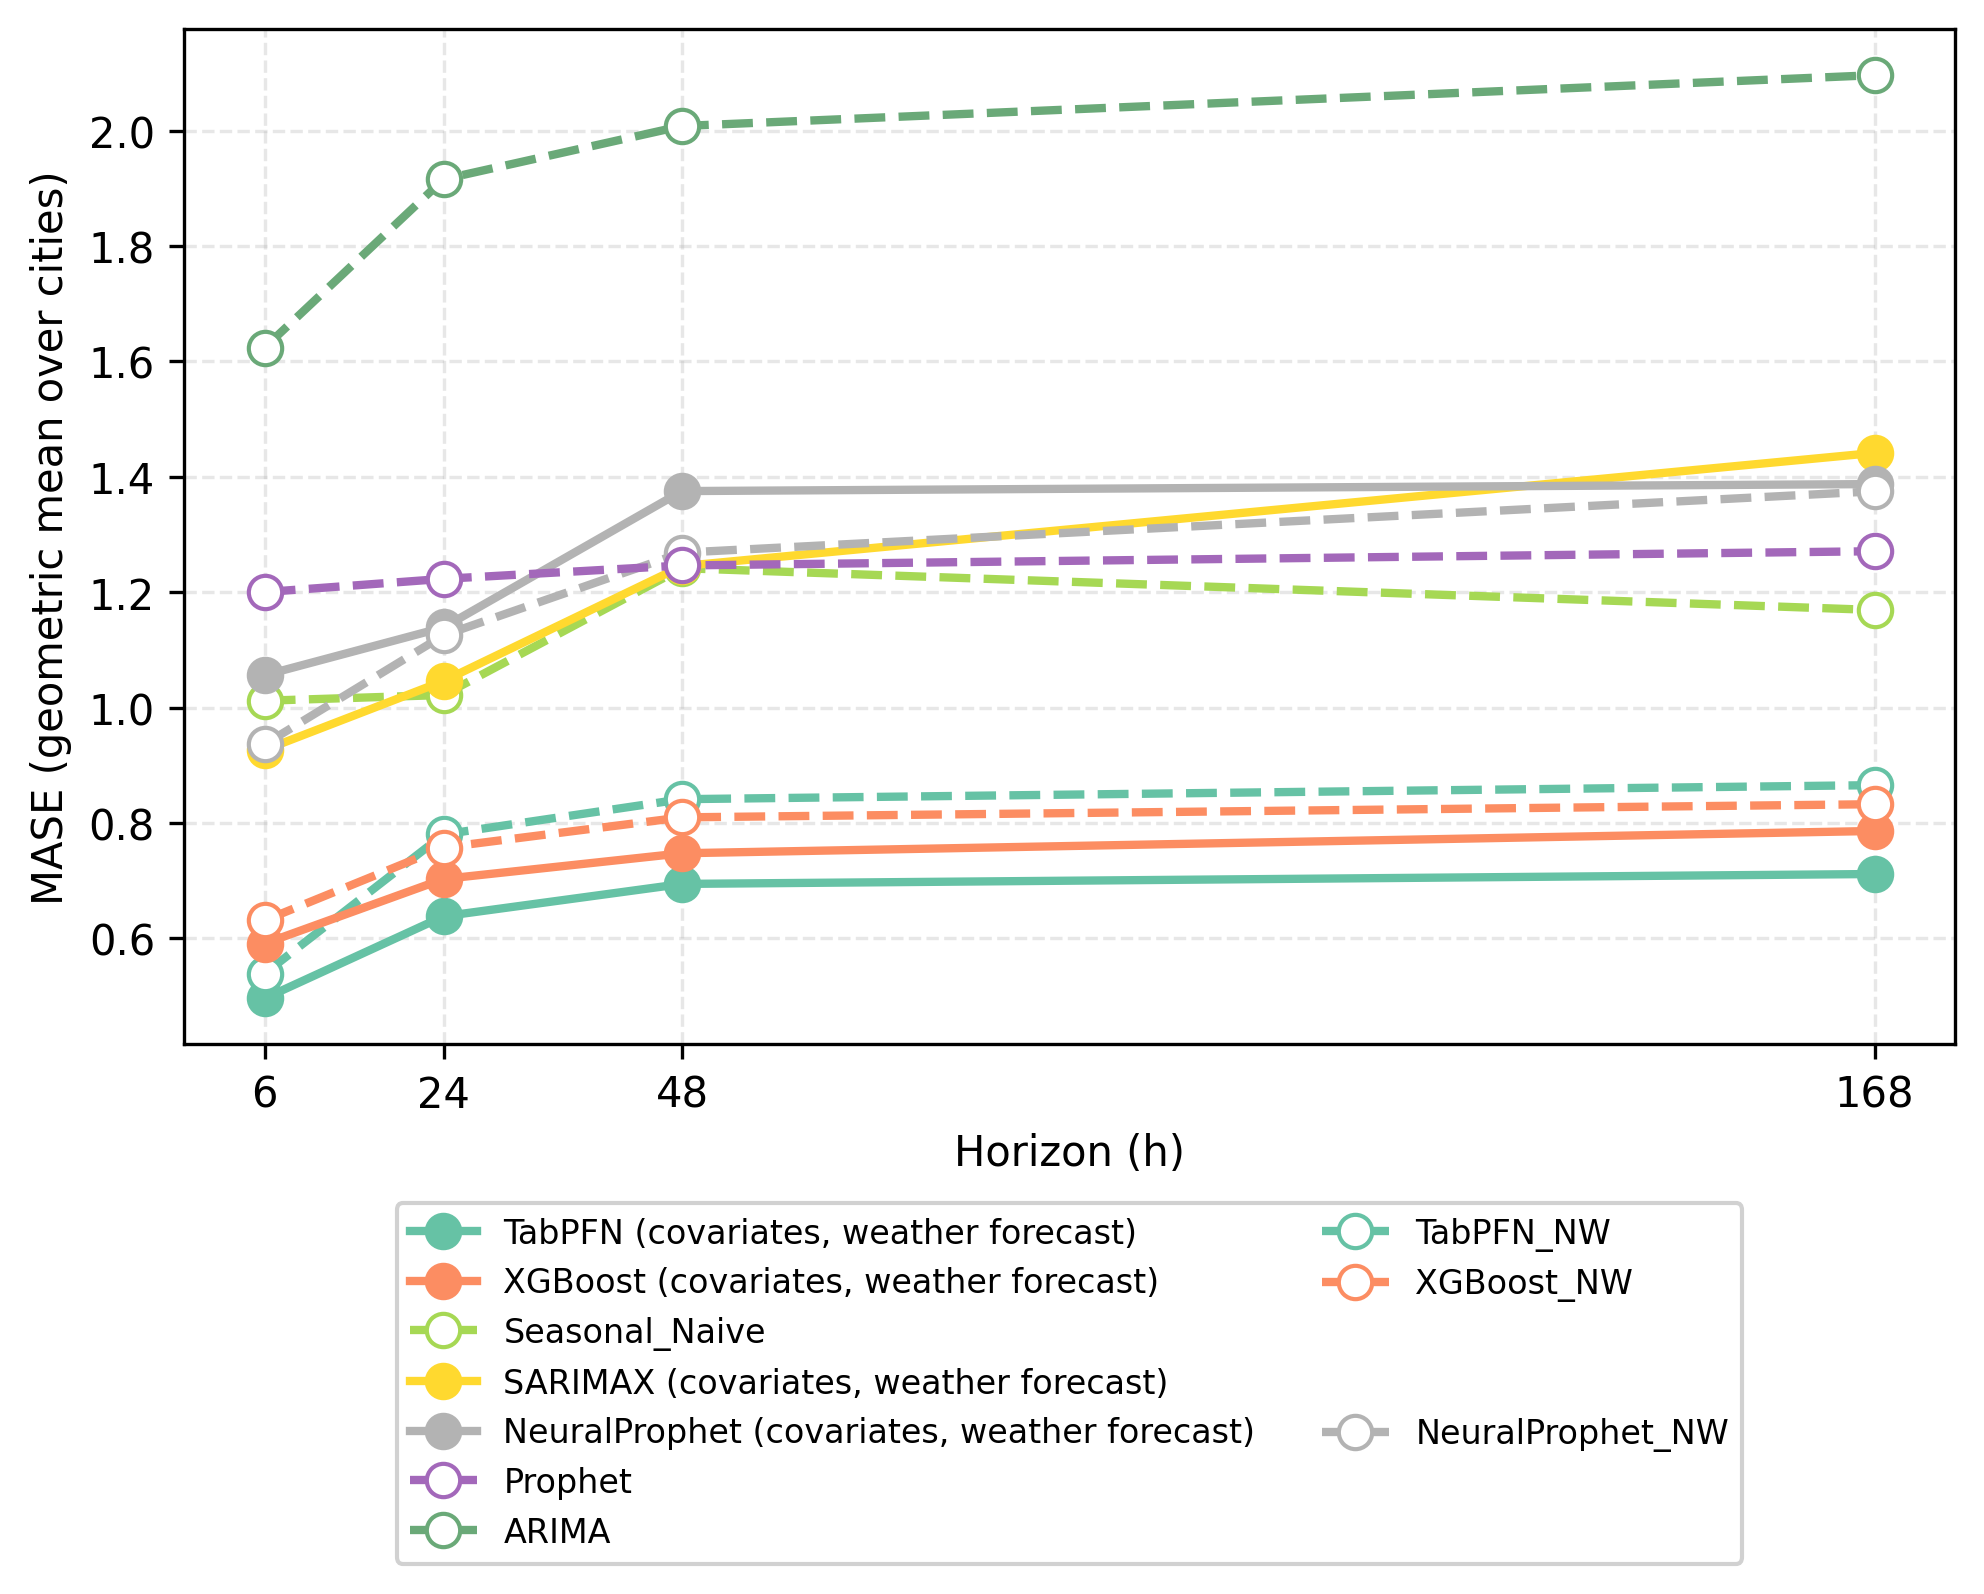

Saved: ../results_v7/figures/cross_city/figC7b_realistic_forecast_vs_noweather_by_horizon.png, ../results_v7/figures/paper/fig_realistic_use_by_horizon.pdf / .png
Saved: tableC10_realistic_forecast_vs_noweather.csv


In [28]:
# ── 3.10 Realistic use: weather forecast vs no weather (Cross-City) ──────────
# In practice a model gets either a weather FORECAST or no weather at all.
# Compared: covariate models with FORECAST weather ('degraded') vs no covariates.
# Bar chart (figC7a): only models with both variants (XGBoost, TabPFN, NeuralProphet).
# Line chart (figC7b): all models. Table/printout: all models.
# Each model is scored in the setting it would actually run in:
#   weather models    -> 'degraded'   (forecast weather)
#   no-weather models -> 'clean_only' (no covariates, identical in both scenarios)
# Aggregation as in 3.5: ratio per (city, horizon) task first, geometric mean
# second. Bars are geometric means over the same tasks, so the % labels equal
# bar_A / bar_B - 1 exactly.
# Uses df_all_clean, df_all_degraded (Section 3).
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

BASELINE       = 'Seasonal_Naive'
FIG_DIR        = '../results_v7/figures/cross_city'

def family(m):
    return m.replace('_NoWeather', '')

def fam_color(m):
    """Weather model and its _NoWeather twin share one colour (the weather model's)."""
    ref = family(m) if family(m) in MODEL_ORDER_RANKED else m
    return colors[MODEL_ORDER_RANKED.index(ref) % len(colors)]

def gm_ratio(a, b):
    """Geometric mean of a/b over the tasks both have, wins (a < b), n tasks."""
    r = (a / b).dropna()
    return gmean(r), int((r < 1).sum()), len(r)

# ── 1. Realistic MASE per (city, horizon) task ───────────────────────────────
dep = pd.concat([
    df_all_degraded[df_all_degraded['model'].isin(WEATHER_MODELS)],
    df_all_clean[~df_all_clean['model'].isin(WEATHER_MODELS)],
], ignore_index=True)
# one row per (city, horizon, model) -> pure reshape, no averaging
dep_mat = dep.pivot_table(index=['dataset', 'horizon'], columns='model',
                          values='MASE_mean', aggfunc='first')
H_310   = sorted(dep_mat.index.get_level_values('horizon').unique())

no_deg = [m for m in WEATHER_MODELS
          if m in df_all_clean['model'].unique() and m not in dep_mat.columns]
if no_deg:
    print(f"⚠ No degraded results for {no_deg} — left out")
short = dep_mat.columns[dep_mat.notna().sum() < len(dep_mat)].tolist()
if short:
    print(f"⚠ Not all {len(dep_mat)} tasks available for {short}")

# ── 2. Summary per model ─────────────────────────────────────────────────────
rows = []
for m in dep_mat.columns:
    row = {'model': m,
           'weather_input': 'forecast' if m in WEATHER_MODELS else 'none',
           'MASE': gmean(dep_mat[m].dropna()),
           'vs_SeasonalNaive_%': (gm_ratio(dep_mat[m], dep_mat[BASELINE])[0] - 1) * 100}
    nw = f'{m}_NoWeather'
    if m in WEATHER_MODELS and nw in dep_mat.columns:
        r, wins, n = gm_ratio(dep_mat[m], dep_mat[nw])
        row['vs_NoWeather_%'] = (r - 1) * 100
        row['tasks_better_than_NoWeather'] = f'{wins}/{n}'
        for h in H_310:
            t = dep_mat.xs(h, level='horizon')
            row[f'vs_NoWeather_%_h{h}'] = (gm_ratio(t[m], t[nw])[0] - 1) * 100
    rows.append(row)

summary_310 = pd.DataFrame(rows).sort_values('MASE').reset_index(drop=True)
# Plot only models with a with-covariates AND a without-covariates variant
PAIRS = [m for m in WEATHER_MODELS if m in dep_mat.columns and f'{m}_NoWeather' in dep_mat.columns]
summary_310['in_bar_chart'] = summary_310['model'].isin(PAIRS + [f'{m}_NoWeather' for m in PAIRS])

disp = summary_310.copy()
pct_cols = [c for c in disp.columns if '%' in c]
disp[pct_cols] = disp[pct_cols].round(1)
disp['MASE'] = disp['MASE'].round(3)
cols_print = [c for c in ['model', 'weather_input', 'MASE', 'vs_SeasonalNaive_%', 'vs_NoWeather_%',
                          'tasks_better_than_NoWeather', 'in_bar_chart'] if c in disp.columns]
print("Realistic setting (weather models with forecast weather, others without weather)")
print(disp[cols_print].to_string(index=False))
if 'vs_NoWeather_%' in summary_310.columns:
    print("\nWeather forecast vs no weather, MASE change by horizon (negative = forecast helps)")
    for _, r in summary_310.dropna(subset=['vs_NoWeather_%']).iterrows():
        print(f"  {r['model']:<14} all: {r['vs_NoWeather_%']:+.1f}% | " +
              ', '.join(f"h{h}: {r[f'vs_NoWeather_%_h{h}']:+.1f}%" for h in H_310))
dropped = summary_310.loc[~summary_310['in_bar_chart'], 'model'].tolist()
if dropped:
    print(f"\nNot in the bar chart (no with/without-covariates pair): {dropped}")
disp.to_csv('../results_v7/tables/cross_city/tableC10_realistic_forecast_vs_noweather.csv', index=False)

# ── 3. Plot layout ───────────────────────────────────────────────────────────
models_bar = summary_310.loc[summary_310['in_bar_chart'], 'model'].tolist()   # sorted by MASE
models_all = summary_310['model'].tolist()                                     # sorted by MASE
mase = summary_310.set_index('model')['MASE']
chg  = summary_310.set_index('model').get('vs_NoWeather_%')

def make_groups(models, nw_first=False):
    """family -> [covariate model (forecast weather), _NoWeather twin]; single models alone.
    nw_first=True: _NoWeather twin first."""
    g = {}
    for m in models:
        g.setdefault(family(m), []).append(m)
    for f in g:
        g[f].sort(key=lambda m: m.endswith('_NoWeather') != nw_first)
    return g

groups     = make_groups(models_bar, nw_first=True)   # bar chart: no covariates left, forecast weather right
groups_all = make_groups(models_all)                  # line chart

pos, x = {}, 0.0                              # bar positions, gap between families
for ms in groups.values():
    for m in ms:
        pos[m] = x; x += 1
    x += 0.6
ymax = max(mase[models_bar].max(), mase[BASELINE]) * 1.22

by_h = (dep[dep['model'].isin(models_all)]
        .groupby(['model', 'horizon'])['MASE_mean'].apply(gmean).unstack('horizon'))

def draw_bars(ax):
    """One bar per model: no covariates left, forecast weather right; bracket = MASE change
    from the left bar (no covariates) to the right bar (forecast weather)."""
    for m, xi in pos.items():
        c = fam_color(m)
        if m in WEATHER_MODELS:
            ax.bar(xi, mase[m], 0.8, color=c, edgecolor=c, linewidth=1.2)
        else:
            ax.bar(xi, mase[m], 0.8, facecolor='white', edgecolor=c, hatch='///', linewidth=1.2)
        ax.text(xi, mase[m] + 0.01 * ymax, f'{mase[m]:.3f}', ha='center', va='bottom', fontsize=8)
    for ms in groups.values():
        if len(ms) == 2:
            b, a = ms                                     # b = _NoWeather (left), a = forecast weather (right)
            y = max(mase[a], mase[b]) + 0.065 * ymax
            ax.plot([pos[a], pos[a], pos[b], pos[b]],
                    [y - 0.015 * ymax, y, y, y - 0.015 * ymax], color='0.3', linewidth=1)
            ax.text((pos[a] + pos[b]) / 2, y + 0.008 * ymax,
                    f'{chg[a]:+.1f}%'.replace('-', '−'), ha='center', va='bottom', fontsize=9)
    if BASELINE in mase.index:
        ax.axhline(mase[BASELINE], color='0.35', linestyle=':', linewidth=1.2, zorder=0)
    ax.set_xticks(list(pos.values()))
    ax.set_xticklabels([dn(m) for m in pos], rotation=30, ha='right', rotation_mode='anchor')
    ax.set_ylabel('MASE (geometric mean over cities and horizons)')
    ax.set_ylim(0, ymax)
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    keys = [Patch(facecolor='0.55', edgecolor='0.55', label='With forecast weather'),
            Patch(facecolor='white', edgecolor='0.55', hatch='///', label='Without covariates'),
            Line2D([], [], color='0.35', linestyle=':', linewidth=1.2, label='Seasonal Naive level')]
    ax.legend(handles=keys, loc='upper left', framealpha=0.9, fontsize=8)

def draw_horizon(ax):
    """MASE by horizon, all models; solid = covariates with weather forecast, dashed = no covariates."""
    lines = {}
    for ms in groups_all.values():
        for m in ms:
            c, fc = fam_color(m), m in WEATHER_MODELS
            lines[m], = ax.plot(H_310, by_h.loc[m, H_310], color=c, marker='o',
                                linestyle='-' if fc else '--',
                                markerfacecolor=c if fc else 'white', markeredgecolor=c,
                                label=f'{dn(m)} (covariates, weather forecast)' if fc else dn(m))
    ax.set_xlabel('Horizon (h)')
    ax.set_ylabel('MASE (geometric mean over cities)')
    ax.set_xticks(H_310)
    ax.grid(True, alpha=0.3, linestyle='--')
    # Legend: one row per family -> forecast model in the left column, its twin to the right
    left  = [lines[ms[0]] for ms in groups_all.values()]
    right = [lines[ms[1]] if len(ms) == 2 else Line2D([], [], linestyle='none', label='')
             for ms in groups_all.values()]
    ax.legend(handles=left + right, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.14),
              framealpha=0.9, fontsize=8)

# ── 4. Figures: PNG in cross_city, PDF + PNG in the paper folder ───────────────
PAPER_DIR = Path('../results_v7/figures/paper'); PAPER_DIR.mkdir(parents=True, exist_ok=True)

def save_310(fig, cross_city_name, paper_name):
    fig.savefig(f'{FIG_DIR}/{cross_city_name}.png', dpi=300, bbox_inches='tight')
    for ext in ('pdf', 'png'):
        fig.savefig(PAPER_DIR / f'{paper_name}.{ext}', dpi=300, bbox_inches='tight')
    plt.show(); plt.close(fig)
    print(f'Saved: {FIG_DIR}/{cross_city_name}.png, {PAPER_DIR / paper_name}.pdf / .png')

fig, ax = plt.subplots(figsize=(max(6.5, 1.5 + 0.8 * len(pos)), 5.2), constrained_layout=True)
draw_bars(ax)
save_310(fig, 'figC7a_realistic_forecast_vs_noweather_bars', 'fig_realistic_use_bars')

fig, ax = plt.subplots(figsize=(6.5, 5.2), constrained_layout=True)
draw_horizon(ax)
save_310(fig, 'figC7b_realistic_forecast_vs_noweather_by_horizon', 'fig_realistic_use_by_horizon')
print("Saved: tableC10_realistic_forecast_vs_noweather.csv")

# Section 4: fev-bench style metrics
## Win rates, Skill scores, and Bootstrap confidence intervals

In [29]:
# ── FEV-BENCH STYLE METRICS ─────────────────────────────────────────────────────

def geometric_mean(arr):
    arr = np.asarray(arr)
    arr_safe = np.where(arr > 0, arr, 1e-10)
    return np.exp(np.mean(np.log(arr_safe)))

def clip_ratio(x, lower=0.01, upper=100):
    return np.clip(x, lower, upper)

def compute_skill_score(errors_model, errors_baseline, lower=0.01, upper=100):
    """Marginal skill score: j vs a fixed baseline (e.g. Seasonal Naive)."""
    ratios = errors_model / errors_baseline
    clipped = clip_ratio(ratios, lower, upper)
    geom = geometric_mean(clipped)
    return (1.0 - geom) * 100

# ── NEW ──────────────────────────────────────────────────────────────────────────
def compute_pairwise_skill_score(errors_j, errors_k, lower=0.01, upper=100):
    """
    Pairwise skill score S_jk = 1 - geomean(clip(E_j / E_k)).
    Note: S_jk ≠ S_kj (asymmetric, as noted in the paper).
    """
    ratios = errors_j / errors_k
    clipped = clip_ratio(ratios, lower, upper)
    return (1.0 - geometric_mean(clipped)) * 100
# ─────────────────────────────────────────────────────────────────────────────────

def compute_pairwise_win_rate(errors_j, errors_k):
    wins = (errors_j < errors_k).sum()
    ties = (errors_j == errors_k).sum()
    n = len(errors_j)
    return 100.0 * (wins + 0.5 * ties) / n

print("✓ fev-bench metrics functions loaded")

✓ fev-bench metrics functions loaded


In [30]:
# ── Prepare aggregated metrics across all tasks (cities × horizons) ─────────────
# Clean scenario only

# Aggregate to (model, dataset, horizon) level
agg_clean = (
    df_agg[df_agg['weather_scenario'] == 'clean_only']
    .copy()
)

# Pivot to model × task matrix
# Task = (dataset, horizon) combination
agg_clean['task'] = agg_clean['dataset'] + '_h' + agg_clean['horizon'].astype(str)
error_matrix = agg_clean.pivot_table(
    index='task', 
    columns='model', 
    values='MASE_mean',
    aggfunc='mean'
)

print(f"Error matrix shape: {error_matrix.shape}")
print(f"Tasks (dataset × horizon): {error_matrix.shape[0]}")
print(f"Models: {error_matrix.shape[1]}")
print(f"\nTasks: {error_matrix.index.tolist()[:5]}...")
print(f"\nMissing values per model:")
print(error_matrix.isnull().sum())

Error matrix shape: (12, 10)
Tasks (dataset × horizon): 12
Models: 10

Tasks: ['london_h168', 'london_h24', 'london_h48', 'london_h6', 'seoul_h168']...

Missing values per model:
model
ARIMA                      0
NeuralProphet              0
NeuralProphet_NoWeather    0
Prophet                    0
SARIMAX                    0
Seasonal_Naive             0
TabPFN                     0
TabPFN_NoWeather           0
XGBoost                    0
XGBoost_NoWeather          0
dtype: int64


In [31]:
# ── Pairwise Win Rates (all models, all tasks) ────────────────────────────────
# Wjk = fraction of tasks where model j beats model k

models = error_matrix.columns.tolist()
n_models = len(models)

win_rate_matrix = pd.DataFrame(
    np.nan, 
    index=models, 
    columns=models
)

for j in models:
    for k in models:
        if j == k:
            win_rate_matrix.loc[j, k] = 50.0  # tie vs self
        else:
            ej = error_matrix[j].dropna()
            ek = error_matrix[k].dropna()
            # Take intersection of valid tasks
            valid = ej.index.intersection(ek.index)
            ej = ej.loc[valid]
            ek = ek.loc[valid]
            
            wr = compute_pairwise_win_rate(ej, ek)
            win_rate_matrix.loc[j, k] = wr

# Reorder by MODEL_ORDER_RANKED
win_rate_matrix = win_rate_matrix.reindex(MODEL_ORDER_RANKED)[MODEL_ORDER_RANKED]

print("Pairwise Win Rate Matrix (Wjk):")
print(win_rate_matrix.round(1))
win_rate_matrix.to_csv('../results_v7/tables/cross_city/win_rate_matrix.csv')
print("\nSaved: win_rate_matrix.csv")

Pairwise Win Rate Matrix (Wjk):
                         TabPFN  XGBoost  TabPFN_NoWeather  XGBoost_NoWeather  \
TabPFN                     50.0    100.0             100.0              100.0   
XGBoost                     0.0     50.0              75.0              100.0   
TabPFN_NoWeather            0.0     25.0              50.0               33.3   
XGBoost_NoWeather           0.0      0.0              66.7               50.0   
Seasonal_Naive              0.0      0.0               0.0                0.0   
SARIMAX                     0.0      0.0               0.0                0.0   
NeuralProphet_NoWeather     0.0      0.0               0.0                0.0   
NeuralProphet               0.0      0.0               0.0                0.0   
Prophet                     0.0      0.0               0.0                0.0   
ARIMA                       0.0      0.0               0.0                0.0   

                         Seasonal_Naive  SARIMAX  NeuralProphet_NoWeather  \

In [32]:
# ── Skill Scores vs Baseline (Seasonal_Naive) ──────────────────────────────────
# Sj = 1 - geometric_mean(MASE_model / MASE_baseline) [in %]

baseline_model = 'Seasonal_Naive'
skill_scores = {}

for model in MODEL_ORDER_RANKED:
    em = error_matrix[model].dropna()
    eb = error_matrix[baseline_model].dropna()
    
    # Intersection
    valid = em.index.intersection(eb.index)
    em = em.loc[valid].values
    eb = eb.loc[valid].values
    
    ss = compute_skill_score(em, eb)
    skill_scores[model] = ss

skill_df = pd.DataFrame([skill_scores]).T
skill_df.columns = ['Skill Score (%)']
skill_df = skill_df.sort_values('Skill Score (%)', ascending=False)

print(f"Skill Scores vs {baseline_model}:")
print(skill_df.round(1))
skill_df.to_csv('../results_v7/tables/cross_city/skill_scores.csv')
print("\nSaved: skill_scores.csv")

Skill Scores vs Seasonal_Naive:
                         Skill Score (%)
TabPFN                              46.8
XGBoost                             37.9
TabPFN_NoWeather                    32.8
XGBoost_NoWeather                   31.9
Seasonal_Naive                       0.0
SARIMAX                             -1.0
NeuralProphet_NoWeather             -5.2
NeuralProphet                       -5.4
Prophet                            -11.6
ARIMA                              -71.9

Saved: skill_scores.csv


In [33]:
# ── Block bootstrap for the fev-bench pairwise metrics (S_jk, W_jk) ──────────────
# Why: the paper's bootstrap resamples the R tasks (city x horizon) as if independent.
# Here the 4 horizons of a city score the SAME test hours and neighbouring folds are
# serially correlated, so resampling tasks gives intervals that are too narrow.
# Instead we resample time: the test period of each city is cut into blocks of
# BLOCK_HOURS (one week); each bootstrap draw picks blocks with replacement, the SAME
# blocks for every model and every horizon of that city (so comparisons stay paired).
# Fold f of horizon h is assigned to the block containing its first hour (f * h).
# Per draw, the task error E_rj = weighted mean of the fold MASE (weights = how often the
# fold's block was drawn); then S_jk and W_jk are computed exactly as in fev-bench
# (Eq. 6 and 7: clip 0.01-100, geometric mean, ties = 0.5). 95% CI = 2.5/97.5 percentiles.
# Point estimates are NOT bootstrapped: they come from the original task matrix.

BLOCK_HOURS = 168
B_BLOCK     = 1000
RNG_SEED    = 42

def block_bootstrap_pairwise(df_det, models, datasets, block_hours=BLOCK_HOURS, B=B_BLOCK,
                             seed=RNG_SEED, lower=0.01, upper=100):
    rng = np.random.default_rng(seed)
    M = len(models)
    task_names, E_draws, E_point = [], [], []

    for ds in datasets:
        d_c = df_det[(df_det['dataset'] == ds) & (df_det['weather_scenario'] == 'clean_only')
                     & (df_det['model'].isin(models))]
        # count folds from 0 at the start of the evaluation period (works for 0- or 1-based
        # fold numbers; same week assignment as the significance notebook)
        d_c = d_c.assign(fold=d_c['fold'] - d_c.groupby('horizon')['fold'].transform('min'))
        horizons_c = sorted(d_c['horizon'].astype(int).unique())
        n_blocks = max(((d_c[d_c['horizon'] == h]['fold'].max()) * h) // block_hours
                       for h in horizons_c) + 1
        n_blocks = int(n_blocks)
        # same block draws for all horizons and models of this city
        counts = rng.multinomial(n_blocks, np.full(n_blocks, 1.0 / n_blocks), size=B)  # (B, n_blocks)

        for h in horizons_c:
            d_h = d_c[d_c['horizon'] == h]
            piv = d_h.pivot_table(index='fold', columns='model', values='MASE', aggfunc='mean')
            piv = piv.reindex(columns=models)                         # (n_folds, M), NaN = not scored
            folds = piv.index.values.astype(int)
            block_id = (folds * h) // block_hours
            F     = np.nan_to_num(piv.values, nan=0.0)
            valid = (~np.isnan(piv.values)).astype(float)
            W     = counts[:, block_id]                               # (B, n_folds)
            num, den = W @ F, W @ valid                               # (B, M)
            with np.errstate(invalid='ignore', divide='ignore'):
                E_draws.append(np.where(den > 0, num / den, np.nan))
            # unresampled version (weights = 1) as a consistency check against the master file
            n0, d0 = F.sum(axis=0), valid.sum(axis=0)
            with np.errstate(invalid='ignore', divide='ignore'):
                E_point.append(np.where(d0 > 0, n0 / d0, np.nan))
            task_names.append(f"{ds}_h{h}")

    E  = np.stack(E_draws, axis=1)        # (B, R, M)
    E0 = np.stack(E_point, axis=0)        # (R, M)

    def metrics(E):                        # E: (..., R, M) -> S, W each (..., M, M)
        ratio = E[..., :, :, None] / E[..., :, None, :]
        ratio = np.clip(ratio, lower, upper)
        S = (1.0 - np.exp(np.nanmean(np.log(ratio), axis=-3))) * 100
        Ej, Ek = E[..., :, :, None], E[..., :, None, :]
        wins = np.where(np.isnan(Ej) | np.isnan(Ek), np.nan,
                        (Ej < Ek).astype(float) + 0.5 * (Ej == Ek))
        Wm = np.nanmean(wins, axis=-3) * 100
        return S, Wm

    with np.errstate(invalid='ignore', divide='ignore'):
        S_b, W_b = metrics(E)                                  # (B, M, M)
    S_lo, S_hi = np.nanpercentile(S_b, [2.5, 97.5], axis=0)
    W_lo, W_hi = np.nanpercentile(W_b, [2.5, 97.5], axis=0)
    mk = lambda a: pd.DataFrame(a, index=models, columns=models)
    return {'S_lo': mk(S_lo), 'S_hi': mk(S_hi), 'W_lo': mk(W_lo), 'W_hi': mk(W_hi),
            'tasks': task_names, 'E0': pd.DataFrame(E0, index=task_names, columns=models)}

bb = block_bootstrap_pairwise(df_detailed, MODEL_ORDER_RANKED, DATASETS)

# Consistency check: unresampled fold-level means must equal the master-file task matrix
chk = (bb['E0'] - error_matrix.reindex(index=bb['E0'].index, columns=bb['E0'].columns)).abs().max().max()
print(f"Block bootstrap: {len(bb['tasks'])} tasks, B={B_BLOCK}, block = {BLOCK_HOURS} h")
print(f"Max |fold-level task mean - master MASE_mean| = {chk:.2e}  (should be ~0)")

# Fold numbering check (the bootstrap counts folds from 0 in any case since 13 Oct)
_first_fold = sorted(df_detailed.groupby('horizon')['fold'].min().unique().tolist())
if _first_fold == [0]:
    print("Fold numbers start at 0: weeks and confidence intervals are the same as before the 13 Oct fix.")
else:
    print(f"Fold numbers start at {_first_fold}: the old code put folds into the wrong weeks. "
          "The confidence intervals are now correct; update any interval already in the paper.")


Block bootstrap: 12 tasks, B=1000, block = 168 h
Max |fold-level task mean - master MASE_mean| = 4.44e-16  (should be ~0)
Fold numbers start at 0: weeks and confidence intervals are the same as before the 13 Oct fix.


In [34]:
# ── Block-bootstrap CIs for the top-4 models (point estimate + 95% CI) ──────────
top_models = MODEL_ORDER_RANKED[:4]
S_point = pd.DataFrame(np.nan, index=MODEL_ORDER_RANKED, columns=MODEL_ORDER_RANKED)
for mj in MODEL_ORDER_RANKED:
    for mk_ in MODEL_ORDER_RANKED:
        if mj == mk_:
            S_point.loc[mj, mk_] = 0.0
            continue
        pair = error_matrix[[mj, mk_]].dropna()
        S_point.loc[mj, mk_] = compute_pairwise_skill_score(pair[mj].values, pair[mk_].values)

rows = []
for j in top_models:
    for k in top_models:
        if j == k: continue
        rows.append({'Model J': j, 'Model K': k,
                     'Win rate %': win_rate_matrix.loc[j, k],
                     'WR 95% CI': f"({bb['W_lo'].loc[j,k]:.1f}, {bb['W_hi'].loc[j,k]:.1f})",
                     'Skill score %': S_point.loc[j, k],
                     'SS 95% CI': f"({bb['S_lo'].loc[j,k]:.1f}, {bb['S_hi'].loc[j,k]:.1f})"})
top_pairs_df = pd.DataFrame(rows)
print(top_pairs_df.round(1).to_string(index=False))
top_pairs_df.round(2).to_csv('../results_v7/tables/cross_city/pairwise_top4_block_bootstrap.csv', index=False)


          Model J           Model K  Win rate %      WR 95% CI  Skill score %      SS 95% CI
           TabPFN           XGBoost       100.0  (83.3, 100.0)           14.4   (10.4, 18.1)
           TabPFN  TabPFN_NoWeather       100.0 (100.0, 100.0)           20.9   (18.3, 23.6)
           TabPFN XGBoost_NoWeather       100.0 (100.0, 100.0)           21.9   (17.7, 25.7)
          XGBoost            TabPFN         0.0    (0.0, 16.7)          -16.8 (-22.1, -11.6)
          XGBoost  TabPFN_NoWeather        75.0   (58.3, 83.3)            7.6    (3.4, 11.9)
          XGBoost XGBoost_NoWeather       100.0 (100.0, 100.0)            8.8    (6.9, 10.7)
 TabPFN_NoWeather            TabPFN         0.0     (0.0, 0.0)          -26.4 (-30.9, -22.4)
 TabPFN_NoWeather           XGBoost        25.0   (16.7, 41.7)           -8.3  (-13.5, -3.6)
 TabPFN_NoWeather XGBoost_NoWeather        33.3   (25.0, 75.0)            1.3    (-3.1, 5.0)
XGBoost_NoWeather            TabPFN         0.0     (0.0, 0.0)        

In [35]:
# ── Win Rates by Horizon ────────────────────────────────────────────────────────
# Aggregated separately for each forecast horizon

horizons = sorted(agg_clean['horizon'].unique())
wr_by_h = {}

for h in horizons:
    df_h = agg_clean[agg_clean['horizon'] == h]
    em_h = df_h.pivot_table(
        index='dataset',
        columns='model',
        values='MASE_mean',
        aggfunc='mean'
    )
    
    wr_h = {}
    for model in MODEL_ORDER_RANKED:
        if model in em_h.columns:
            if model == baseline_model:
                wr_h[model] = 50.0      # baseline vs itself: all ties
                continue
            pair = em_h[[model, baseline_model]].dropna()
            errors, baseline_errors = pair[model].values, pair[baseline_model].values
            if len(pair) == 0:
                continue
            # Compare: win rate vs baseline
            wr = compute_pairwise_win_rate(errors, baseline_errors)
            wr_h[model] = wr
    
    wr_by_h[h] = wr_h

wr_by_h_df = pd.DataFrame(wr_by_h).T
wr_by_h_df = wr_by_h_df[MODEL_ORDER_RANKED]

print(f"Win Rates vs {baseline_model} by Horizon:")
print(wr_by_h_df.round(1))
wr_by_h_df.to_csv('../results_v7/tables/cross_city/win_rates_by_horizon.csv')
print("\nSaved: win_rates_by_horizon.csv")

Win Rates vs Seasonal_Naive by Horizon:
     TabPFN  XGBoost  TabPFN_NoWeather  XGBoost_NoWeather  Seasonal_Naive  \
6     100.0    100.0             100.0              100.0            50.0   
24    100.0    100.0             100.0              100.0            50.0   
48    100.0    100.0             100.0              100.0            50.0   
168   100.0    100.0             100.0              100.0            50.0   

     SARIMAX  NeuralProphet_NoWeather  NeuralProphet  Prophet  ARIMA  
6      100.0                    100.0           66.7      0.0    0.0  
24      33.3                      0.0           33.3      0.0    0.0  
48      33.3                     66.7           66.7     66.7    0.0  
168      0.0                      0.0            0.0     33.3    0.0  

Saved: win_rates_by_horizon.csv


In [36]:
# ── Table C0: overall cross-city ranking ──────────────────────────────────────
# MASE and sMAPE: geometric mean over the 12 (city, horizon) tasks, clean weather.
# MAE and RMSE are NOT in this table: they are scale-dependent and are not compared
# across cities (RS2 Methodology, Sec. 6) -> per-city Table 1.
# Skill % (Skill Scores cell) = 1 - gm(MASE_j / MASE_SeasonalNaive). With no ratio
# clipped it equals (1 - MASE_j / MASE_SeasonalNaive) * 100 from the MASE column,
# so the order by MASE and the order by Skill % are the same (checked below).
cross_city_ranking = (
    df_clean_all.groupby('model')
    .agg(MASE=('MASE_mean', gm), sMAPE=('sMAPE_mean', gm))
    .sort_values('MASE')
)
assert cross_city_ranking.index.tolist() == MODEL_ORDER_RANKED, \
    "order differs from MODEL_ORDER_RANKED used in the figures"
cross_city_ranking.insert(0, 'Rank', range(1, len(cross_city_ranking) + 1))
cross_city_ranking['delta_MASE'] = cross_city_ranking['MASE'] - cross_city_ranking['MASE'].iloc[0]
cross_city_ranking.loc[cross_city_ranking.index[0], 'delta_MASE'] = np.nan
cross_city_ranking['Skill_pct'] = cross_city_ranking.index.map(skill_scores)

_sn  = cross_city_ranking.loc['Seasonal_Naive', 'MASE']
_dev = ((1 - cross_city_ranking['MASE'] / _sn) * 100 - cross_city_ranking['Skill_pct']).abs().max()
print(f"Check: max |Skill % - (1 - MASE / MASE_SeasonalNaive)| = {_dev:.2e}  (0 unless a ratio was clipped)")

# Paper column order: Rank, sMAPE, MASE, delta_MASE, Skill_pct
cross_city_ranking = cross_city_ranking[['Rank', 'sMAPE', 'MASE', 'delta_MASE', 'Skill_pct']]
cross_city_ranking['sMAPE']      = cross_city_ranking['sMAPE'].round(1)
cross_city_ranking['MASE']       = cross_city_ranking['MASE'].round(3)
cross_city_ranking['delta_MASE'] = cross_city_ranking['delta_MASE'].round(3)
cross_city_ranking['Skill_pct']  = cross_city_ranking['Skill_pct'].round(1)

print("Cross-city ranking (clean weather; MASE and sMAPE: geometric mean over cities and horizons):")
print(cross_city_ranking.to_string())
print(f"\nMODEL_ORDER_RANKED: {MODEL_ORDER_RANKED}")

# ── Save table ────────────────────────────────────────────────────────────────
cross_city_ranking.to_csv('../results_v7/tables/cross_city/tableC0_overall_ranking.csv')

tex  = "\\begin{table}[ht!]\n\\centering\n"
tex += "\\caption{Overall cross-city model ranking (clean weather). "
tex += "MASE and sMAPE: geometric mean over all cities and forecast horizons. "
tex += "MASE \\(\\Delta\\): difference to the best-ranked model. "
tex += "Skill \\%: geometric-mean skill score vs.\\ Seasonal Naive. "
tex += "MAE and RMSE are scale-dependent and are reported per city.}\n"
tex += "\\label{tab:cross_city_overall_ranking}\n"
tex += "{\\small\\setlength{\\tabcolsep}{4pt}\\scriptsize\n"
tex += "\\begin{tabular}{clrrrr}\n\\toprule\n"
tex += "Rank & Model & sMAPE & MASE & MASE \\(\\Delta\\) & MASE Skill \\% \\\\\n"
tex += "\\midrule\n"
for model, row in cross_city_ranking.iterrows():
    d_mase = '---' if pd.isna(row['delta_MASE']) else f"+{row['delta_MASE']:.3f}"
    tex += (f"{int(row['Rank'])} & {tex_esc(model)} "
            f"& {row['sMAPE']:.1f} "
            f"& {row['MASE']:.3f} & {d_mase} "
            f"& {row['Skill_pct']:+.1f} \\\\\n")
tex += "\\bottomrule\n\\end{tabular}\n}\n\\end{table}\n"
with open('../results_v7/tables/cross_city/tableC0_overall_ranking.tex', 'w') as f:
    f.write(tex)
print("\nTableC0 saved.")


Check: max |Skill % - (1 - MASE / MASE_SeasonalNaive)| = 4.26e-14  (0 unless a ratio was clipped)
Cross-city ranking (clean weather; MASE and sMAPE: geometric mean over cities and horizons):
                         Rank  sMAPE   MASE  delta_MASE  Skill_pct
model                                                             
TabPFN                      1   25.0  0.588         NaN       46.8
XGBoost                     2   27.6  0.687       0.099       37.9
TabPFN_NoWeather            3   29.7  0.744       0.156       32.8
XGBoost_NoWeather           4   29.0  0.753       0.165       31.9
Seasonal_Naive              5   43.1  1.107       0.518        0.0
SARIMAX                     6   49.8  1.118       0.530       -1.0
NeuralProphet_NoWeather     7   57.5  1.164       0.576       -5.2
NeuralProphet               8   59.1  1.166       0.578       -5.4
Prophet                     9   54.6  1.235       0.646      -11.6
ARIMA                      10   69.4  1.902       1.314      -71.9

MODE

## Covariate Impact Analysis

In [37]:
# ── Covariate impact: clean vs degraded scenarios ───────────────────────────────
# FIXED: check if baseline exists before accessing



results_by_scenario = {}

for scenario in ['clean_only', 'degraded']:
    df_s = df_agg[df_agg['weather_scenario'] == scenario].copy()
    
    if len(df_s) == 0:
        print(f"⚠ No data for scenario: {scenario}")
        continue
    
    df_s['task'] = df_s['dataset'] + '_h' + df_s['horizon'].astype(str)
    em_s = df_s.pivot_table(
        index='task',
        columns='model',
        values='MASE_mean'
    )
    
    # Models without covariates are only run clean_only: use their clean error as the
    # baseline in the degraded scenario too.
    if baseline_model not in em_s.columns:
        em_s[baseline_model] = error_matrix[baseline_model].reindex(em_s.index)
    
    skill_s = {}
    for model in MODEL_ORDER_RANKED:
        if model in em_s.columns:
            pair = em_s[[model, baseline_model]].dropna()
            if len(pair) > 0:
                skill_s[model] = compute_skill_score(pair[model].values, pair[baseline_model].values)
    
    results_by_scenario[scenario] = skill_s

if len(results_by_scenario) == 2:
    scenario_df = pd.DataFrame(results_by_scenario)
    scenario_df['degradation_impact'] = scenario_df.get('degraded', 0) - scenario_df.get('clean_only', 0)
    scenario_df = scenario_df.reindex(MODEL_ORDER_RANKED)
    
    print("Skill Score by Scenario (% vs Seasonal Naive):\n")
    print(scenario_df.round(1))
    scenario_df.to_csv('../results_v7/tables/cross_city/skill_score_by_scenario.csv')
else:
    print(f"⚠ Only {len(results_by_scenario)} scenario(s) available, skipping comparison")

Skill Score by Scenario (% vs Seasonal Naive):

                         clean_only  degraded  degradation_impact
TabPFN                         46.8      43.2                -3.7
XGBoost                        37.9      36.5                -1.4
TabPFN_NoWeather               32.8       NaN                 NaN
XGBoost_NoWeather              31.9       NaN                 NaN
Seasonal_Naive                  0.0       0.0                 0.0
SARIMAX                        -1.0      -3.8                -2.7
NeuralProphet_NoWeather        -5.2       NaN                 NaN
NeuralProphet                  -5.4     -11.2                -5.8
Prophet                       -11.6       NaN                 NaN
ARIMA                         -71.9       NaN                 NaN


In [38]:
# ── Figure: Pairwise Win Rate Heatmap with block-bootstrap CIs ───────────────────
models_h = MODEL_ORDER_RANKED
n = len(models_h)
fig, ax = plt.subplots(figsize=(14, 10))
im = ax.imshow(win_rate_matrix.loc[models_h, models_h].values, cmap='PRGn', vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(n)); ax.set_yticks(range(n))
ax.set_xticklabels([dn(m) for m in models_h], rotation=45, ha='right', fontsize=9)
ax.set_yticklabels([dn(m) for m in models_h], fontsize=9)
for i, mj in enumerate(models_h):
    for k, mk_ in enumerate(models_h):
        v = win_rate_matrix.loc[mj, mk_]
        col = 'white' if (v < 15 or v > 85) else 'black'
        if i == k:
            ax.text(k, i, '50', ha='center', va='center', fontsize=9, fontweight='bold', color=col)
            continue
        ax.text(k, i - 0.12, f'{v:.0f}', ha='center', va='center', fontsize=9, fontweight='bold', color=col)
        ax.text(k, i + 0.22, f"({bb['W_lo'].loc[mj, mk_]:.0f}, {bb['W_hi'].loc[mj, mk_]:.0f})",
                ha='center', va='center', fontsize=5.5, color=col)
plt.colorbar(im, ax=ax, label='Win Rate (%)')
# title intentionally omitted (goes into the paper caption)
plt.tight_layout()
fig.savefig('../results_v7/figures/cross_city/win_rate_heatmap.png', dpi=300, bbox_inches='tight')
plt.close()
print("Saved: win_rate_heatmap.png")


Saved: win_rate_heatmap.png


In [39]:
# ── Figure: Pairwise Skill Score Heatmap with block-bootstrap CIs ────────────────
models = MODEL_ORDER_RANKED
n = len(models)
pw_ss    = S_point.loc[models, models].values
pw_ss_lo = bb['S_lo'].loc[models, models].values
pw_ss_hi = bb['S_hi'].loc[models, models].values

vmax = np.nanmax(np.abs(pw_ss))
fig, ax = plt.subplots(figsize=(14, 10))
im = ax.imshow(pw_ss, cmap='PRGn', vmin=-vmax, vmax=vmax, aspect='auto')
ax.set_xticks(range(n)); ax.set_yticks(range(n))
ax.set_xticklabels([dn(m) for m in models], rotation=45, ha='right', fontsize=9)
ax.set_yticklabels([dn(m) for m in models], fontsize=9)
for i in range(n):
    for k in range(n):
        color = 'white' if abs(pw_ss[i, k]) > vmax * 0.5 else 'black'
        if i == k:
            ax.text(k, i, '0.0', ha='center', va='center', fontsize=9, fontweight='bold', color=color)
            continue
        ax.text(k, i - 0.12, f'{pw_ss[i, k]:.1f}', ha='center', va='center',
                fontsize=9, fontweight='bold', color=color)
        ax.text(k, i + 0.22, f'({pw_ss_lo[i, k]:.1f}, {pw_ss_hi[i, k]:.1f})', ha='center', va='center',
                fontsize=5.5, color=color)
plt.colorbar(im, ax=ax, label='Pairwise Skill Score (%)')
# title intentionally omitted (goes into the paper caption)
plt.tight_layout()
fig.savefig('../results_v7/figures/cross_city/skill_scores.png', dpi=300, bbox_inches='tight')
plt.close()
print("Saved: skill_scores.png")


Saved: skill_scores.png


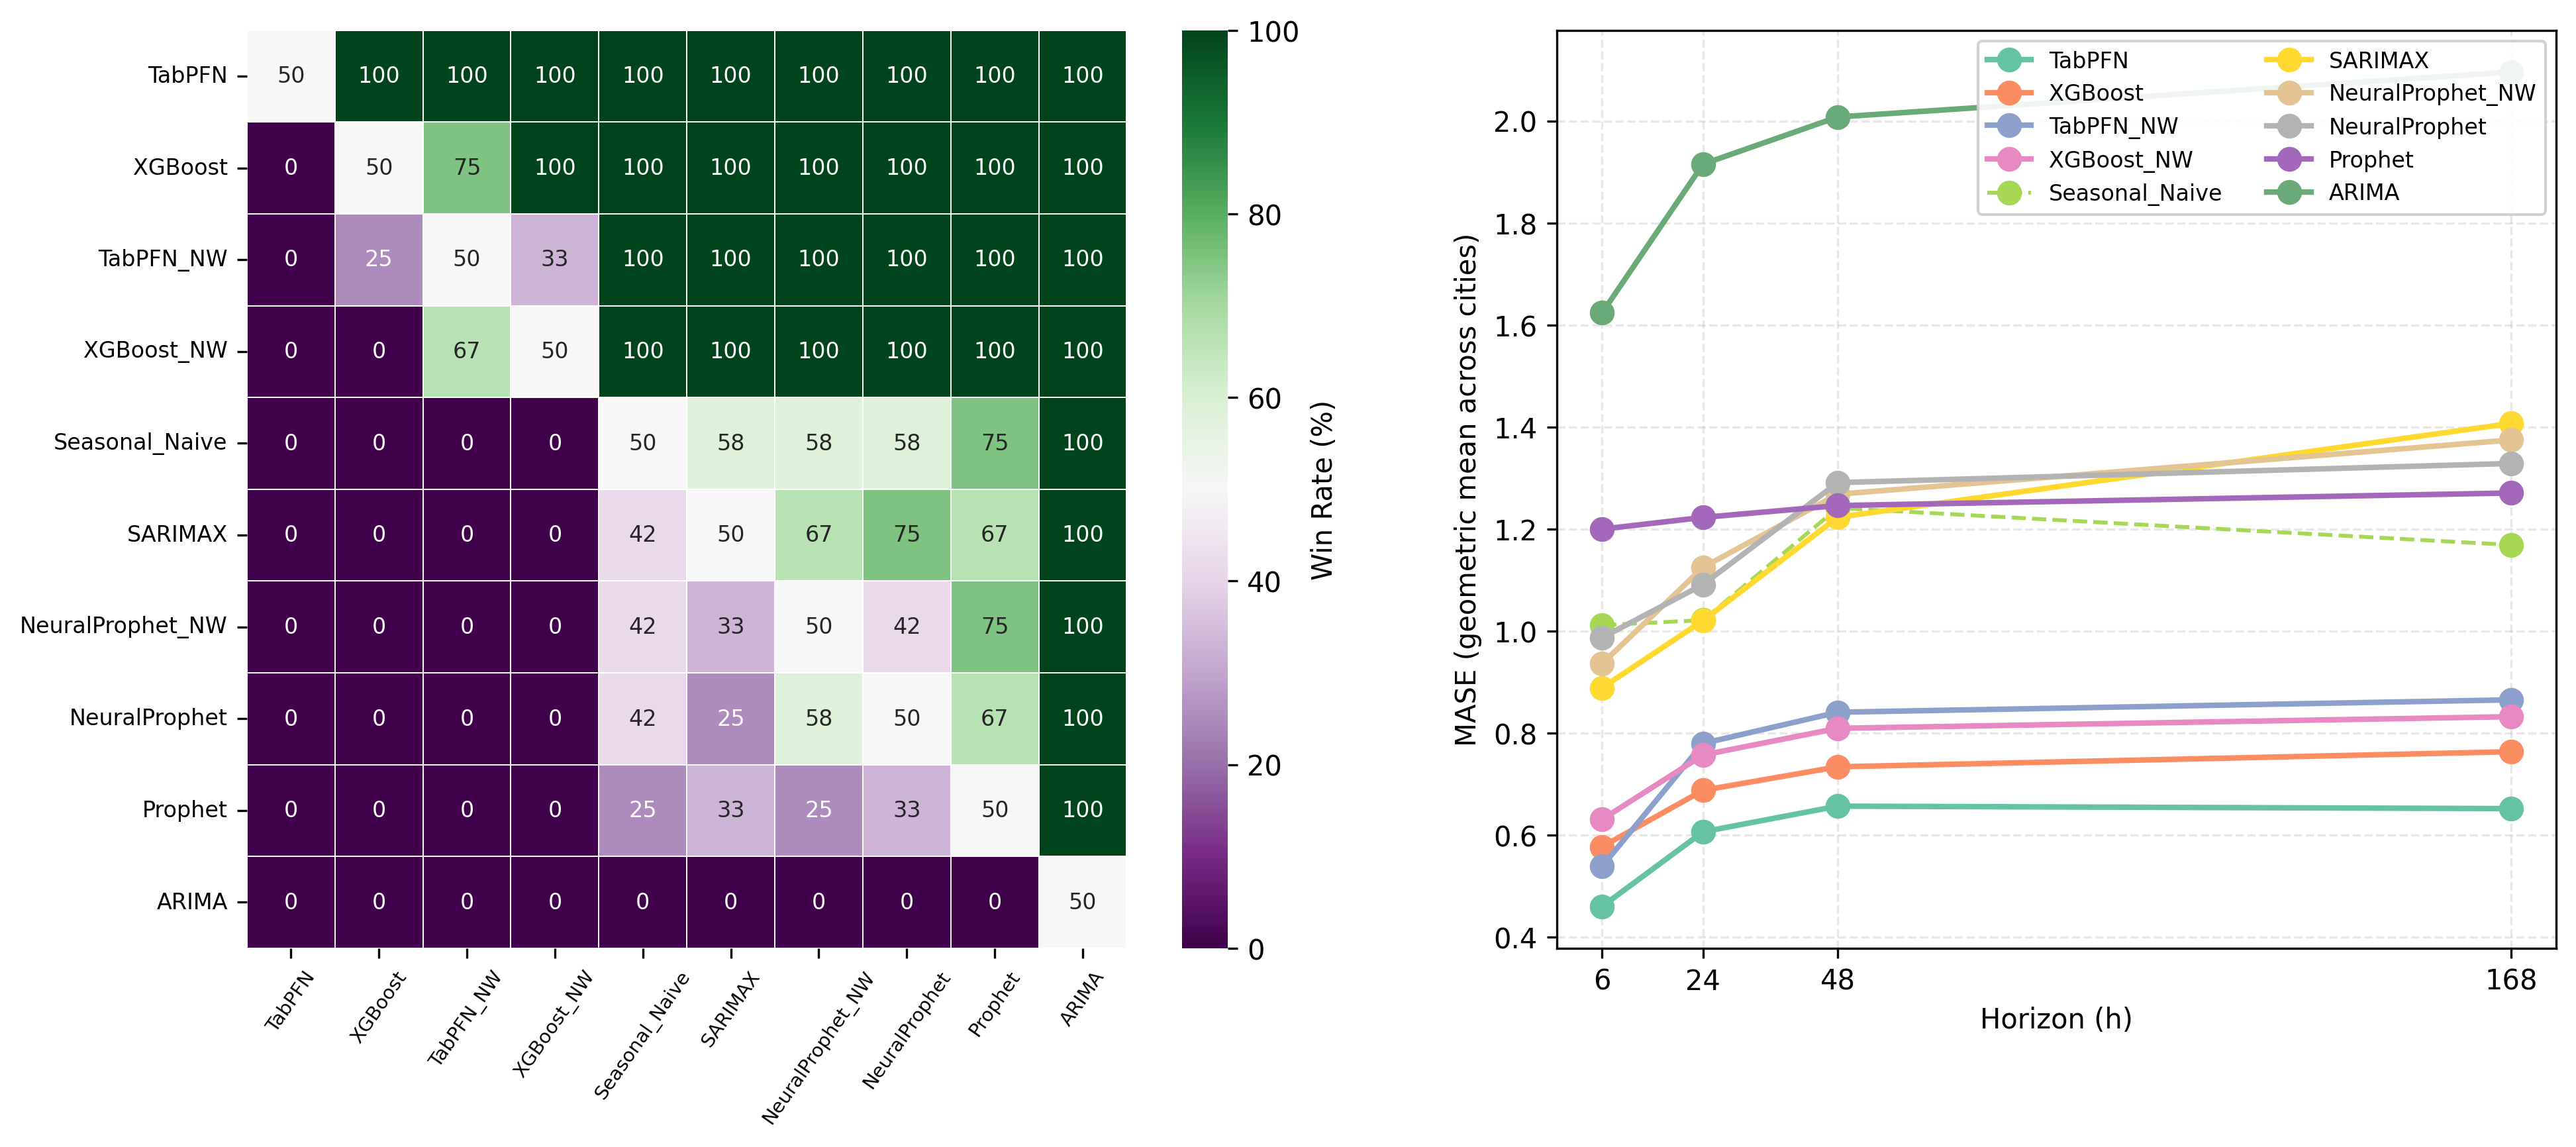

Saved → ../results_v7/figures/cross_city/fig12_cross_city_heatmap_MASE_by_horizon.png


In [40]:
metrics        = ['MAE', 'RMSE', 'MASE', 'sMAPE']
horizons       = sorted(df_clean_all['horizon'].astype(int).unique())

# ── Step 1: MASE per (model, horizon), geometric mean across cities — right panel ─
# (MAE / RMSE are not averaged across cities: scale-dependent.)
city_avg = (
    df_clean_all
    .groupby(['model', 'horizon'])
    .agg(MASE=('MASE_mean', gm))
    .reset_index()
)
available_models = [m for m in MODEL_ORDER_RANKED if m in city_avg['model'].unique()]
city_avg = city_avg[city_avg['model'].isin(available_models)]

# ── Step 2: draw figure ────────────────────────────────────────────────────────
fig, (ax_hm, ax_ln) = plt.subplots(
    1, 2, figsize=(15, 6),
    gridspec_kw={'width_ratios': [1.1, 1.0]}
)

# — Left: pairwise win rate heatmap —
sns.heatmap(
    relabel(win_rate_matrix),
    annot=True, fmt='.0f', cmap='PRGn', center=50,
    ax=ax_hm,
    cbar_kws={'label': 'Win Rate (%)'},
    annot_kws={'fontsize': 8},
    linewidths=0.4, linecolor='white',
)
# ax_hm.set_title('Pairwise Win Rates (%) — All Tasks', fontsize=9)
ax_hm.tick_params(axis='x', labelrotation=55, labelsize=7)
ax_hm.tick_params(axis='y', labelrotation=0,  labelsize=8)

# — Right: MASE line plot by horizon —
for i, model in enumerate(available_models):
    md = city_avg[city_avg['model'] == model].sort_values('horizon')
    ax_ln.plot(
        md['horizon'].astype(int), md['MASE'],
        marker='o', label=dn(model), color=colors[i % len(colors)]
    )

sn_line = [ln for ln in ax_ln.get_lines()
           if ax_ln.get_legend_handles_labels()[1][
               ax_ln.get_lines().index(ln)] == 'Seasonal_Naive']
if sn_line:
    sn_line[0].set_linestyle('--')
    sn_line[0].set_linewidth(1.4)

ax_ln.set_xlabel('Horizon (h)')
ax_ln.set_ylabel('MASE (geometric mean across cities)')
ax_ln.set_xticks(horizons)
ax_ln.grid(True, alpha=0.3, linestyle='--')
ax_ln.legend(loc='upper right', framealpha=0.9, fontsize=8,
             ncol=1 if len(available_models) <= 9 else 2)

# fig.suptitle(
#     'Cross-City Aggregated — Pairwise Win Rates & MASE by Horizon\n'
#     '(Seoul · London · Washington, clean weather, mean across cities)',
#     fontsize=10
# )

out_path = '../results_v7/figures/cross_city/fig12_cross_city_heatmap_MASE_by_horizon.png'
plt.subplots_adjust(wspace=0.2)
fig.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)
print(f'Saved → {out_path}')

# Section 5: Answers to the research questions (95 % intervals)

Each research question is answered by a few comparisons fixed in advance (list in cell 5.2). For each comparison the notebook reports:
- **Change in MASE (%)** of the first against the second: per city–horizon combination first, then the geometric mean over the combinations (same rule as everywhere in this notebook; it equals the fev-bench skill score with the sign flipped). Negative = the first has the lower error.
- **95 % interval** from the week block bootstrap of Section 4, with the **same week draws** (checked in 5.1). An interval that excludes 0 means the difference is significant at the 5 % level (fev-bench: the intervals define paired tests).
- **Tasks**: on how many city–horizon combinations the change is negative.

Comparisons between weather scenarios use the same week draws for both scenarios, so they are paired, like the model comparisons. Models without weather input have a single result, which enters both comparisons.

Levels: all 12 combinations (main text), each horizon (over the 3 cities) and each city (over the 4 horizons).
Comparisons marked `headline` answer a research question; `context` rows support them (appendix).

Outputs (`results_v7/tables/cross_city`, `results_v7/figures/cross_city`): `rq_intervals_v7.csv` (all comparisons and levels), `tableRQ_headline.tex`, `figRQ_forest.png`, `figRQ_by_horizon.png`.
Replaces `statistical_significance_v7.ipynb` (Diebold-Mariano tests per city and horizon, Holm). Its week-correlation check (neighbouring weeks practically unrelated, median 0.03) is what justifies drawing weeks independently; it is repeated in 5.1.


In [41]:
# ── 5.1 Task errors per bootstrap draw, for every model and weather scenario ──────
# Columns: every model with observed weather (models without weather input: their only
# result) + every weather model with forecast (degraded) weather, e.g. 'TabPFN[degraded]'.
# Week draws are the SAME as in Section 4 (same seed, one draw per city, cities in the order
# of DATASETS), so the intervals of observed-weather pairs equal the heatmap ones (Check 3).

WEATHER_LABEL = {'clean_only': 'observed weather', 'degraded': 'forecast weather'}   # wording of tables/figures only

def col(model, scenario='clean_only'):
    """Column name of a model in a weather scenario: 'TabPFN' or 'TabPFN[degraded]'."""
    return model if scenario == 'clean_only' else f'{model}[{scenario}]'

def _col_names(df):
    return np.where(df['weather_scenario'] == 'clean_only', df['model'],
                    df['model'] + '[' + df['weather_scenario'] + ']')

RQ_COLS = MODEL_ORDER_RANKED + [col(m, 'degraded') for m in MODEL_ORDER_RANKED if m in WEATHER_MODELS]


def week_bootstrap_tasks(df_det, cols, datasets, block_hours=BLOCK_HOURS, B=B_BLOCK, seed=RNG_SEED):
    """E (B, R, M): task error (mean of the fold MASE, weighted by how often each fold's week
    was drawn) per draw; E0 (R x M DataFrame): the same without resampling."""
    rng = np.random.default_rng(seed)
    d = df_det.assign(col=_col_names(df_det))
    d = d[d['col'].isin(cols)]
    tasks, E_draws, E_point = [], [], []
    for ds in datasets:
        d_ds  = d[d['dataset'] == ds]
        first = d_ds[d_ds['weather_scenario'] == 'clean_only'].groupby('horizon')['fold'].min()
        d_ds  = d_ds.assign(fold=d_ds['fold'] - d_ds['horizon'].map(first))   # folds from 0, as in Section 4
        clean = d_ds[d_ds['weather_scenario'] == 'clean_only']
        hs    = sorted(clean['horizon'].astype(int).unique())
        n_blocks = int(max((clean.loc[clean['horizon'] == h, 'fold'].max() * h) // block_hours
                           for h in hs) + 1)
        counts = rng.multinomial(n_blocks, np.full(n_blocks, 1.0 / n_blocks), size=B)   # (B, weeks)
        for h in hs:
            piv = (d_ds[d_ds['horizon'] == h]
                   .pivot_table(index='fold', columns='col', values='MASE', aggfunc='mean')
                   .reindex(columns=cols))
            W     = counts[:, (piv.index.values.astype(int) * h) // block_hours]   # (B, folds)
            F     = np.nan_to_num(piv.values, nan=0.0)
            valid = (~np.isnan(piv.values)).astype(float)
            with np.errstate(invalid='ignore', divide='ignore'):
                E_draws.append(np.where(W @ valid > 0, (W @ F) / (W @ valid), np.nan))
                E_point.append(np.where(valid.sum(0) > 0, F.sum(0) / valid.sum(0), np.nan))
            tasks.append((ds, h))
    idx = pd.MultiIndex.from_tuples(tasks, names=['dataset', 'horizon'])
    return np.stack(E_draws, axis=1), pd.DataFrame(np.stack(E_point), index=idx, columns=cols)


def change_pct(E, a, b, rows):
    """MASE change of column a vs column b in %, over the task rows: 100 * (gm(E_a / E_b) - 1).
    Negative = a has the lower error. Ratios clipped to [0.01, 100] as in fev-bench (Check 2:
    never applies). E0 (R, M) -> one number; E_rq (B, R, M) -> one value per draw."""
    E = np.asarray(E)
    ia, ib = RQ_COLS.index(a), RQ_COLS.index(b)
    r = np.clip(E[..., rows, ia] / E[..., rows, ib], 0.01, 100)
    return 100 * (np.exp(np.nanmean(np.log(r), axis=-1)) - 1)


E_rq, E0_rq = week_bootstrap_tasks(df_detailed, RQ_COLS, DATASETS)
ALL_TASKS = np.arange(len(E0_rq))
print(f"{len(E0_rq)} tasks x {len(RQ_COLS)} columns, B = {B_BLOCK}, block = {BLOCK_HOURS} h")

# Check 1: without resampling, the task errors equal MASE_mean of the master file
_m = (df_agg.assign(col=_col_names(df_agg))
      .pivot_table(index=['dataset', 'horizon'], columns='col', values='MASE_mean')
      .reindex(index=E0_rq.index, columns=RQ_COLS))
_dev, _miss = np.nanmax(np.abs(E0_rq.values - _m.values)), int(np.isnan(E0_rq.values).sum())
print(f"Check 1 | task errors = master MASE_mean (all columns): max difference {_dev:.1e}, missing {_miss}"
      f" -> {'OK' if _dev < 1e-9 and _miss == 0 else 'PROBLEM: check the inputs'}")

# Check 2: the fev-bench clipping of ratios to [0.01, 100] never applies
_r = E_rq[..., :, None] / E_rq[..., None, :]
_clipped = int(((_r < 0.01) | (_r > 100)).sum())
print(f"Check 2 | ratios outside [0.01, 100] in any draw: {_clipped} -> {'OK' if _clipped == 0 else 'clipping applies'}")

# Check 3: same week draws as the heatmap intervals of Section 4 (S = -change, so the ends swap)
_dev3 = max(abs(np.nanpercentile(change_pct(E_rq, a, b, ALL_TASKS), q) + bb[s].loc[a, b])
            for a in MODEL_ORDER_RANKED for b in MODEL_ORDER_RANKED if a != b
            for q, s in ((2.5, 'S_hi'), (97.5, 'S_lo')))
print(f"Check 3 | intervals of observed-weather pairs vs heatmap intervals: max difference {_dev3:.1e}"
      f" -> {'OK, same week draws' if _dev3 < 1e-6 else 'PROBLEM: not the same draws'}")


12 tasks x 14 columns, B = 1000, block = 168 h
Check 1 | task errors = master MASE_mean (all columns): max difference 4.4e-16, missing 0 -> OK
Check 2 | ratios outside [0.01, 100] in any draw: 0 -> OK
Check 3 | intervals of observed-weather pairs vs heatmap intervals: max difference 2.8e-14 -> OK, same week draws


In [42]:
# ── 5.2 Comparisons that answer the research questions ────────────────────────
# A comparison is a list of terms (sign, column A, column B):
#   one term : MASE change of A vs B in %          (negative = A has the lower error)
#   two terms: difference of two changes, in points (e.g. how much more weather helps TabPFN)
# 'headline' = answers a research question (main text); 'context' = supporting rows (appendix).
OBSW, FCW = WEATHER_LABEL['clean_only'], WEATHER_LABEL['degraded']
TP, TPN, XG, XGN = 'TabPFN', 'TabPFN_NoWeather', 'XGBoost', 'XGBoost_NoWeather'
dg = lambda m: col(m, 'degraded')

# (kind, group, comparison, terms, what a NEGATIVE value means)
RQ_COMPARISONS = [
    # RQ1: foundation model vs the strongest traditional model, both with the same inputs
    ('headline', 'RQ1', 'TabPFN vs XGBoost, both without weather', [(1, TPN, XGN)],       'TabPFN lower error'),
    ('headline', 'RQ1', f'TabPFN vs XGBoost, both with {OBSW}',    [(1, TP, XG)],         'TabPFN lower error'),
    ('headline', 'RQ1', f'TabPFN vs XGBoost, both with {FCW}',     [(1, dg(TP), dg(XG))], 'TabPFN lower error'),
    # RQ2: what weather adds, and whether it adds more for the foundation model
    ('headline', 'RQ2', f'TabPFN: {OBSW} vs no weather',  [(1, TP, TPN)], 'weather lowers the error'),
    ('headline', 'RQ2', f'XGBoost: {OBSW} vs no weather', [(1, XG, XGN)], 'weather lowers the error'),
    ('headline', 'RQ2', 'Difference TabPFN minus XGBoost (points)', [(1, TP, TPN), (-1, XG, XGN)],
     'weather helps TabPFN more'),
    # RQ3: what forecast weather costs, for which model more, and whether it still beats no weather
    ('headline', 'RQ3', f'TabPFN: {FCW} vs {OBSW}',  [(1, dg(TP), TP)], f'lower error with {FCW} (positive = loss)'),
    ('headline', 'RQ3', f'XGBoost: {FCW} vs {OBSW}', [(1, dg(XG), XG)], f'lower error with {FCW} (positive = loss)'),
    ('headline', 'RQ3', 'Difference TabPFN minus XGBoost (points)', [(1, dg(TP), TP), (-1, dg(XG), XG)],
     'TabPFN loses less (positive = TabPFN loses more)'),
    ('headline', 'RQ3', f'TabPFN: {FCW} vs no weather',  [(1, dg(TP), TPN)], f'{FCW} better than no weather'),
    ('headline', 'RQ3', f'XGBoost: {FCW} vs no weather', [(1, dg(XG), XGN)], f'{FCW} better than no weather'),
]
# Context: the other weather models, and every model against Seasonal Naive (the ranking)
RQ_COMPARISONS += [
    ('context', 'RQ2', f'NeuralProphet: {OBSW} vs no weather', [(1, 'NeuralProphet', 'NeuralProphet_NoWeather')],
     'weather lowers the error')]
RQ_COMPARISONS += [
    ('context', 'RQ3', f'{m}: {FCW} vs {OBSW}', [(1, dg(m), m)], f'lower error with {FCW} (positive = loss)')
    for m in MODEL_ORDER_RANKED if m in WEATHER_MODELS and m not in (TP, XG)]
RQ_COMPARISONS += [
    ('context', 'Ranking', f'{m} vs Seasonal Naive' + (f', {OBSW}' if m in WEATHER_MODELS else ''),
     [(1, m, 'Seasonal_Naive')], 'lower error than Seasonal Naive')
    for m in MODEL_ORDER_RANKED if m != 'Seasonal_Naive']
RQ_COMPARISONS += [
    ('context', 'Ranking', f'{m} vs Seasonal Naive, {FCW}', [(1, dg(m), 'Seasonal_Naive')],
     'lower error than Seasonal Naive')
    for m in MODEL_ORDER_RANKED if m in WEATHER_MODELS]
HEADLINE = [c for c in RQ_COMPARISONS if c[0] == 'headline']

# Levels: all tasks, each horizon (over the cities), each city (over the horizons)
_ds, _h = E0_rq.index.get_level_values('dataset'), E0_rq.index.get_level_values('horizon')
LEVELS = {'all': ALL_TASKS}
LEVELS.update({f'{h} h': np.where(_h == h)[0] for h in sorted(_h.unique())})
LEVELS.update({ds: np.where(_ds == ds)[0] for ds in DATASETS})


def evaluate(terms, rows):
    """Point value (no resampling), 95 % interval, tasks with a negative value, bootstrap p."""
    point = sum(s * change_pct(E0_rq.values, a, b, rows) for s, a, b in terms)
    draws = sum(s * change_pct(E_rq, a, b, rows) for s, a, b in terms)
    per_task = sum(s * 100 * (E0_rq[a].values[rows] / E0_rq[b].values[rows] - 1) for s, a, b in terms)
    lo, hi = np.nanpercentile(draws, [2.5, 97.5])
    d = draws[np.isfinite(draws)]   # two-sided p from the same draws; +1 in numerator and denominator so that p is never 0 (Phipson & Smyth 2010)
    p = min(1.0, 2 * (1 + min((d <= 0).sum(), (d >= 0).sum())) / (len(d) + 1))
    return float(point), lo, hi, int((per_task < 0).sum()), len(rows), p


rows = []
for kind, grp, name, terms, neg in RQ_COMPARISONS:
    for lvl, r in LEVELS.items():
        v, lo, hi, n_neg, n, p = evaluate(terms, r)
        rows.append(dict(kind=kind, group=grp, comparison=name, level=lvl, value=v, ci_low=lo, ci_high=hi,
                         excludes_0=bool(lo > 0 or hi < 0), tasks_negative=n_neg, n_tasks=n,
                         negative_means=neg, p_boot=p))
rq_ci = pd.DataFrame(rows)
# Holm over the 11 headline comparisons, all 12 combinations (= column "All" of the CI table, Table E.12); all other rows are not adjusted (p_holm empty)
_hm = ((rq_ci['kind'] == 'headline') & (rq_ci['level'] == 'all')).to_numpy()
_ph = rq_ci.loc[_hm, 'p_boot'].to_numpy()
_k, _o = len(_ph), np.argsort(_ph)
_adj = np.empty(_k)
_adj[_o] = np.maximum.accumulate(np.minimum(1, (_k - np.arange(_k)) * _ph[_o]))
rq_ci['p_holm'] = np.nan
rq_ci.loc[_hm, 'p_holm'] = _adj
# value / ci_low / ci_high: 1 decimal, rounded from the unrounded values with the same rule as the
# paper tables (Section 7: f'{v:.1f}'; -0.0 written as 0.0). p_boot: 4 decimals. rq_ci stays unrounded.
def round_as_tables(v, d=1):
    return v if pd.isna(v) else float(f'{v:.{d}f}') + 0.0
_csv = rq_ci.copy()
for _c in ['value', 'ci_low', 'ci_high']:
    _csv[_c] = _csv[_c].map(round_as_tables)
_csv['p_boot'] = _csv['p_boot'].round(4)
_csv['p_holm'] = _csv['p_holm'].round(4)
_csv.to_csv(TAB('rq_intervals_v7.csv'), index=False)

# Point values must equal the numbers of the tables in Section 3 (same geometric-mean rule)
_ref = {f'TabPFN vs XGBoost, both with {OBSW}': pct_better_geo(TP, XG) * -1,
        f'TabPFN vs XGBoost, both with {FCW}': pct_better_geo(TP, XG, df=df_all_degraded) * -1,
        f'TabPFN: {OBSW} vs no weather': -float(tabpfn_weather_by_horizon_export.iloc[-1]['Improvement_%']),
        f'TabPFN: {FCW} vs {OBSW}': float(degradation_tabpfn_xgb_by_horizon_export.iloc[-1]['TabPFN_Degraded_%']),
        f'XGBoost: {FCW} vs {OBSW}': float(degradation_tabpfn_xgb_by_horizon_export.iloc[-1]['XGBoost_Degraded_%']),
        f'TabPFN: {FCW} vs no weather': float(summary_310.set_index('model').loc[TP, 'vs_NoWeather_%'])}
_all = rq_ci[rq_ci['level'] == 'all'].set_index('comparison')['value']
_dev = max(abs(_all[k] - v) for k, v in _ref.items())
print(f"Check 5 | point values vs headline cell and Sections 3.6, 3.7, 3.10: max difference {_dev:.3f} points"
      f" -> {'OK' if _dev < 0.002 else 'PROBLEM'}  (tables there are rounded to 3 decimals)")


def fmt(v, lo, hi):
    return f"{v:+6.1f}  ({lo:+.1f} to {hi:+.1f})"


def show(level_names, kinds=('headline',)):
    t = rq_ci[rq_ci['kind'].isin(kinds) & rq_ci['level'].isin(level_names)].copy()
    t['result'] = [fmt(v, lo, hi) + ('' if ex else '  n.s.') for v, lo, hi, ex
                   in zip(t['value'], t['ci_low'], t['ci_high'], t['excludes_0'])]
    t['tasks'] = t['tasks_negative'].astype(str) + '/' + t['n_tasks'].astype(str)
    return t


print("\nHeadline comparisons, all 12 city-horizon combinations")
print("value = MASE change in % (difference rows: points); 95 % interval; tasks = combinations with a negative value")
_t = show(['all'])
for g, gg in _t.groupby('group', sort=False):
    print(f"\n{g}")
    for _, r in gg.iterrows():
        print(f"  {r['comparison']:<52} {r['result']:<34} tasks {r['tasks']:>5}   negative = {r['negative_means']}")

for title, lv in [('by horizon (over the 3 cities)', [l for l in LEVELS if l.endswith(' h')]),
                  ('by city (over the 4 horizons)', list(DATASETS))]:
    print(f"\nHeadline comparisons {title}; 'n.s.' = interval includes 0")
    _t = show(lv)
    print(_t.pivot_table(index=['group', 'comparison'], columns='level', values='result', aggfunc='first')
            .reindex(index=[(c[1], c[2]) for c in HEADLINE], columns=lv).to_string())

print("\nContext rows, all 12 combinations")
for _, r in show(['all'], kinds=('context',)).iterrows():
    print(f"  {r['group']:<8} {r['comparison']:<52} {r['result']:<34} tasks {r['tasks']:>5}")

# Check 6: Holm correction over the headline comparisons (all combinations), computed above (p_holm, saved in
# rq_intervals_v7.csv). The intervals are not adjusted; this shows whether any conclusion depends on it.
H = rq_ci[_hm].reset_index(drop=True)
_flip = H[H['excludes_0'] & (H['p_holm'] >= 0.05)]['comparison'].tolist()
print(f"\nCheck 6 | Holm over the {_k} headline comparisons: "
      + ("no conclusion changes" if not _flip else f"no longer significant: {_flip}")
      + f"  (B = {B_BLOCK}: smallest possible p = {2 / (B_BLOCK + 1):.4f}, x {_k} = {_k * 2 / (B_BLOCK + 1):.4f} after Holm)")
for _, r in H.iterrows():
    print(f"  {r['comparison']:<52} p = {r['p_boot']:.4f}   Holm p = {r['p_holm']:.4f}")

# Check 7: are neighbouring weeks related? (justifies drawing weeks independently; same check as the
# retired significance notebook: weekly mean of each headline comparison's MASE difference, per city and
# horizon, correlation with the week after. With unrelated weeks, above +0.33 in about 2.5 % of series.)
_ac, _dd = [], df_detailed.assign(col=_col_names(df_detailed))
for (ds, h), g in _dd.groupby(['dataset', 'horizon']):
    x  = g.pivot_table(index='fold', columns='col', values='MASE')
    wk = ((x.index - g['fold'].min()) * h) // BLOCK_HOURS
    for c in HEADLINE:
        coef = {}
        for s, a, b in c[3]:
            coef[a], coef[b] = coef.get(a, 0) + s, coef.get(b, 0) - s
        d_fold = sum(c * x[k] for k, c in coef.items() if c != 0)
        _ac.append(pd.Series(d_fold.groupby(wk).mean().values).autocorr(1))
_ac = np.array(_ac)
print(f"Check 7 | neighbouring weeks, {len(_ac)} series: median correlation {np.nanmedian(_ac):+.2f}, "
      f"share above +0.33: {np.nanmean(_ac > 1.96 / np.sqrt(35)):.0%} (chance about 2.5 %)"
      f" -> {'weeks practically unrelated: drawing them independently is fine' if abs(np.nanmedian(_ac)) < 0.15 else 'CHECK'}")

# ── LaTeX: headline table (all combinations) ─────────────────────────────────────
def _tx(v):
    return f"${v:+.1f}$"

tex  = "\\begin{table}[ht!]\n\\centering\n"
tex += ("\\caption{Comparisons answering the research questions. Change: MASE of the first against the second, "
        "computed for each city--horizon combination and averaged geometrically over all 12 (negative: lower error); "
        "difference rows in percentage points. Interval: 95\\,\\% week block bootstrap. "
        "Tasks: combinations with a negative value.}\n")
tex += "\\label{tab:rq_intervals}\n{\\small\n\\begin{tabular}{llrrr}\n\\toprule\n"
tex += "RQ & Comparison & Change (\\%) & 95\\,\\% interval & Tasks \\\\\n"
_t = show(['all'])
for i, (g, gg) in enumerate(_t.groupby('group', sort=False)):
    tex += "\\midrule\n"
    for j, (_, r) in enumerate(gg.iterrows()):
        tex += (f"{g if j == 0 else ''} & {tex_esc(r['comparison'])} & {_tx(r['value'])} & "
                f"{_tx(r['ci_low'])} to {_tx(r['ci_high'])} & {r['tasks']} \\\\\n")
tex += "\\bottomrule\n\\end{tabular}\n}\n\\end{table}\n"
with open(TAB('tableRQ_headline.tex'), 'w') as f:
    f.write(tex)
print(f"\nSaved: {TAB('rq_intervals_v7.csv')}, {TAB('tableRQ_headline.tex')}")

Check 5 | point values vs headline cell and Sections 3.6, 3.7, 3.10: max difference 0.000 points -> OK  (tables there are rounded to 3 decimals)

Headline comparisons, all 12 city-horizon combinations
value = MASE change in % (difference rows: points); 95 % interval; tasks = combinations with a negative value

RQ1
  TabPFN vs XGBoost, both without weather                -1.3  (-5.0 to +3.1)  n.s.       tasks  4/12   negative = TabPFN lower error
  TabPFN vs XGBoost, both with observed weather         -14.4  (-18.1 to -10.4)           tasks 12/12   negative = TabPFN lower error
  TabPFN vs XGBoost, both with forecast weather         -10.5  (-14.3 to -6.3)            tasks 12/12   negative = TabPFN lower error

RQ2
  TabPFN: observed weather vs no weather                -20.9  (-23.6 to -18.3)           tasks 12/12   negative = weather lowers the error
  XGBoost: observed weather vs no weather                -8.8  (-10.7 to -6.9)            tasks 12/12   negative = weather lowers the err

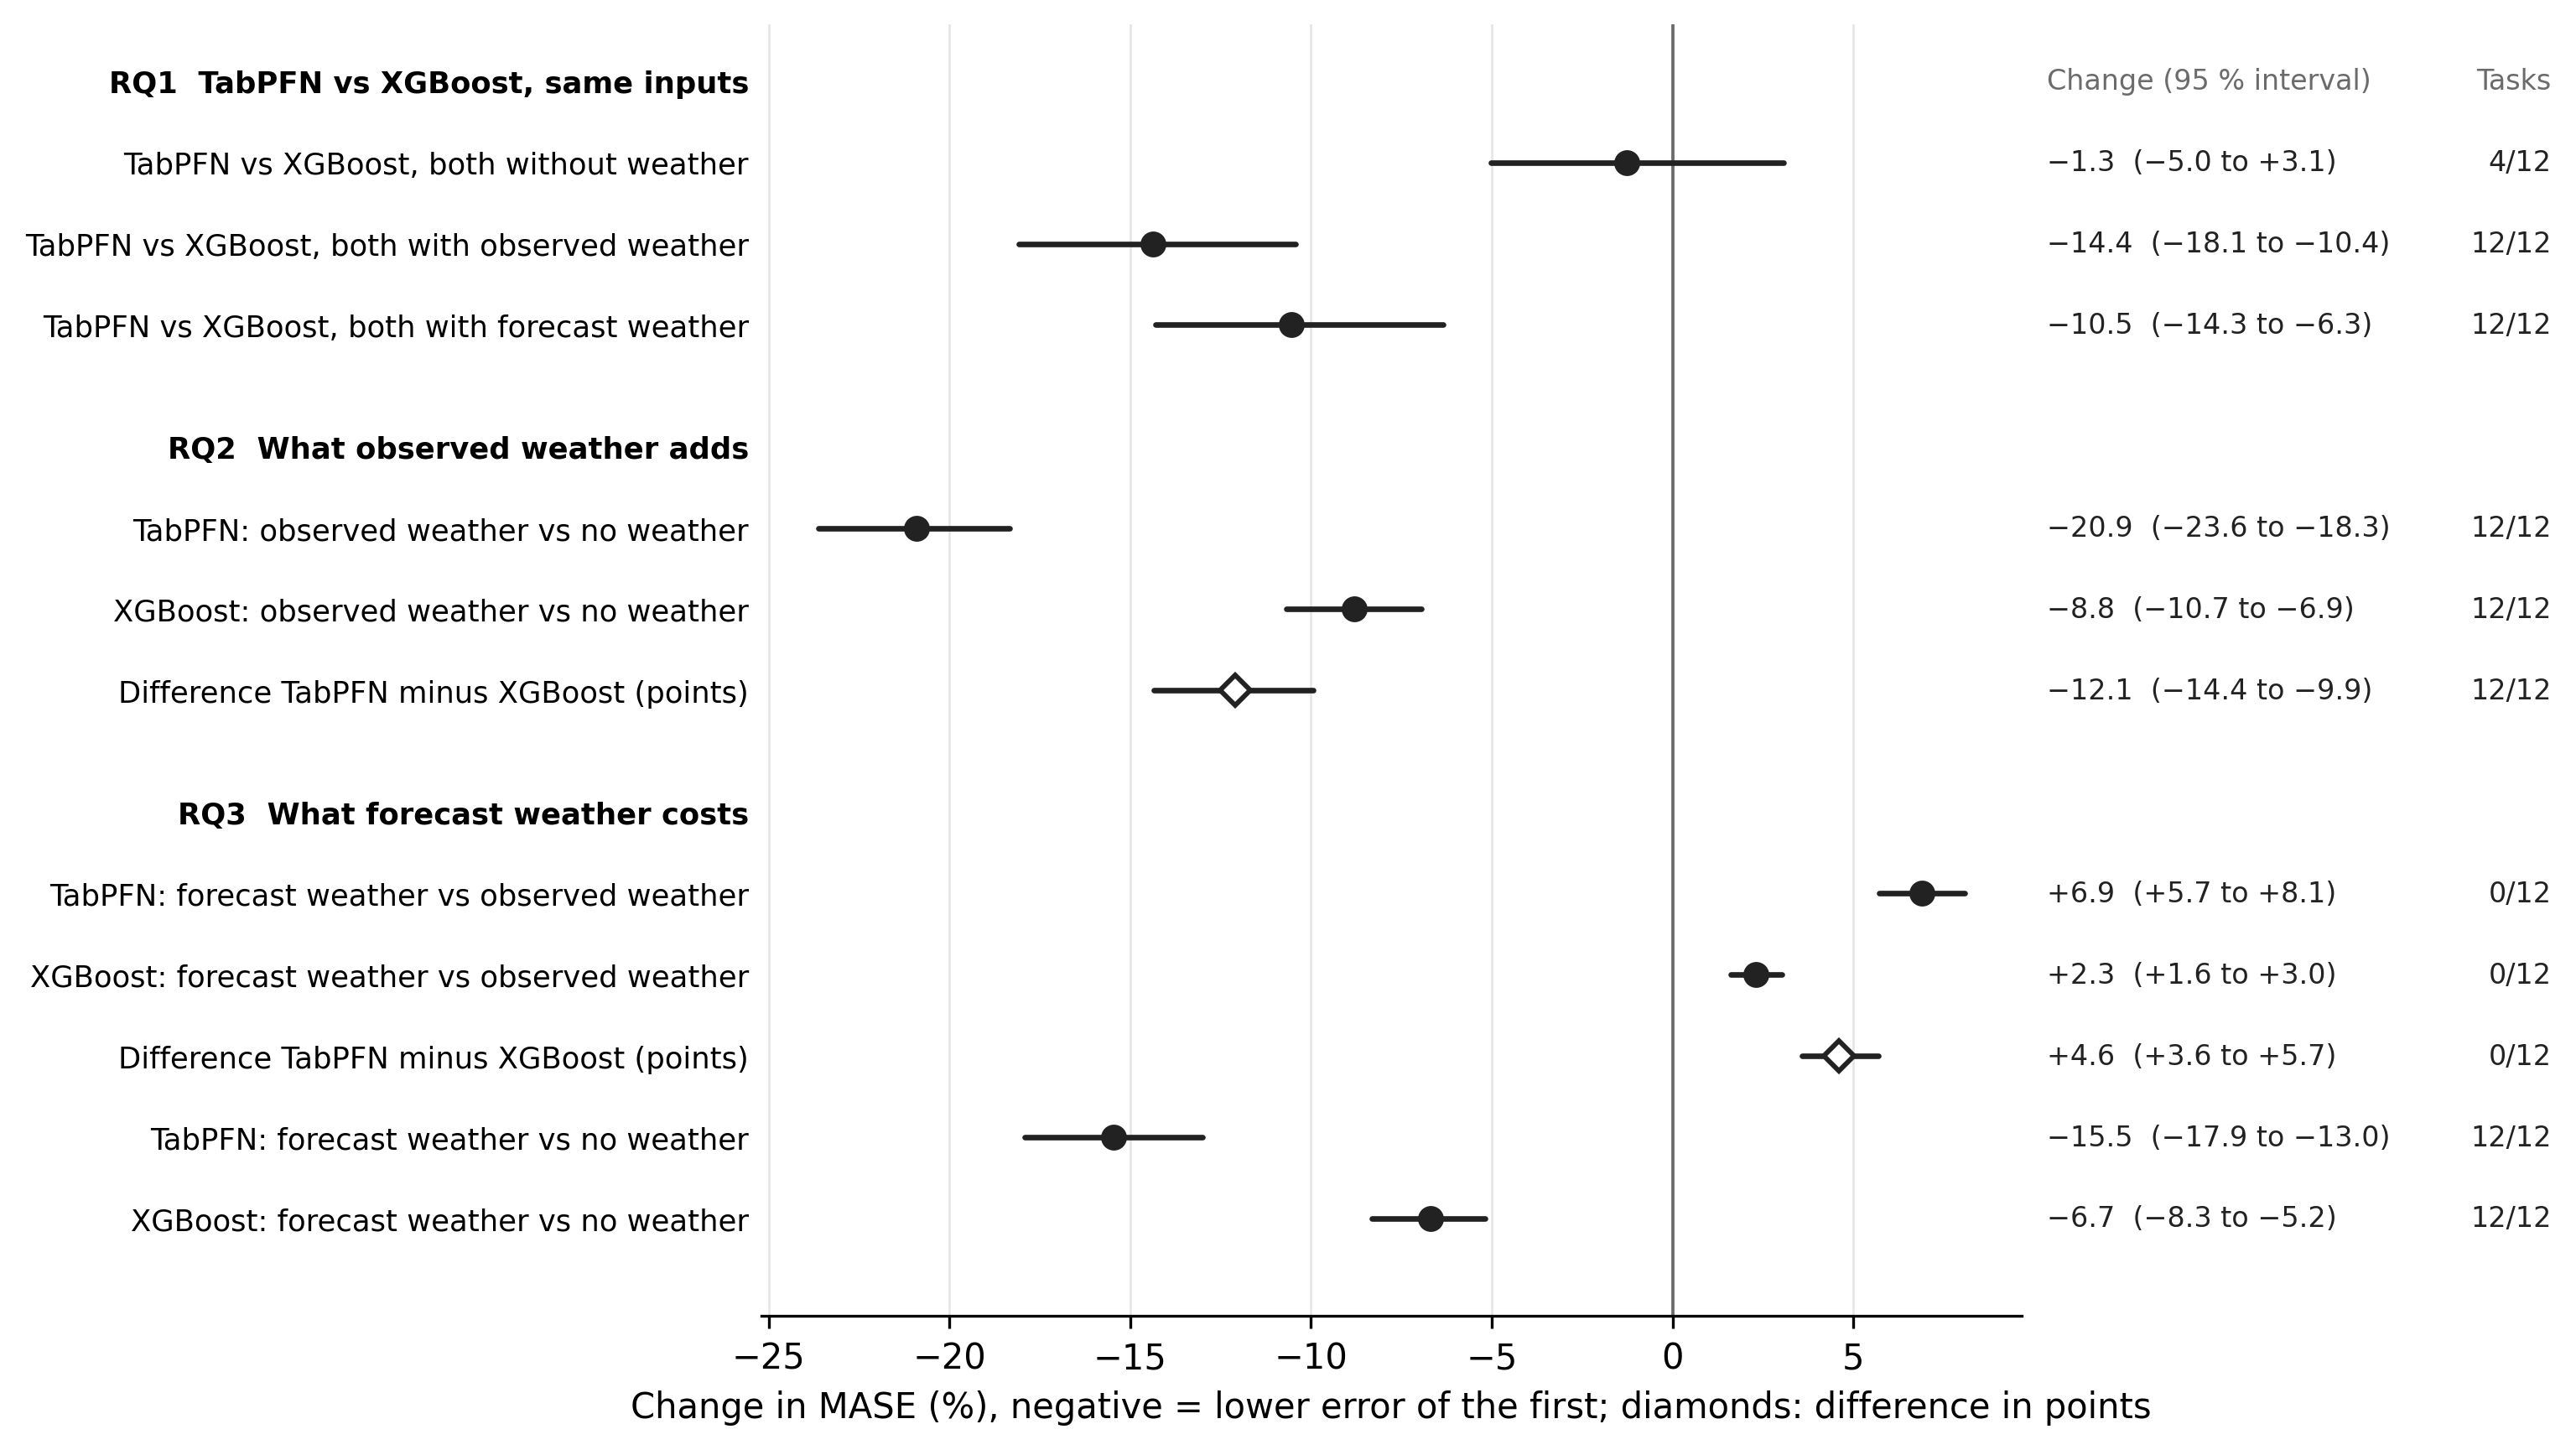

Saved: ../results_v7/figures/cross_city/figRQ_forest.png


In [43]:
# ── 5.3 Figure: headline comparisons with 95 % intervals (all 12 combinations) ───────
# One row per comparison: dot = value, line = 95 % interval, 0 = no difference.
# Hollow diamonds: difference of two changes (points). Right: value, interval, tasks.
FIG_RQ = Path('../results_v7/figures/cross_city')
INK, MUTED, GRID = '#222222', '#6b6b6b', '#e5e5e5'
GROUP_TITLE = {'RQ1': 'RQ1  TabPFN vs XGBoost, same inputs',
               'RQ2': f'RQ2  What {OBSW} adds',
               'RQ3': f'RQ3  What {FCW} costs'}

_H = show(['all'])
heads, items, y = [], [], 0.0
for g, gg in _H.groupby('group', sort=False):
    heads.append((y, GROUP_TITLE.get(g, g))); y -= 1
    for _, r in gg.iterrows():
        items.append((y, r)); y -= 1
    y -= 0.5

MINUS = lambda s: s.replace('-', '\u2212')          # typographic minus, as on the axis
fig, ax = plt.subplots(figsize=(10, 0.3 * (-y) + 1.0), constrained_layout=True)
for yy, r in items:
    diff = 'points' in r['comparison']
    ax.plot([r['ci_low'], r['ci_high']], [yy, yy], color=INK, lw=1.6, solid_capstyle='round', zorder=2)
    ax.plot(r['value'], yy, marker='D' if diff else 'o', ms=6, color=INK,
            mfc='white' if diff else INK, mew=1.4, zorder=3)
    ax.text(1.02, yy, MINUS(f"{r['value']:+.1f}  ({r['ci_low']:+.1f} to {r['ci_high']:+.1f})"),
            transform=ax.get_yaxis_transform(), va='center', ha='left', fontsize=8, color=INK)
    ax.text(1.42, yy, r['tasks'], transform=ax.get_yaxis_transform(),
            va='center', ha='right', fontsize=8, color=INK)
ax.text(1.02, heads[0][0], 'Change (95 % interval)', transform=ax.get_yaxis_transform(),
        va='center', ha='left', fontsize=8, color=MUTED)
ax.text(1.42, heads[0][0], 'Tasks', transform=ax.get_yaxis_transform(),
        va='center', ha='right', fontsize=8, color=MUTED)

ax.set_yticks([p for p, _ in heads] + [p for p, _ in items])
ax.set_yticklabels([t for _, t in heads] + [r['comparison'] for _, r in items], fontsize=8.5)
for lab in ax.get_yticklabels()[:len(heads)]:
    lab.set_fontweight('bold')
ax.tick_params(axis='y', length=0)
ax.set_ylim(y + 0.3, 0.7)
ax.axvline(0, color=MUTED, lw=0.9, zorder=1)
ax.grid(axis='x', color=GRID, lw=0.6); ax.set_axisbelow(True)
for s in ('top', 'right', 'left'):
    ax.spines[s].set_visible(False)
ax.set_xlabel('Change in MASE (%), negative = lower error of the first; diamonds: difference in points')
fig.savefig(FIG_RQ / 'figRQ_forest.png', dpi=300, bbox_inches='tight')
plt.show(); plt.close(fig)
print(f"Saved: {FIG_RQ / 'figRQ_forest.png'}")


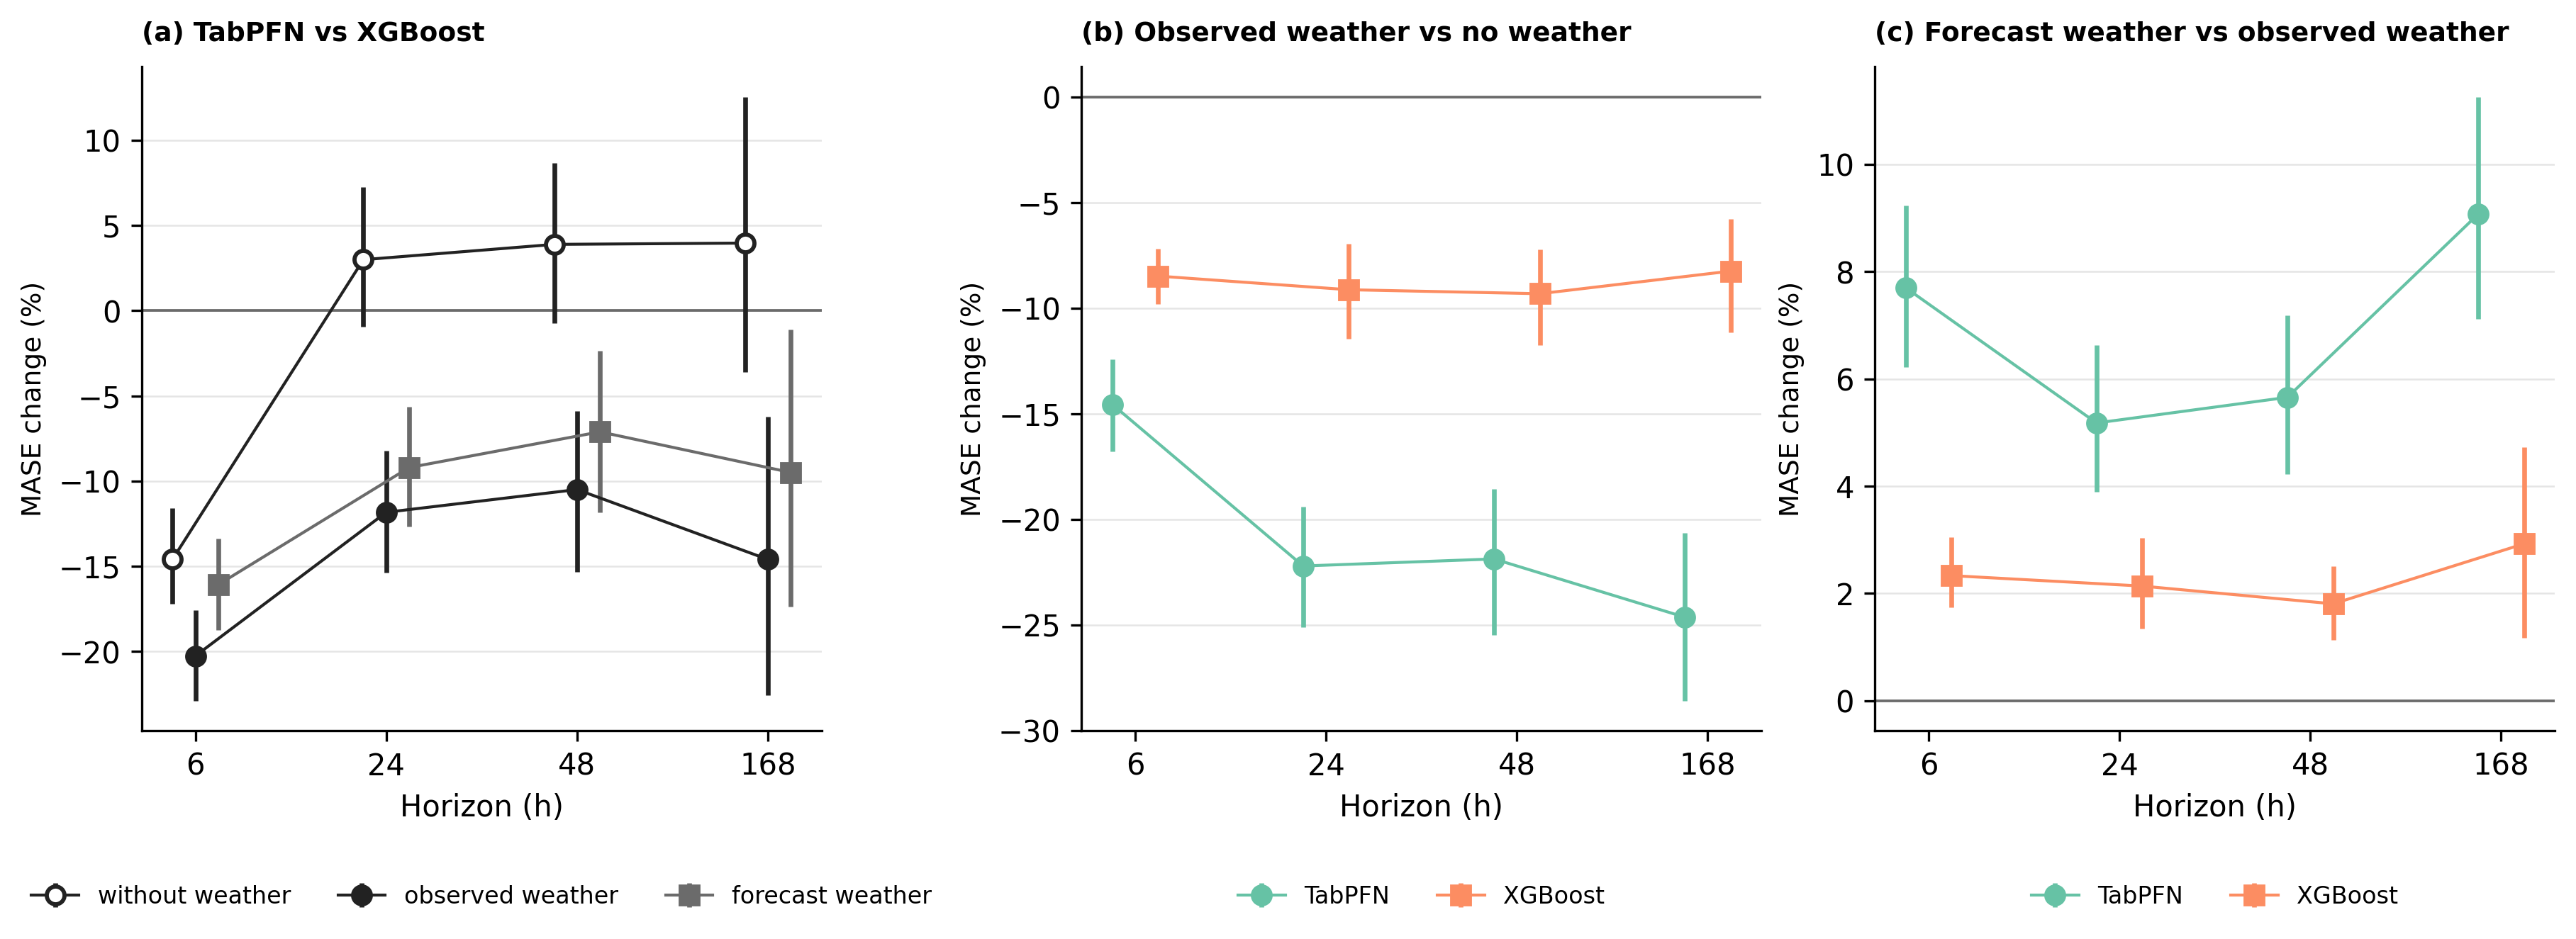

Saved: ../results_v7/figures/cross_city/figRQ_by_horizon.png


In [44]:
# ── 5.4 Figure: the headline comparisons by horizon (geometric mean over the 3 cities) ──
# (a) RQ1 TabPFN vs XGBoost in each weather setting, (b) RQ2 what observed weather adds,
# (c) RQ3 what forecast weather costs. Bars: 95 % intervals (same week draws).
# TabPFN / XGBoost keep their colours of the other figures; marker shape = second cue.
HZ  = [l for l in LEVELS if l.endswith(' h')]
c_tp, c_xg = (colors[MODEL_ORDER_RANKED.index(m) % len(colors)] for m in (TP, XG))
PANELS = [
    ('(a) TabPFN vs XGBoost', 'MASE change (%)',
     [('TabPFN vs XGBoost, both without weather', 'without weather', INK,   'o', 'white'),
      (f'TabPFN vs XGBoost, both with {OBSW}',    OBSW,              INK,   'o', INK),
      (f'TabPFN vs XGBoost, both with {FCW}',     FCW,               MUTED, 's', MUTED)]),
    ('(b) ' + f'{OBSW} vs no weather'.capitalize(), 'MASE change (%)',
     [(f'TabPFN: {OBSW} vs no weather',  'TabPFN',  c_tp, 'o', c_tp),
      (f'XGBoost: {OBSW} vs no weather', 'XGBoost', c_xg, 's', c_xg)]),
    ('(c) ' + f'{FCW} vs {OBSW}'.capitalize(), 'MASE change (%)',
     [(f'TabPFN: {FCW} vs {OBSW}',  'TabPFN',  c_tp, 'o', c_tp),
      (f'XGBoost: {FCW} vs {OBSW}', 'XGBoost', c_xg, 's', c_xg)]),
]
xs = np.arange(len(HZ))
fig, axes = plt.subplots(1, 3, figsize=(12, 4.3), constrained_layout=True)
for ax, (tag, ylabel, series) in zip(axes, PANELS):
    offs = np.linspace(-0.12, 0.12, len(series))
    for o, (name, label, c, mk, mfc) in zip(offs, series):
        t = rq_ci[rq_ci['comparison'] == name].set_index('level').loc[HZ]
        ax.errorbar(xs + o, t['value'], yerr=[t['value'] - t['ci_low'], t['ci_high'] - t['value']],
                    fmt=mk + '-', color=c, mfc=mfc, mec=c, mew=1.4, ms=6, lw=1.0, elinewidth=1.6,
                    capsize=0, label=label, zorder=3)
    ax.axhline(0, color=MUTED, lw=0.9, zorder=1)
    ax.set_xticks(xs); ax.set_xticklabels([l.replace(' h', '') for l in HZ]); ax.set_xlabel('Horizon (h)')
    ax.set_ylabel(ylabel, fontsize=9)
    ax.grid(axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
    ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=len(series))
    ax.text(0.0, 1.03, tag, transform=ax.transAxes, fontsize=9, fontweight='bold', ha='left', va='bottom')
fig.savefig(FIG_RQ / 'figRQ_by_horizon.png', dpi=300, bbox_inches='tight')
plt.show(); plt.close(fig)
print(f"Saved: {FIG_RQ / 'figRQ_by_horizon.png'}")


## Section 6: Paper figures

The four figures of the main text, drawn at page width so that every number is legible in print. Saved as PDF and PNG to `results_v7/figures/paper/`; copy them into the LaTeX folder `figures/`. Uses the numbers of Sections 3 and 4 (no new calculation).

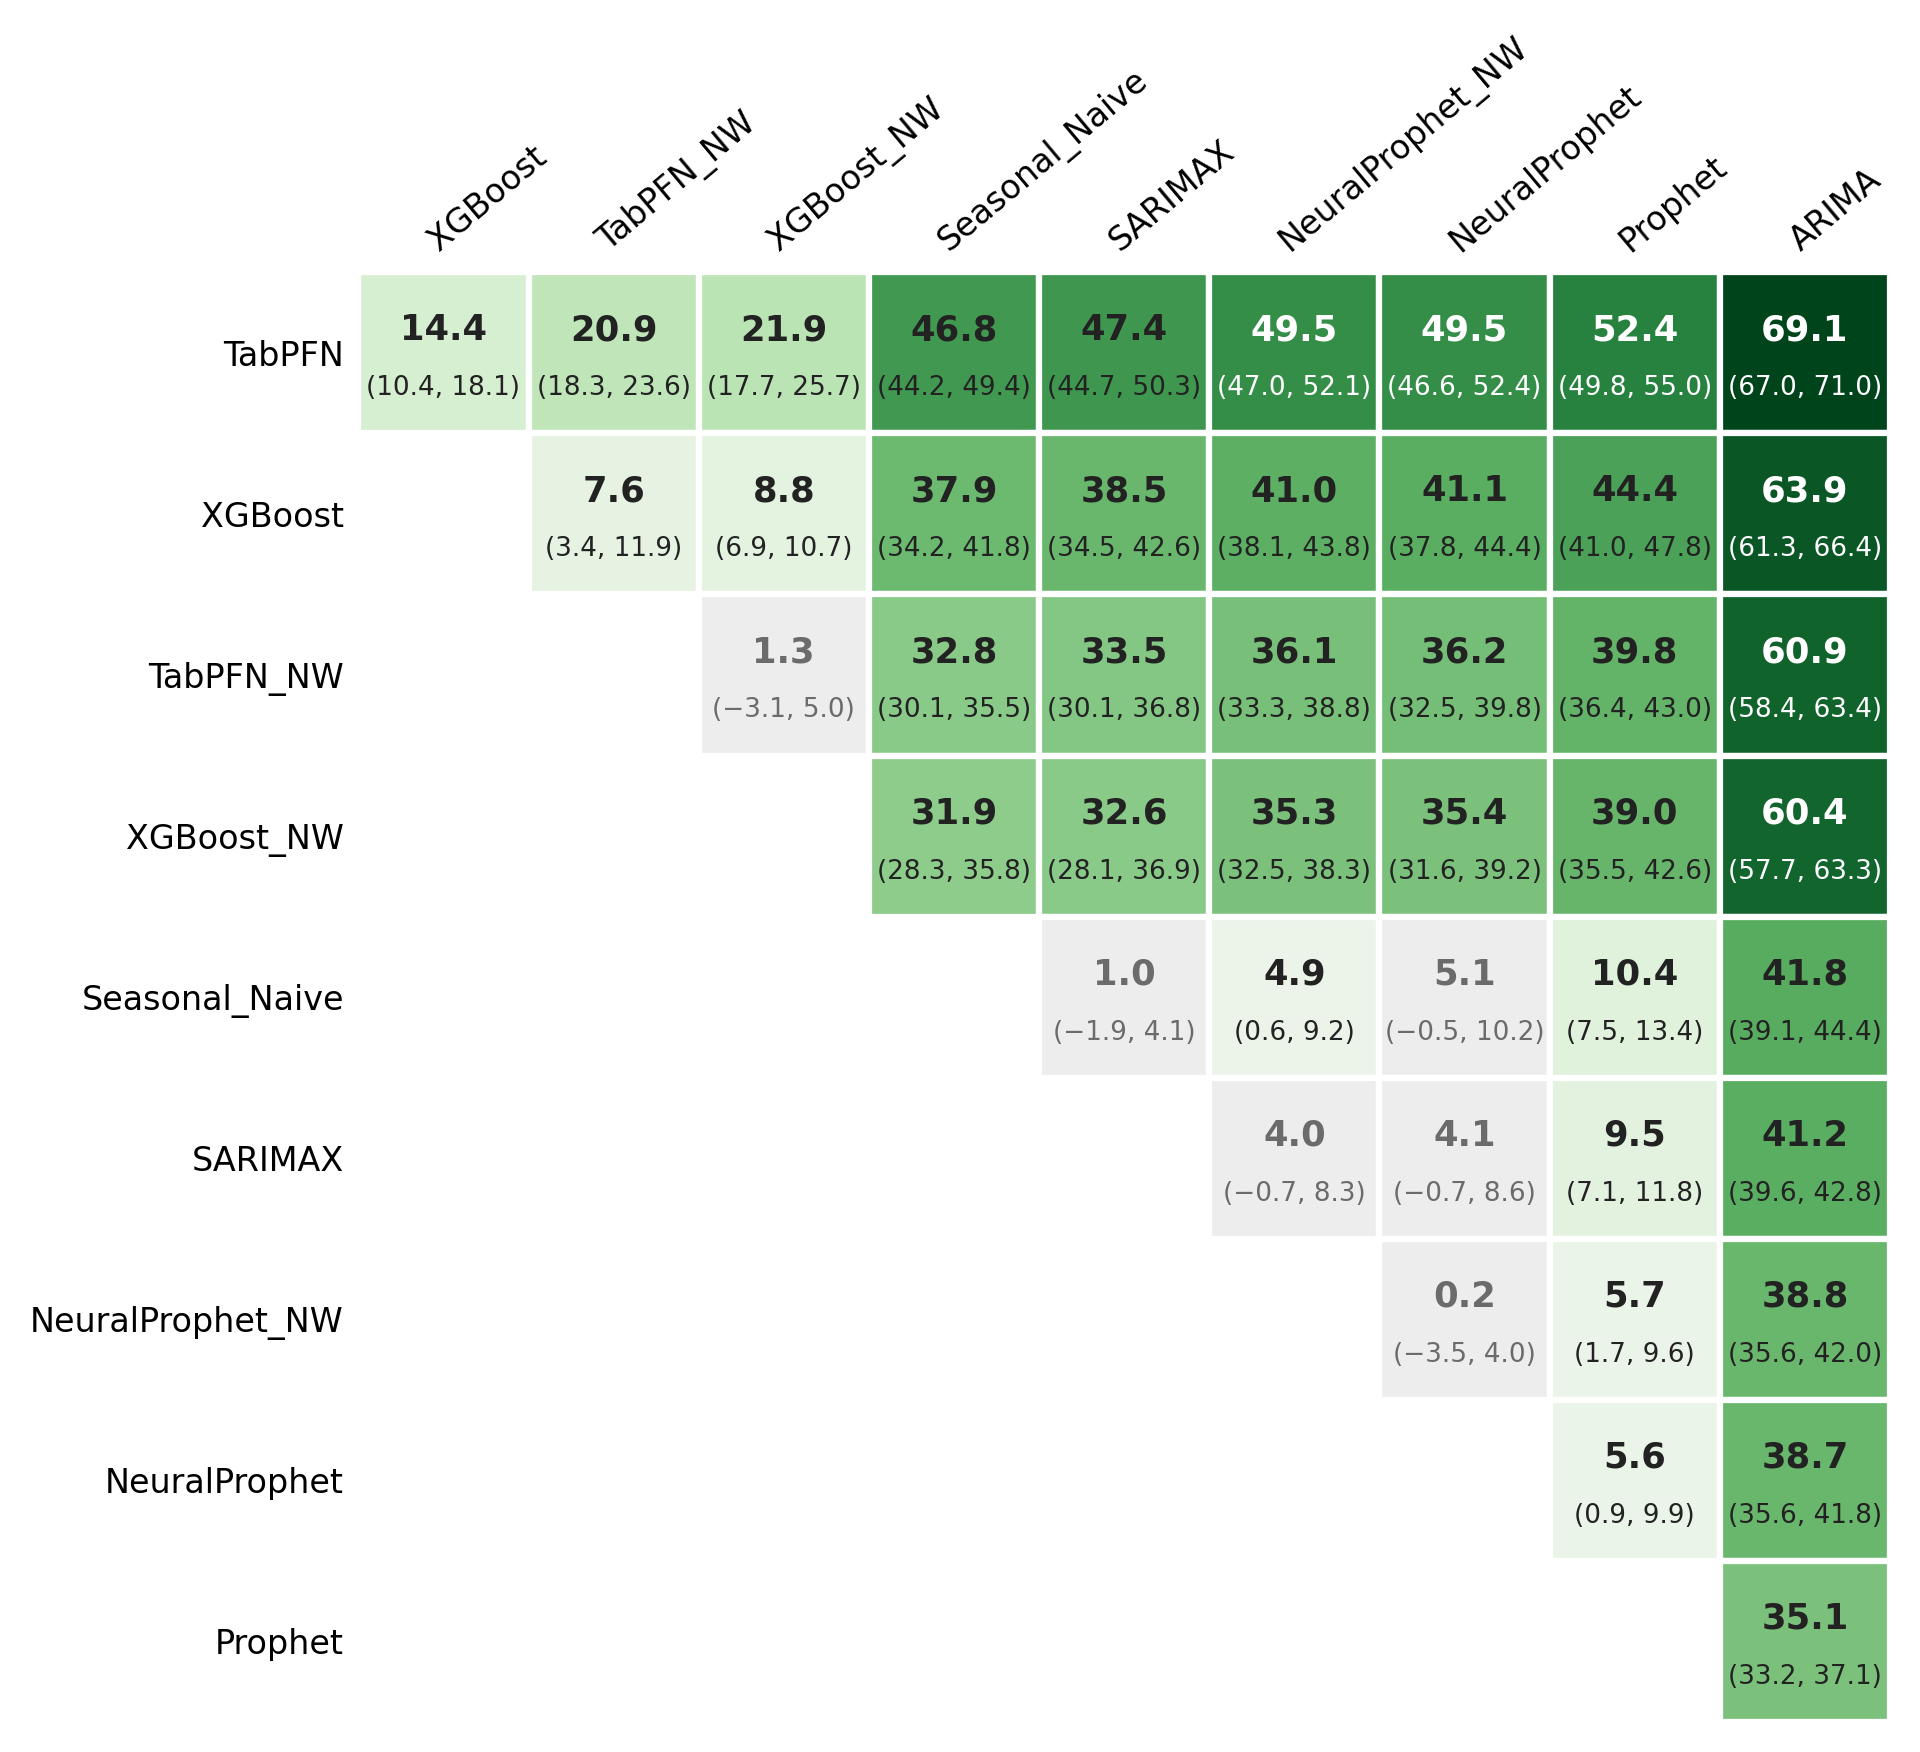

Saved: ../results_v7/figures/paper/fig_skill_score_heatmap.pdf / .png


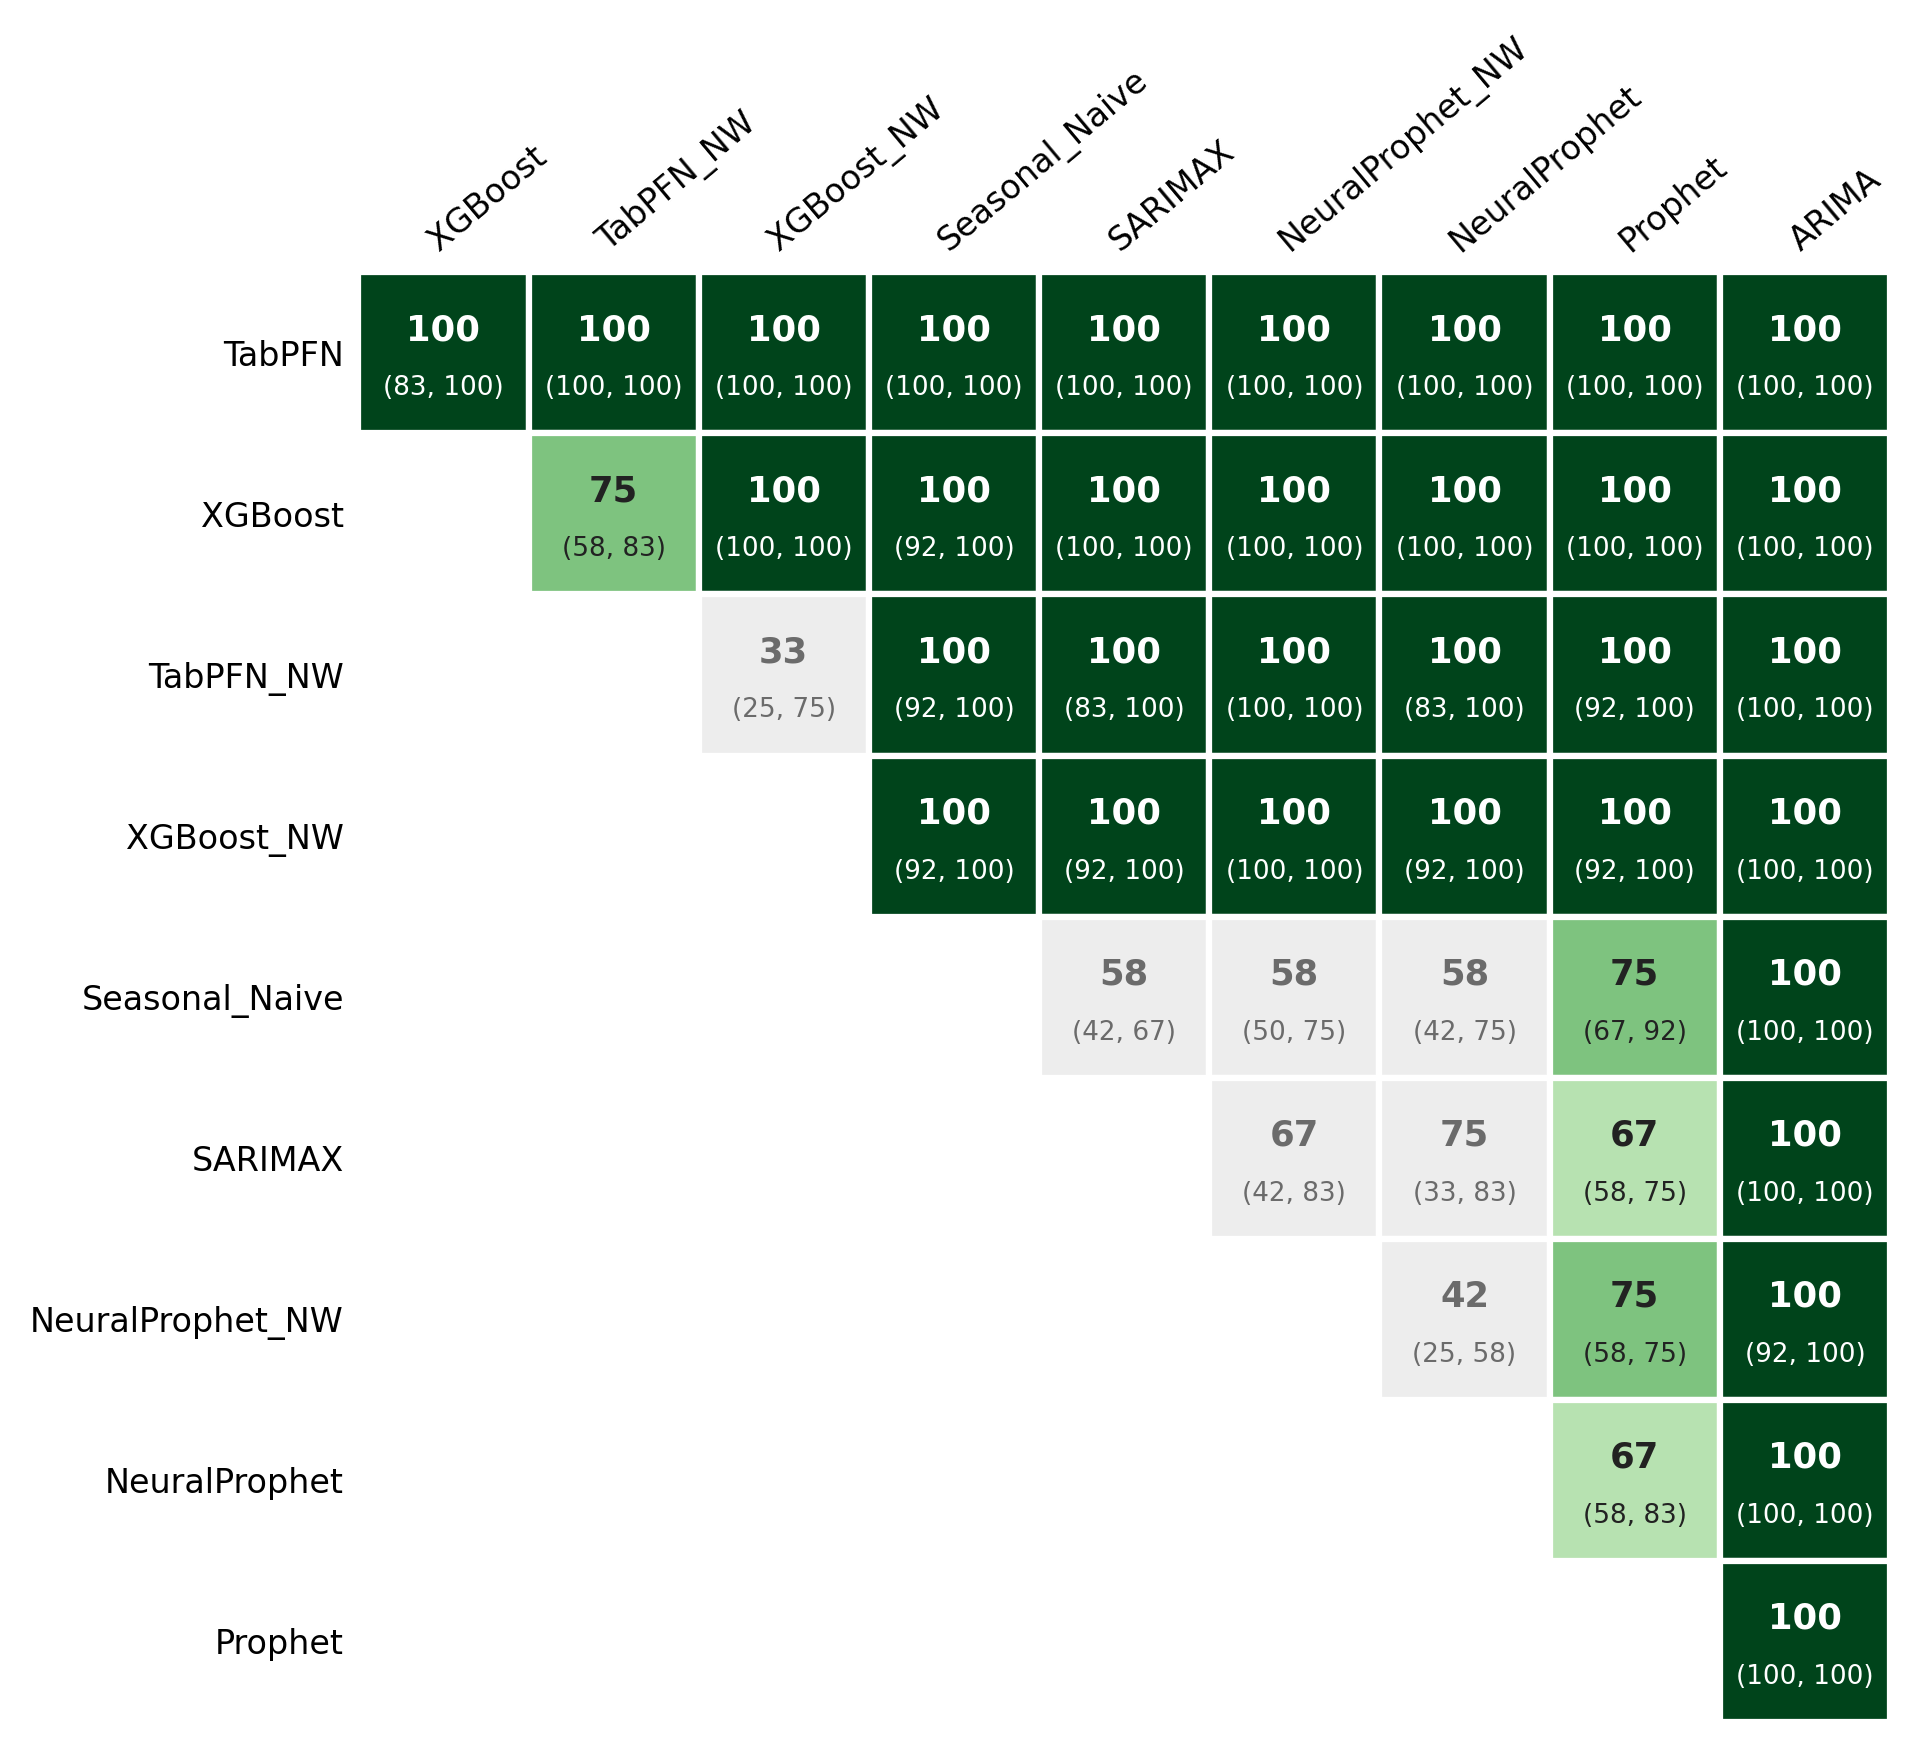

Saved: ../results_v7/figures/paper/fig_win_rate_heatmap.pdf / .png


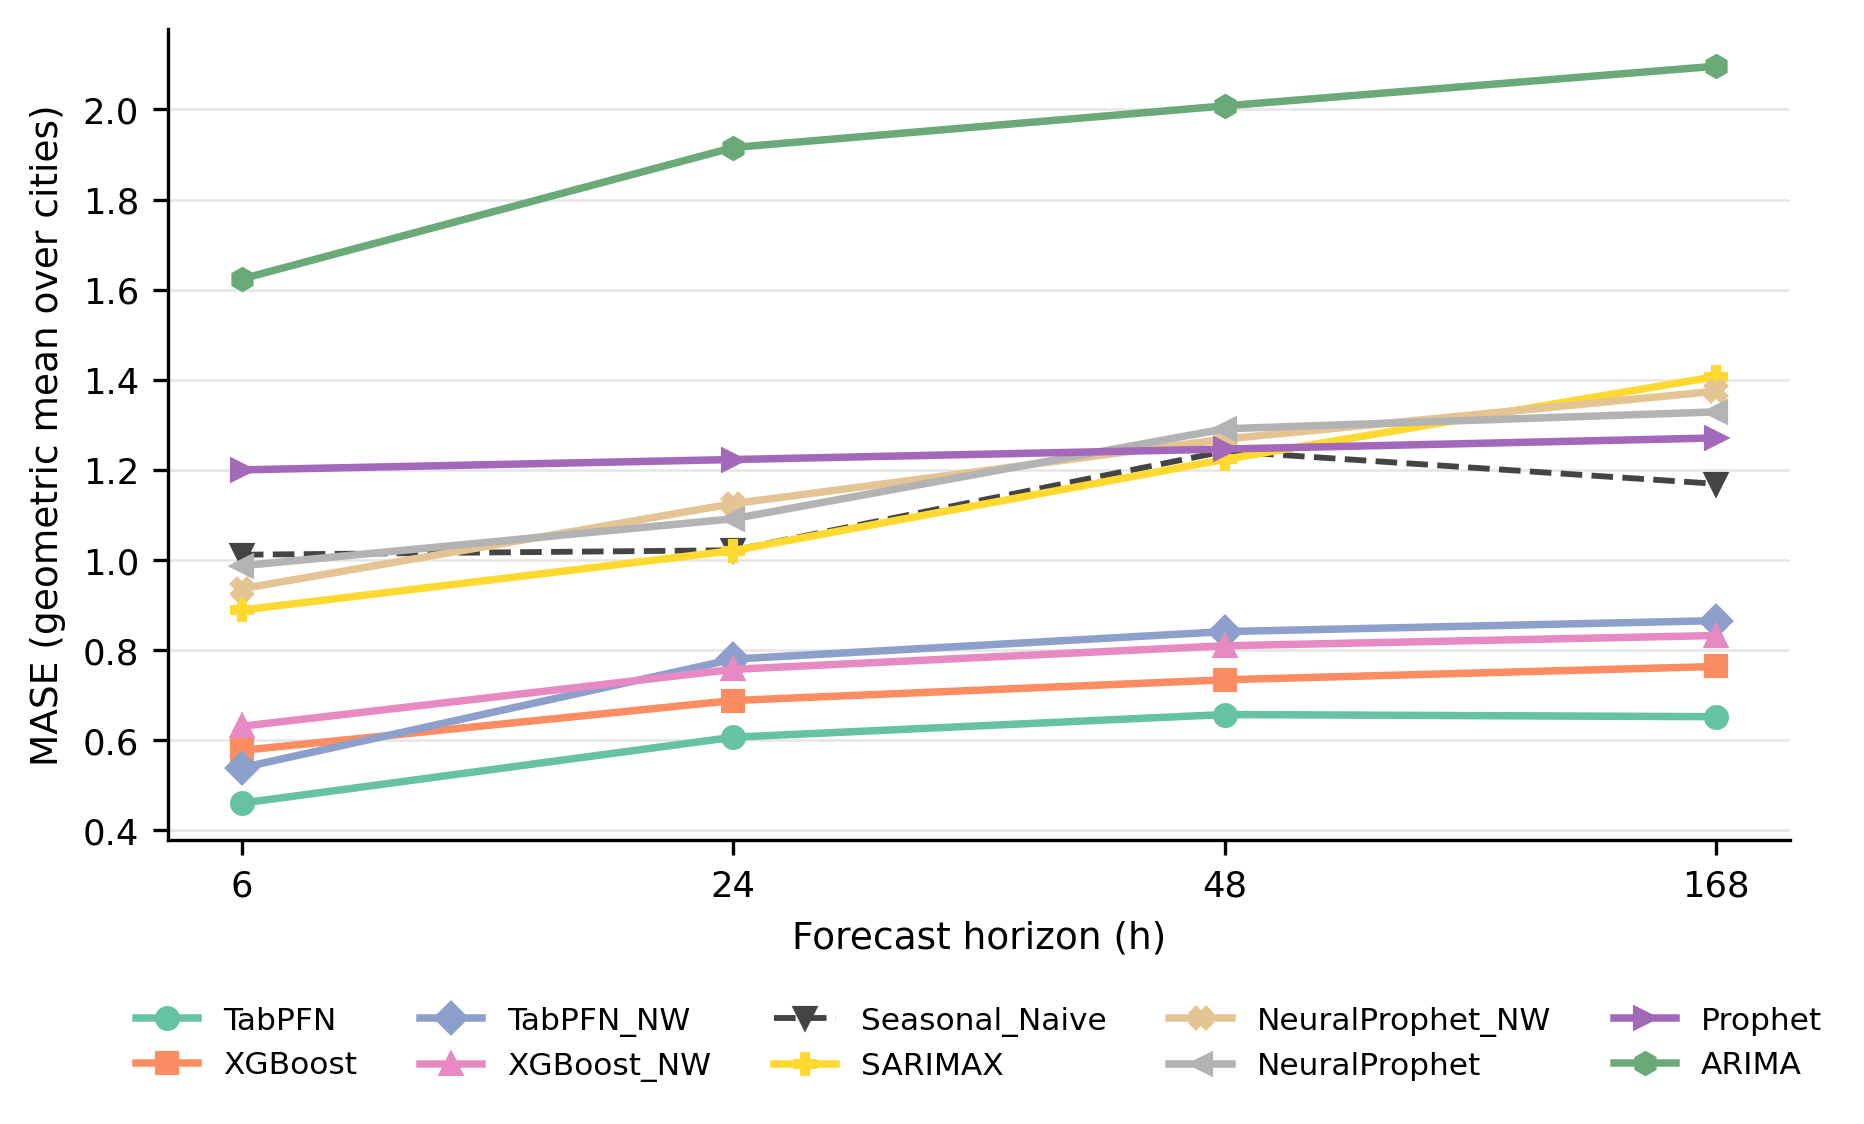

Saved: ../results_v7/figures/paper/fig_mase_by_horizon.pdf / .png


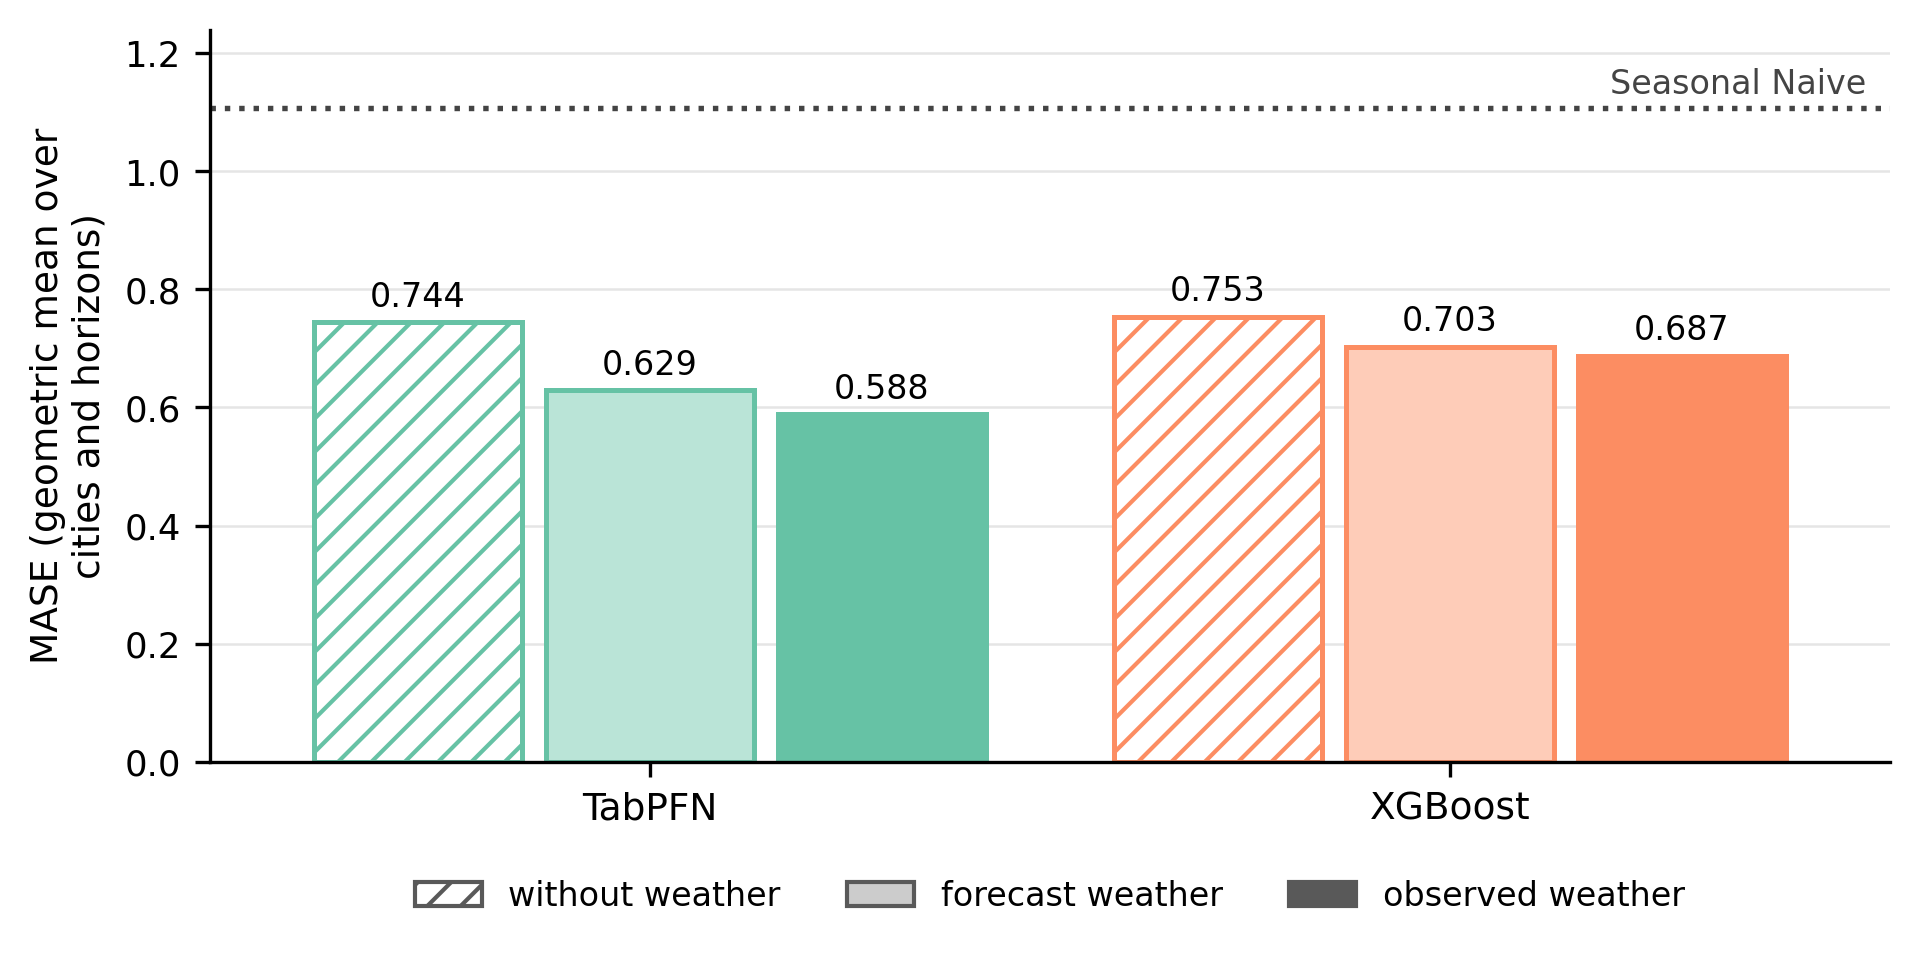

Saved: ../results_v7/figures/paper/fig_weather_settings.pdf / .png
Bar values: {'TabPFN': [0.744, 0.629, 0.588], 'XGBoost': [0.753, 0.703, 0.687]} | Seasonal Naive 1.107


In [45]:
# ── 6. Paper figures (page width, legible when printed) ─────────────────────────
# Four figures for the main text, saved as PDF (vector, preferred by LaTeX) and PNG to
# results_v7/figures/paper/. Copy them into the LaTeX folder figures/.
#   fig_skill_score_heatmap  pairwise skill score, observed weather, 95 % CI per cell
#   fig_win_rate_heatmap     pairwise win rate, observed weather, 95 % CI per cell
#   fig_mase_by_horizon      MASE by horizon, geometric mean over the cities (right half of the old fig12)
#   fig_weather_settings     TabPFN and XGBoost without / with forecast / with observed weather
# (6c below: the same two heatmaps for TabPFN and XGBoost in the three weather settings)
# Heatmaps: only the pairs in which the row model ranks above the column model are shown; the
# opposite pair follows from it (win rate: 100 - W; skill score: -S / (1 - S)). Cells whose CI
# contains 0 (skill score) or 50 (win rate) are grey: no significant difference.
# Same numbers as Section 4 (S_point, win_rate_matrix, bb = week block bootstrap).
from matplotlib.colors import TwoSlopeNorm, to_rgb
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

PAPER_DIR = Path('../results_v7/figures/paper'); PAPER_DIR.mkdir(parents=True, exist_ok=True)
PAGE_W = 6.5                                   # inches = text width; fonts below are print sizes
NS_FACE, NS_TEXT, GRID_C = '#ededed', '#6b6b6b', '#e5e5e5'
MINUS = lambda s: s.replace('-', '−')

def save_paper(fig, name):
    for ext in ('pdf', 'png'):
        fig.savefig(PAPER_DIR / f'{name}.{ext}', dpi=300, bbox_inches='tight')
    plt.show(); plt.close(fig)
    print(f'Saved: {PAPER_DIR / name}.pdf / .png')


def pair_heatmap(value, lo, hi, null, vmin, vmax, fmt_v, fmt_ci, name, order=None, label=None, rotate=True):
    # order: rows/columns, best first (default: the model ranking); label: name shown for each entry
    M = list(order) if order is not None else MODEL_ORDER_RANKED
    label = label or dn
    rows, cols = M[:-1], M[1:]                 # row model ranks above column model
    fig, ax = plt.subplots(figsize=(PAGE_W, 0.56 * len(rows) + 0.9))
    norm = TwoSlopeNorm(vcenter=null, vmin=vmin, vmax=vmax)
    cmap = plt.get_cmap('PRGn')
    for i, r in enumerate(rows):
        for j, c in enumerate(cols):
            if M.index(r) >= M.index(c):
                continue
            v, l, h = value.loc[r, c], lo.loc[r, c], hi.loc[r, c]
            sig = (l > null) or (h < null)
            face = cmap(norm(np.clip(v, vmin, vmax))) if sig else NS_FACE
            ax.add_patch(plt.Rectangle((j, i), 1, 1, facecolor=face, edgecolor='white', linewidth=1.5))
            lum = 0.299 * face[0] + 0.587 * face[1] + 0.114 * face[2] if sig else 1
            tc = 'white' if lum < 0.45 else ('#222222' if sig else NS_TEXT)
            ax.text(j + 0.5, i + 0.36, MINUS(fmt_v(v)), ha='center', va='center', fontsize=8.5,
                    fontweight='bold', color=tc)
            ax.text(j + 0.5, i + 0.72, MINUS(fmt_ci(l, h)), ha='center', va='center', fontsize=6.3, color=tc)
    ax.set_xlim(0, len(cols)); ax.set_ylim(len(rows), 0)
    ax.set_xticks(np.arange(len(cols)) + 0.5); ax.set_yticks(np.arange(len(rows)) + 0.5)
    if rotate:
        ax.set_xticklabels([label(c) for c in cols], rotation=40, ha='left', rotation_mode='anchor', fontsize=8)
    else:
        ax.set_xticklabels([label(c) for c in cols], fontsize=8)
    ax.set_yticklabels([label(r) for r in rows], fontsize=8)
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_aspect('auto')
    fig.tight_layout()
    save_paper(fig, name)


# 1 + 2: heatmaps
_ss_max = np.nanmax(S_point.values)
pair_heatmap(S_point, bb['S_lo'], bb['S_hi'], null=0, vmin=-_ss_max, vmax=_ss_max,
             fmt_v=lambda v: f'{v:.1f}', fmt_ci=lambda l, h: f'({l:.1f}, {h:.1f})',
             name='fig_skill_score_heatmap')
pair_heatmap(win_rate_matrix, bb['W_lo'], bb['W_hi'], null=50, vmin=0, vmax=100,
             fmt_v=lambda v: f'{v:.0f}', fmt_ci=lambda l, h: f'({l:.0f}, {h:.0f})',
             name='fig_win_rate_heatmap')

# 3: MASE by horizon (observed weather; geometric mean over the cities)
_byh = df_all_clean.groupby(['model', 'horizon'])['MASE_mean'].agg(gm).unstack('horizon')
_hs = sorted(_byh.columns.astype(int))
_markers = ['o', 's', 'D', '^', 'v', 'P', 'X', '<', '>', 'h']
fig, ax = plt.subplots(figsize=(PAGE_W, 3.9))
for k, m in enumerate(MODEL_ORDER_RANKED):
    sn = m == 'Seasonal_Naive'
    ax.plot(range(len(_hs)), _byh.loc[m, _hs].values, color='#444444' if sn else colors[k % len(colors)],
            linestyle='--' if sn else '-', linewidth=1.4 if sn else 1.8, marker=_markers[k % len(_markers)],
            markersize=5, label=dn(m))
ax.set_xticks(range(len(_hs))); ax.set_xticklabels(_hs)
ax.set_xlabel('Forecast horizon (h)', fontsize=9)
ax.set_ylabel('MASE (geometric mean over cities)', fontsize=9)
ax.tick_params(labelsize=8.5)
ax.grid(axis='y', color=GRID_C, linewidth=0.6); ax.set_axisbelow(True)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=5, frameon=False, fontsize=7.5)
fig.tight_layout()
save_paper(fig, 'fig_mase_by_horizon')

# 4: weather settings: TabPFN and XGBoost without / with forecast / with observed weather
def _gm_mase(df, m):
    return gm(df.loc[df['model'] == m, 'MASE_mean'])

_vals = {m: [_gm_mase(df_all_clean, f'{m}_NoWeather'), _gm_mase(df_all_degraded, m), _gm_mase(df_all_clean, m)]
         for m in ('TabPFN', 'XGBoost')}
_sn = _gm_mase(df_all_clean, 'Seasonal_Naive')
_labels = ['without weather', 'forecast weather', 'observed weather']
fig, ax = plt.subplots(figsize=(PAGE_W, 3.3))
w = 0.26
for g, m in enumerate(('TabPFN', 'XGBoost')):
    c = to_rgb(colors[MODEL_ORDER_RANKED.index(m) % len(colors)])
    light = tuple(0.45 * x + 0.55 for x in c)
    styles = [dict(facecolor='white', edgecolor=c, hatch='///'),
              dict(facecolor=light, edgecolor=c),
              dict(facecolor=c, edgecolor=c)]
    for b, (v, st) in enumerate(zip(_vals[m], styles)):
        x = g + (b - 1) * (w + 0.03)
        ax.bar(x, v, w, linewidth=1.2, **st)
        ax.text(x, v + 0.015, f'{v:.3f}', ha='center', va='bottom', fontsize=8)
ax.axhline(_sn, color='#444444', linestyle=':', linewidth=1.3)
ax.text(1.52, _sn + 0.012, 'Seasonal Naive', va='bottom', ha='right', fontsize=8, color='#444444')
ax.set_xticks([0, 1]); ax.set_xticklabels([dn('TabPFN'), dn('XGBoost')], fontsize=9)
ax.set_xlim(-0.55, 1.55)
ax.set_ylim(0, max(_sn, max(max(v) for v in _vals.values())) * 1.12)
ax.set_ylabel('MASE (geometric mean over\ncities and horizons)', fontsize=9)
ax.tick_params(axis='y', labelsize=8.5)
ax.grid(axis='y', color=GRID_C, linewidth=0.6); ax.set_axisbelow(True)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
_keys = [Patch(facecolor='white', edgecolor='0.35', hatch='///', label=_labels[0]),
         Patch(facecolor='0.8', edgecolor='0.35', label=_labels[1]),
         Patch(facecolor='0.35', edgecolor='0.35', label=_labels[2])]
ax.legend(handles=_keys, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False, fontsize=8)
fig.tight_layout()
save_paper(fig, 'fig_weather_settings')
print('Bar values:', {m: [round(v, 3) for v in vs] for m, vs in _vals.items()}, '| Seasonal Naive', round(_sn, 3))


Check | cells vs Section 5 percentages (value and 95 % CI): max difference 2.3e-14 -> OK
                        A                         B  skill_%  skill_lo  skill_hi  win_rate_%  win_lo  win_hi  significant
 TabPFN, observed weather  TabPFN, forecast weather      6.4       5.4       7.5       100.0   100.0   100.0         True
 TabPFN, observed weather XGBoost, observed weather     14.4      10.4      18.1       100.0    83.3   100.0         True
 TabPFN, observed weather XGBoost, forecast weather     16.3      12.5      20.0       100.0    91.7   100.0         True
 TabPFN, observed weather        TabPFN, no weather     20.9      18.3      23.6       100.0   100.0   100.0         True
 TabPFN, observed weather       XGBoost, no weather     21.9      17.7      25.7       100.0   100.0   100.0         True
 TabPFN, forecast weather XGBoost, observed weather      8.5       4.1      12.3       100.0    66.7   100.0         True
 TabPFN, forecast weather XGBoost, forecast weather     1

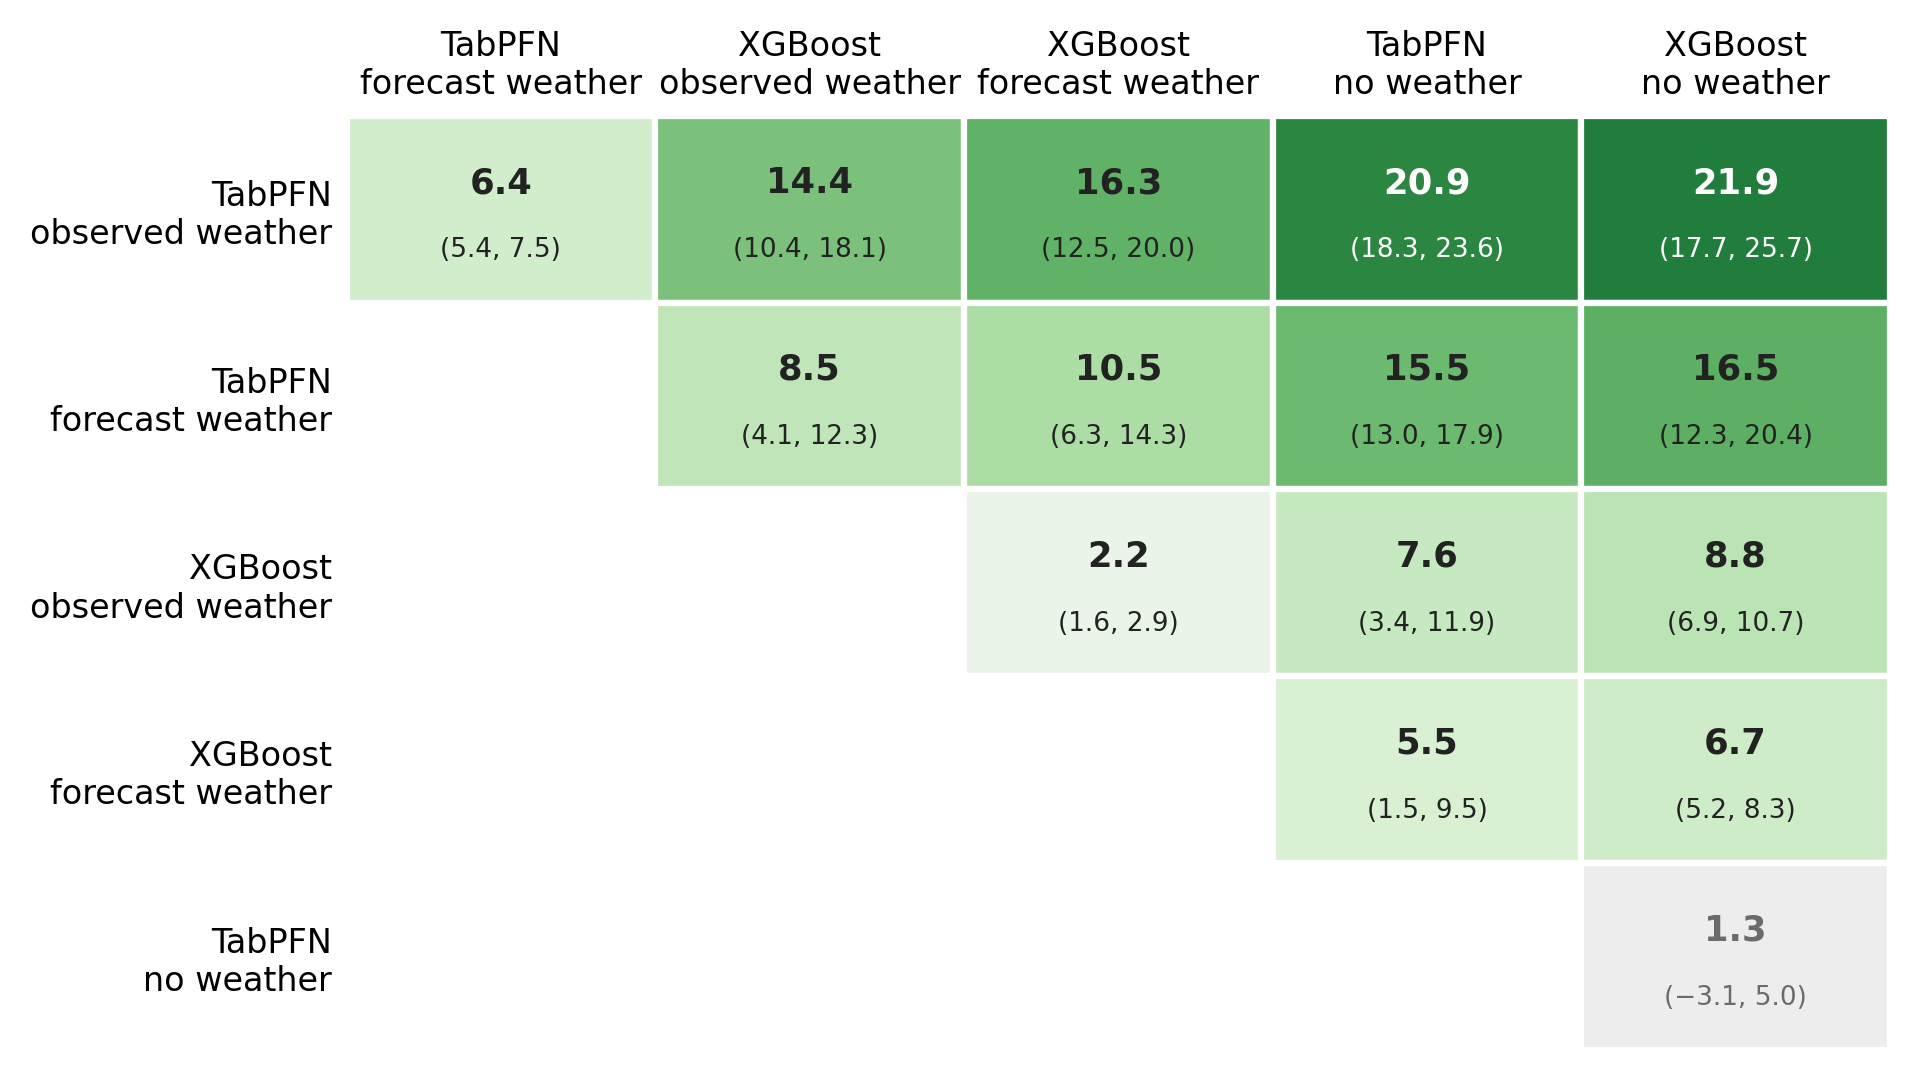

Saved: ../results_v7/figures/paper/fig_scenario_skill_score_heatmap.pdf / .png


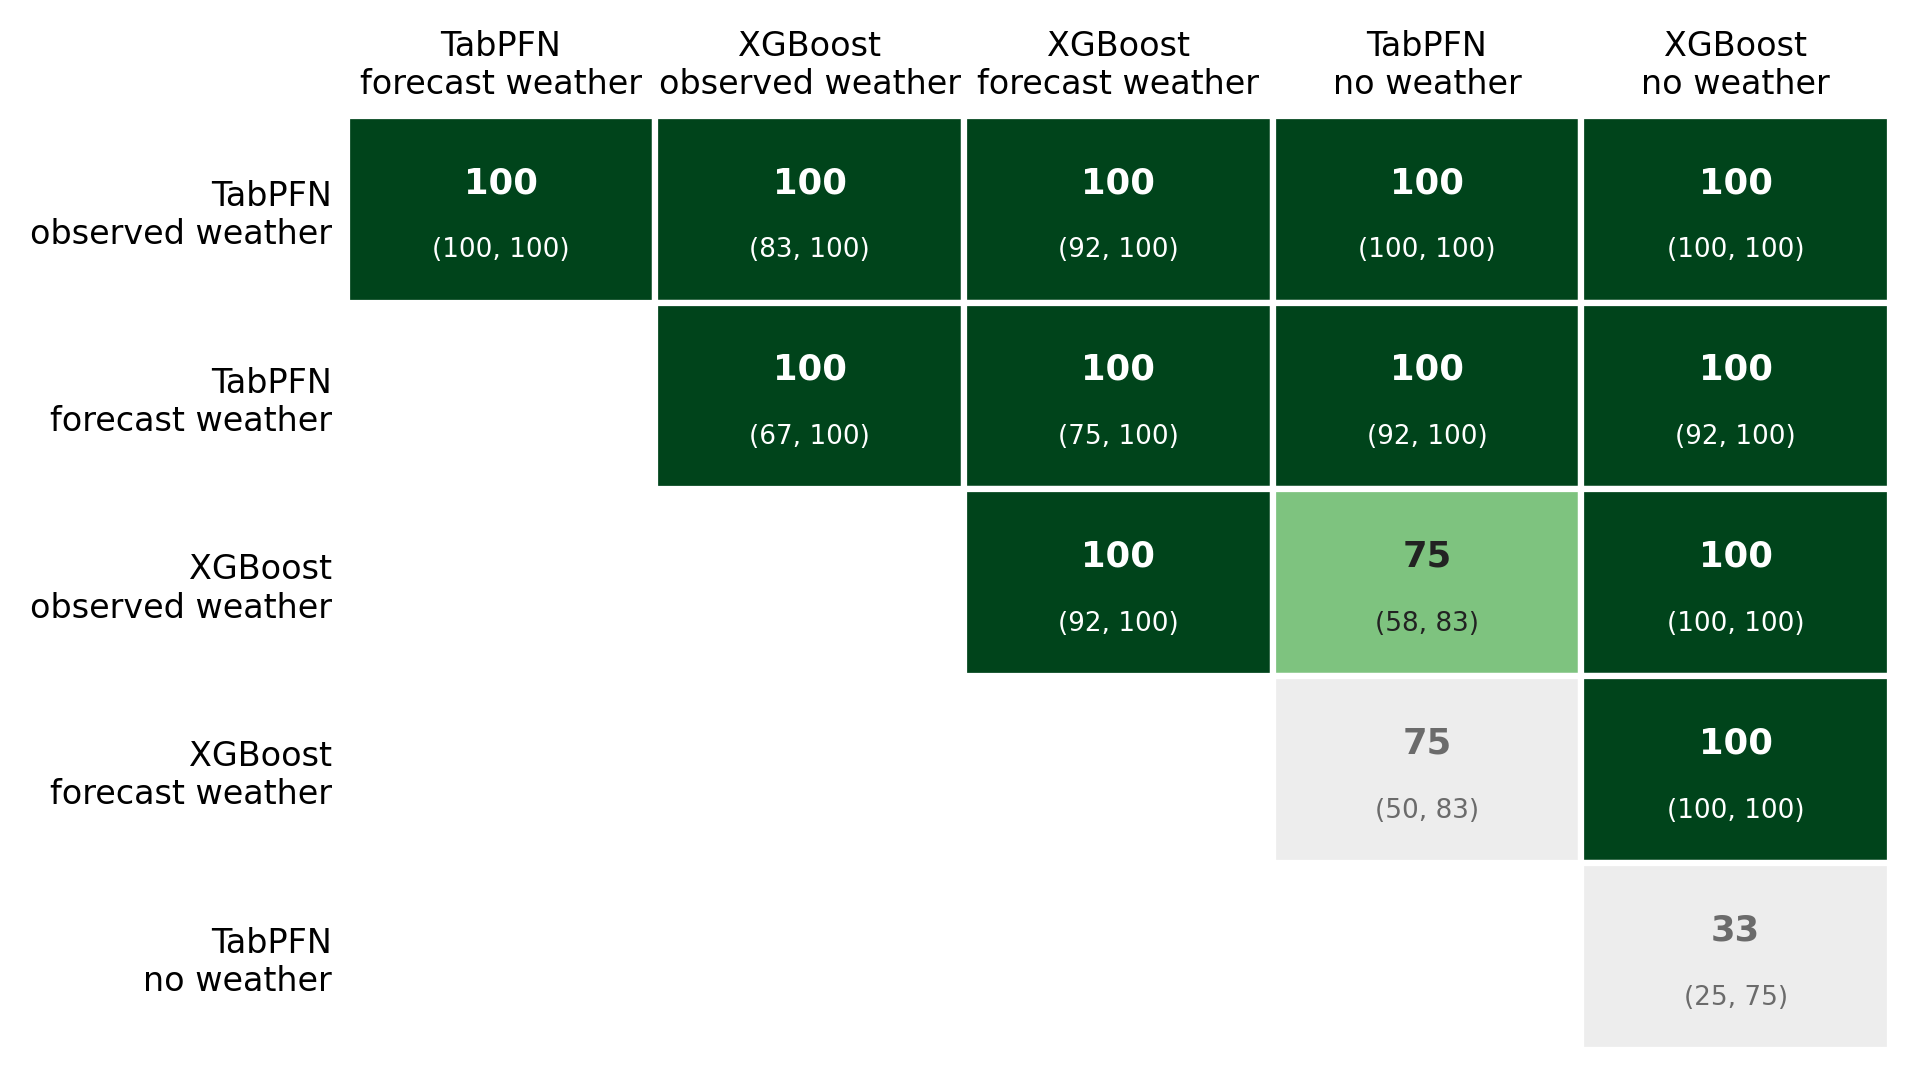

Saved: ../results_v7/figures/paper/fig_scenario_win_rate_heatmap.pdf / .png


In [46]:
# ── 6c. Weather settings: pairwise skill score and win rate of TabPFN and XGBoost ───────────────
# The comparison of fig_skill_score_heatmap / fig_win_rate_heatmap (fev-bench), extended from models to
# model x weather setting: TabPFN and XGBoost, each without, with forecast and with observed weather
# (six variants, 15 pairs). Every cell compares two variants over the 12 city-horizon combinations.
# Intervals: the week draws of Section 5 (E_rq), so every cell equals the corresponding percentage in
# rq_intervals_v7.csv and in the text (skill score = -change; checked below).
# Saves fig_scenario_skill_score_heatmap and fig_scenario_win_rate_heatmap (PDF + PNG) to
# results_v7/figures/paper/ and the 15 pairs to results_v7/tables/paper/scenario_pairs_v7.csv.
VARIANT_LABEL = {
    col('TabPFN'):              'TabPFN\nobserved weather',
    col('TabPFN', 'degraded'):  'TabPFN\nforecast weather',
    'TabPFN_NoWeather':         'TabPFN\nno weather',
    col('XGBoost'):             'XGBoost\nobserved weather',
    col('XGBoost', 'degraded'): 'XGBoost\nforecast weather',
    'XGBoost_NoWeather':        'XGBoost\nno weather',
}
_v  = list(VARIANT_LABEL)
_E0 = E0_rq[_v].values                       # (12 tasks, 6 variants), no resampling
_Eb = E_rq[..., [RQ_COLS.index(c) for c in _v]]   # (B, 12, 6), one per week draw

def _pairwise(E):
    """fev-bench Eq. 6 and 7 over the task axis: E (..., R, M) -> skill score S and win rate W (..., M, M), in %."""
    ratio = np.clip(E[..., :, :, None] / E[..., :, None, :], 0.01, 100)
    S = (1 - np.exp(np.nanmean(np.log(ratio), axis=-3))) * 100
    Ej, Ek = E[..., :, :, None], E[..., :, None, :]
    W = np.nanmean((Ej < Ek) + 0.5 * (Ej == Ek), axis=-3) * 100
    return S, W

with np.errstate(invalid='ignore', divide='ignore'):
    _S0, _W0 = _pairwise(_E0)
    _Sb, _Wb = _pairwise(_Eb)
_df = lambda a: pd.DataFrame(a, index=_v, columns=_v)
SC = {'S': _df(_S0), 'W': _df(_W0),
      'S_lo': _df(np.nanpercentile(_Sb, 2.5, axis=0)), 'S_hi': _df(np.nanpercentile(_Sb, 97.5, axis=0)),
      'W_lo': _df(np.nanpercentile(_Wb, 2.5, axis=0)), 'W_hi': _df(np.nanpercentile(_Wb, 97.5, axis=0))}

# Order: lowest MASE first (geometric mean over the 12 combinations), as in the other heatmaps
SC_ORDER = pd.Series(np.exp(np.log(_E0).mean(axis=0)), index=_v).sort_values().index.tolist()

# Check: every cell equals the percentage change of Section 5 (skill = -change; interval ends swap)
_dev = 0.0
for a in _v:
    for b in _v:
        if a != b:
            _ch = change_pct(E_rq, a, b, ALL_TASKS)
            _dev = max(_dev, abs(SC['S'].loc[a, b] + change_pct(E0_rq.values, a, b, ALL_TASKS)),
                       abs(SC['S_lo'].loc[a, b] + np.nanpercentile(_ch, 97.5)),
                       abs(SC['S_hi'].loc[a, b] + np.nanpercentile(_ch, 2.5)))
print(f"Check | cells vs Section 5 percentages (value and 95 % CI): max difference {_dev:.1e}"
      f" -> {'OK' if _dev < 1e-6 else 'PROBLEM: check Section 5'}")

# The 15 pairs as a table (A = the variant with the lower MASE)
_one = lambda c: VARIANT_LABEL[c].replace('\n', ', ')
scenario_pairs = pd.DataFrame([
    {'A': _one(a), 'B': _one(b),
     'skill_%': SC['S'].loc[a, b], 'skill_lo': SC['S_lo'].loc[a, b], 'skill_hi': SC['S_hi'].loc[a, b],
     'win_rate_%': SC['W'].loc[a, b], 'win_lo': SC['W_lo'].loc[a, b], 'win_hi': SC['W_hi'].loc[a, b],
     'significant': bool(SC['S_lo'].loc[a, b] > 0 or SC['S_hi'].loc[a, b] < 0)}
    for i, a in enumerate(SC_ORDER) for b in SC_ORDER[i + 1:]])
_tab = Path('../results_v7/tables/paper'); _tab.mkdir(parents=True, exist_ok=True)
scenario_pairs.round(2).to_csv(_tab / 'scenario_pairs_v7.csv', index=False)
print(scenario_pairs.round(1).to_string(index=False))
print(f"Saved: {_tab / 'scenario_pairs_v7.csv'}")

# Heatmaps: same design as fig_skill_score_heatmap / fig_win_rate_heatmap
_smax = np.nanmax(np.abs(SC['S'].values))
pair_heatmap(SC['S'], SC['S_lo'], SC['S_hi'], null=0, vmin=-_smax, vmax=_smax,
             fmt_v=lambda v: f'{v:.1f}', fmt_ci=lambda l, h: f'({l:.1f}, {h:.1f})',
             name='fig_scenario_skill_score_heatmap', order=SC_ORDER, label=VARIANT_LABEL.get, rotate=False)
pair_heatmap(SC['W'], SC['W_lo'], SC['W_hi'], null=50, vmin=0, vmax=100,
             fmt_v=lambda v: f'{v:.0f}', fmt_ci=lambda l, h: f'({l:.0f}, {h:.0f})',
             name='fig_scenario_win_rate_heatmap', order=SC_ORDER, label=VARIANT_LABEL.get, rotate=False)


## Section 7: Paper tables

Every results table of the paper is written here, complete with caption, label and notes, to `results_v7/tables/paper/<name>.tex`, and printed. The paper contains exactly these blocks: no numbers are combined or rounded by hand. Run Sections 3 to 5 first.

In [47]:
# ── 7. Paper tables: helpers ─────────────────────────────────────────────────────
# Values come only from objects computed above:
#   E0_rq          task MASE, (city, horizon) x model and weather setting (5.1; = master MASE_mean, Check 1)
#   rq_ci          percentage changes with 95 % CI (5.2; the same numbers as rq_intervals_v7.csv and the text)
#   cross_city_ranking, df_all_clean   sMAPE and the per-city MAE / RMSE (Section 3)
TAB_PAPER = Path('../results_v7/tables/paper'); TAB_PAPER.mkdir(parents=True, exist_ok=True)
PAPER_NAME = {'TabPFN': 'Tab\\-PFN', 'TabPFN_NoWeather': 'Tab\\-PFN\\_\\-NoWeather', 'XGBoost': 'XGBoost',
              'XGBoost_NoWeather': 'XGBoost\\_\\-NoWeather', 'Seasonal_Naive': 'Seasonal\\_Naive', 'SARIMAX': 'SARIMAX',
              'NeuralProphet_NoWeather': 'Neural\\-Prophet\\_NoWeather', 'NeuralProphet': 'Neural\\-Prophet',
              'Prophet': 'Prophet', 'ARIMA': 'ARIMA'}
CITY_NAME = {'seoul': 'Seoul', 'london': 'London', 'washington': 'Washington'}
HORIZONS  = sorted(int(h) for h in E0_rq.index.get_level_values('horizon').unique())


def rq(comparison, level='all'):
    """(value, ci_low, ci_high) of one comparison of Section 5.2: MASE change in %, negative = lower error."""
    r = rq_ci[(rq_ci['comparison'] == comparison) & (rq_ci['level'] == level)]
    if len(r) != 1:
        raise KeyError(f'{comparison!r} at level {level!r}: {len(r)} rows in rq_ci')
    return float(r['value'].iloc[0]), float(r['ci_low'].iloc[0]), float(r['ci_high'].iloc[0])


def gm_mase(column, horizon=None, dataset=None):
    """Geometric mean of the task MASE of one column (e.g. 'TabPFN[degraded]') over the selected tasks."""
    sel = np.ones(len(E0_rq), bool)
    if horizon is not None:
        sel &= E0_rq.index.get_level_values('horizon') == horizon
    if dataset is not None:
        sel &= E0_rq.index.get_level_values('dataset') == dataset
    return gm(E0_rq[column].values[sel])


def num(v, d=1, sign=False):
    """Number as printed in the tables; negative values in math mode, e.g. \\(-1.0\\)."""
    s = f'{v:+.{d}f}' if sign else f'{v:.{d}f}'
    if s.startswith('-') and float(s) == 0:
        s = s[1:]
    return f'\\({s}\\)' if s.startswith('-') else s


def ci_text(lo, hi, d=1, dash=True):
    """CI as printed in the tables: '12.4--16.8', or '\\(-4.3\\) to 1.9' (always 'to' with dash=False)."""
    if dash and f'{lo:.{d}f}'[0] != '-' and f'{hi:.{d}f}'[0] != '-':
        return f'{lo:.{d}f}--{hi:.{d}f}'
    return f'{num(lo, d)} to {num(hi, d)}'


def thousands(v, d=1):
    return f'{v:,.{d}f}'.replace(',', '{,}')


def save_table(name, tex):
    (TAB_PAPER / f'{name}.tex').write_text(tex)
    print(f'----- {name}.tex (copy into the paper; replaces the table with the same label) -----')
    print(tex)


def source_line(cell, name):
    return (f'% Source: comprehensive_results_analysis_v7 notebook, Section {cell}; '
            f'results_v7/tables/paper/{name}.tex (generated, do not edit the numbers by hand)\n')

In [48]:
# ── 7a. Table: impact of observed weather by horizon (tab:TabPFN_weather) ────────
# MASE: geometric mean over the cities (last row: over all 12 combinations). Improvement = -change of
# 'TabPFN: observed weather vs no weather' (and XGBoost) in Section 5.2; CI bounds swap with the sign.
def _impr(model, level):
    v, lo, hi = rq(f'{model}: {OBSW} vs no weather', level)
    return f'{num(-v)} ({ci_text(-hi, -lo)})'

_name = 'table_weather_impact'
tex  = '\\begin{table}\n\\centering\n'
tex += ('\\caption{Impact of observed weather on Tab\\-PFN and XGBoost across forecast horizons. MASE: geometric mean '
        'across Seoul, London and Washington; last row: over all 12 city--horizon combinations. Improvement: decrease '
        'in MASE with weather against the same model without weather, with 95\\,\\% CI.}\\label{tab:TabPFN_weather}\n')
tex += source_line('7a', _name)
tex += '\\resizebox{\\textwidth}{!}{%\n\\begin{tabular}{crrrr}\n\\toprule\n'
tex += ' & \\multicolumn{3}{c}{Tab\\-PFN} & XGBoost \\\\\n\\cmidrule(lr){2-4}\\cmidrule(lr){5-5}\n'
tex += 'Horizon & with weather & without weather & Improvement \\% (95\\,\\% CI) & Improvement \\% (95\\,\\% CI) \\\\\n\\midrule\n'
for h in HORIZONS:
    tex += (f"{h:<3} & {gm_mase('TabPFN', h):.3f} & {gm_mase('TabPFN_NoWeather', h):.3f} & "
            f"{_impr('TabPFN', f'{h} h')} & {_impr('XGBoost', f'{h} h')} \\\\\n")
tex += (f"\\midrule\nGeo.\\ mean & {gm_mase('TabPFN'):.3f} & {gm_mase('TabPFN_NoWeather'):.3f} & "
        f"{_impr('TabPFN', 'all')} & {_impr('XGBoost', 'all')} \\\\\n")
tex += '\\bottomrule\n\\end{tabular}%\n}\n\\end{table}\n'
save_table(_name, tex)

----- table_weather_impact.tex (copy into the paper; replaces the table with the same label) -----
\begin{table}
\centering
\caption{Impact of observed weather on Tab\-PFN and XGBoost across forecast horizons. MASE: geometric mean across Seoul, London and Washington; last row: over all 12 city--horizon combinations. Improvement: decrease in MASE with weather against the same model without weather, with 95\,\% CI.}\label{tab:TabPFN_weather}
% Source: comprehensive_results_analysis_v7 notebook, Section 7a; results_v7/tables/paper/table_weather_impact.tex (generated, do not edit the numbers by hand)
\resizebox{\textwidth}{!}{%
\begin{tabular}{crrrr}
\toprule
 & \multicolumn{3}{c}{Tab\-PFN} & XGBoost \\
\cmidrule(lr){2-4}\cmidrule(lr){5-5}
Horizon & with weather & without weather & Improvement \% (95\,\% CI) & Improvement \% (95\,\% CI) \\
\midrule
6   & 0.461 & 0.539 & 14.6 (12.4--16.8) & 8.5 (7.2--9.8) \\
24  & 0.607 & 0.780 & 22.2 (19.4--25.1) & 9.1 (7.0--11.5) \\
48  & 0.657 & 0.841 & 

In [49]:
# ── 7b. Table: loss of accuracy with forecast weather by horizon (tab:degradation_horizon_top2) ──
# MASE: geometric mean over the cities (last row: over all 12 combinations). Change = 'TabPFN: forecast
# weather vs observed weather' (and XGBoost) in Section 5.2.
def _loss(model, level):
    v, lo, hi = rq(f'{model}: {FCW} vs {OBSW}', level)
    return f'\\({v:+.1f}\\) ({ci_text(lo, hi)})'

def _cells(model, h=None):
    lvl = 'all' if h is None else f'{h} h'
    return f"{gm_mase(model, h):.3f} & {gm_mase(col(model, 'degraded'), h):.3f} & {_loss(model, lvl)}"

_name = 'table_forecast_weather_loss'
tex  = '\\begin{table}[h]\n\\centering\n'
tex += ('\\caption{Loss of accuracy with forecast weather, Tab\\-PFN and XGBoost, by forecast horizon. MASE: geometric '
        'mean across cities; last row: over all 12 city--horizon combinations. Change: increase in MASE from observed '
        'to forecast weather, with 95\\,\\% CI.}\\label{tab:degradation_horizon_top2}\n')
tex += source_line('7b', _name)
tex += '\\resizebox{\\textwidth}{!}{%\n\\begin{tabular}{crrrrrr}\n\\toprule\n'
tex += ' & \\multicolumn{3}{c}{Tab\\-PFN} & \\multicolumn{3}{c}{XGBoost} \\\\\n\\cmidrule(lr){2-4}\\cmidrule(lr){5-7}\n'
tex += 'Horizon & Observed & Forecast & Change \\% (95\\,\\% CI) & Observed & Forecast & Change \\% (95\\,\\% CI) \\\\\n\\midrule\n'
for h in HORIZONS:
    tex += f"{h:<3} & {_cells('TabPFN', h)} & {_cells('XGBoost', h)} \\\\\n"
tex += f"\\midrule\nGeo.\\ mean & {_cells('TabPFN')} & {_cells('XGBoost')} \\\\\n"
tex += '\\bottomrule\n\\end{tabular}%\n}\n'
tex += ('\\par\\smallskip{\\raggedright\\footnotesize Percentages: change from observed to forecast weather, computed '
        'for each city and horizon and averaged geometrically; they equal the ratio of the adjacent MASE values.\\par}\n')
tex += '\\end{table}\n'
save_table(_name, tex)

----- table_forecast_weather_loss.tex (copy into the paper; replaces the table with the same label) -----
\begin{table}[h]
\centering
\caption{Loss of accuracy with forecast weather, Tab\-PFN and XGBoost, by forecast horizon. MASE: geometric mean across cities; last row: over all 12 city--horizon combinations. Change: increase in MASE from observed to forecast weather, with 95\,\% CI.}\label{tab:degradation_horizon_top2}
% Source: comprehensive_results_analysis_v7 notebook, Section 7b; results_v7/tables/paper/table_forecast_weather_loss.tex (generated, do not edit the numbers by hand)
\resizebox{\textwidth}{!}{%
\begin{tabular}{crrrrrr}
\toprule
 & \multicolumn{3}{c}{Tab\-PFN} & \multicolumn{3}{c}{XGBoost} \\
\cmidrule(lr){2-4}\cmidrule(lr){5-7}
Horizon & Observed & Forecast & Change \% (95\,\% CI) & Observed & Forecast & Change \% (95\,\% CI) \\
\midrule
6   & 0.461 & 0.496 & \(+7.7\) (6.2--9.2) & 0.578 & 0.591 & \(+2.3\) (1.7--3.1) \\
24  & 0.607 & 0.638 & \(+5.2\) (3.9--6.6) & 0.688

In [50]:
# ── 7c. Table: overall ranking (tab:cross_city_overall_ranking) ──────────────────
# sMAPE and MASE: Table C0 (cross_city_ranking, Section 4). Skill % and CI: '<model> vs Seasonal Naive'
# in Section 5.2 (skill = -change, CI bounds swap); checked against the Skill % of Table C0.
def _skill(m):
    name = f'{m} vs Seasonal Naive' + (f', {OBSW}' if m in WEATHER_MODELS else '')
    v, lo, hi = rq(name)
    return -v, -hi, -lo

_dev = max(abs(_skill(m)[0] - cross_city_ranking.loc[m, 'Skill_pct'])
           for m in MODEL_ORDER_RANKED if m != 'Seasonal_Naive')
print(f"Check | Skill % from Section 5.2 vs Table C0 (rounded to 0.1): max difference {_dev:.3f}"
      f" -> {'OK' if _dev < 0.051 else 'PROBLEM'}")

_name = 'table_ranking'
tex  = '\\begin{table}[ht!]\n\\centering\n'
tex += ('\\caption{Model ranking over all cities and forecast horizons (clean weather; sMAPE and MASE: geometric mean '
        'over the 12 city-horizon tasks).}\\label{tab:cross_city_overall_ranking}\n')
tex += source_line('7c', _name)
tex += ('\\small\n\\setlength{\\tabcolsep}{3pt}\n\\begin{tabular*}{\\linewidth}{@{\\extracolsep{\\fill}}clrrrr@{}}\n'
        '\\toprule\nRank & Model & sMAPE & MASE & Skill \\% & 95\\,\\% CI \\\\\n\\midrule\n')
for m, r in cross_city_ranking.iterrows():
    if m == 'Seasonal_Naive':
        sk, ci = '0.0', '---'
    else:
        v, lo, hi = _skill(m)
        sk, ci = num(v, sign=True), ci_text(lo, hi, dash=False)
    tex += f"{int(r['Rank']):<2} & {PAPER_NAME[m]} & {r['sMAPE']:.1f} & {r['MASE']:.3f} & {sk} & {ci} \\\\\n"
tex += '\\bottomrule\n\\end{tabular*}\n'
tex += ('\\par\\smallskip{\\raggedright\\footnotesize Ranked by MASE. Skill \\%: skill score vs.\\ Seasonal\\_Naive, '
        '\\(100\\,(1 - \\mathrm{MASE}/\\mathrm{MASE}_{\\text{Seasonal Naive}})\\), so it gives the same order. '
        '95\\,\\% CI: week block bootstrap (Section~\\ref{sec:evaluation}).\\par}\n')
tex += '\\end{table}\n'
save_table(_name, tex)

Check | Skill % from Section 5.2 vs Table C0 (rounded to 0.1): max difference 0.044 -> OK
----- table_ranking.tex (copy into the paper; replaces the table with the same label) -----
\begin{table}[ht!]
\centering
\caption{Model ranking over all cities and forecast horizons (clean weather; sMAPE and MASE: geometric mean over the 12 city-horizon tasks).}\label{tab:cross_city_overall_ranking}
% Source: comprehensive_results_analysis_v7 notebook, Section 7c; results_v7/tables/paper/table_ranking.tex (generated, do not edit the numbers by hand)
\small
\setlength{\tabcolsep}{3pt}
\begin{tabular*}{\linewidth}{@{\extracolsep{\fill}}clrrrr@{}}
\toprule
Rank & Model & sMAPE & MASE & Skill \% & 95\,\% CI \\
\midrule
1  & Tab\-PFN & 25.0 & 0.588 & +46.8 & 44.2 to 49.4 \\
2  & XGBoost & 27.6 & 0.687 & +37.9 & 34.2 to 41.8 \\
3  & Tab\-PFN\_\-NoWeather & 29.7 & 0.744 & +32.8 & 30.1 to 35.5 \\
4  & XGBoost\_\-NoWeather & 29.0 & 0.753 & +31.9 & 28.3 to 35.8 \\
5  & Seasonal\_Naive & 43.1 & 1.107 & 0.0 

In [51]:
# ── 7d. Table: MAE and RMSE per city (tab:mae_rmse_city) ─────────────────────────
# Observed weather; geometric mean over the 4 horizons of each city (= MAE / RMSE of <city>_table1_overall_rankings.csv).
_mr = df_all_clean.groupby(['model', 'dataset']).agg(MAE=('MAE_mean', gm), RMSE=('RMSE_mean', gm))
_dev = 0.0
for ds in DATASETS:
    p = Path(f'../results_v7/tables/{ds}/{ds}_table1_overall_rankings.csv')
    if p.exists():
        t1 = pd.read_csv(p, index_col=0)
        _dev = max([_dev] + [abs(t1.loc[m, k] - _mr.loc[(m, ds), k]) for m in t1.index for k in ('MAE', 'RMSE')])
print(f"Check | vs <city>_table1_overall_rankings.csv: max difference {_dev:.3f} -> {'OK' if _dev < 0.001 else 'PROBLEM'}")

_name = 'table_mae_rmse_by_city'
tex  = '\\begin{table}[!htbp]\n\\centering\n'
tex += ('\\caption{MAE and RMSE (bikes per hour) per city, observed weather, geometric mean over the four forecast '
        'horizons. Mean hourly demand over the full dataset period: 740 (Seoul), 1{,}142 (London), and 188 '
        '(Washington) bikes.}\\label{tab:mae_rmse_city}\n')
tex += source_line('7d', _name).rstrip('\n') + '; mean demand: all hours of each dataset\n'
tex += '\\small\n\\setlength{\\tabcolsep}{3pt}\n\\begin{tabular*}{\\linewidth}{@{\\extracolsep{\\fill}}lrrrrrr@{}}\n\\toprule\n'
tex += ' & ' + ' & '.join(f'\\multicolumn{{2}}{{c}}{{{CITY_NAME[d]}}}' for d in DATASETS) + ' \\\\\n'
tex += '\\cmidrule(lr){2-3} \\cmidrule(lr){4-5} \\cmidrule(lr){6-7}\n'
tex += 'Model & ' + ' & '.join('MAE & RMSE' for _ in DATASETS) + ' \\\\\n\\midrule\n'
for m in MODEL_ORDER_RANKED:
    tex += (PAPER_NAME[m] + ' & ' + ' & '.join(f"{thousands(_mr.loc[(m, d), 'MAE'])} & {thousands(_mr.loc[(m, d), 'RMSE'])}"
                                               for d in DATASETS) + ' \\\\\n')
tex += '\\bottomrule\n\\end{tabular*}\n'
tex += ('\\par\\smallskip{\\raggedright\\footnotesize Rows in the order of the overall ranking '
        '(Table~\\ref{tab:cross_city_overall_ranking}).\\par}\n\\end{table}\n')
save_table(_name, tex)

Check | vs <city>_table1_overall_rankings.csv: max difference 0.000 -> OK
----- table_mae_rmse_by_city.tex (copy into the paper; replaces the table with the same label) -----
\begin{table}[!htbp]
\centering
\caption{MAE and RMSE (bikes per hour) per city, observed weather, geometric mean over the four forecast horizons. Mean hourly demand over the full dataset period: 740 (Seoul), 1{,}142 (London), and 188 (Washington) bikes.}\label{tab:mae_rmse_city}
% Source: comprehensive_results_analysis_v7 notebook, Section 7d; results_v7/tables/paper/table_mae_rmse_by_city.tex (generated, do not edit the numbers by hand); mean demand: all hours of each dataset
\small
\setlength{\tabcolsep}{3pt}
\begin{tabular*}{\linewidth}{@{\extracolsep{\fill}}lrrrrrr@{}}
\toprule
 & \multicolumn{2}{c}{Seoul} & \multicolumn{2}{c}{London} & \multicolumn{2}{c}{Washington} \\
\cmidrule(lr){2-3} \cmidrule(lr){4-5} \cmidrule(lr){6-7}
Model & MAE & RMSE & MAE & RMSE & MAE & RMSE \\
\midrule
Tab\-PFN & 190.5 & 263.7 & 

In [52]:
# ── 7e. Table: MASE by city and horizon (tab:mase_cross_city) ────────────────────
# Task MASE as in the master file (E0_rq): the four best models and Seasonal Naive with observed weather,
# Tab-PFN and XGBoost with forecast weather.
_cities = ['london', 'seoul', 'washington']                      # column order of the paper
_top    = [m for m in MODEL_ORDER_RANKED if m != 'Seasonal_Naive'][:4] + ['Seasonal_Naive']

def _row(label, column):
    return label + ' & ' + ' & '.join(f'{E0_rq.loc[(d, h), column]:.3f}' for d in _cities for h in HORIZONS) + ' \\\\\n'

_name = 'table_mase_city_horizon'
tex  = '\\begin{table}[ht!]\n\\centering\n'
tex += ('\\caption{MASE across all cities and forecast horizons: top 4 models vs.\\ baseline (clean weather), and '
        'Tab\\-PFN and XGBoost with degraded weather.}~\\label{tab:mase_cross_city}\n')
tex += source_line('7e', _name)
tex += '\\resizebox{\\textwidth}{!}{%\n\\begin{tabular}{l' + 'r' * (len(_cities) * len(HORIZONS)) + '}\n\\toprule\n'
tex += ' & ' + ' & '.join(f'\\multicolumn{{{len(HORIZONS)}}}{{c}}{{{CITY_NAME[d]}}}' for d in _cities) + ' \\\\\n'
tex += ' & ' + ' & '.join(str(h) for _ in _cities for h in HORIZONS) + ' \\\\\n\\midrule\n'
for m in _top:
    tex += _row(PAPER_NAME[m], m)
tex += '\\midrule\n\\multicolumn{' + str(1 + len(_cities) * len(HORIZONS)) + '}{l}{\\textit{Degraded weather}} \\\\\n'
for m in ('TabPFN', 'XGBoost'):
    tex += _row(PAPER_NAME[m], col(m, 'degraded'))
tex += '\\bottomrule\n\\end{tabular}%\n}\n\\end{table}\n'
save_table(_name, tex)

----- table_mase_city_horizon.tex (copy into the paper; replaces the table with the same label) -----
\begin{table}[ht!]
\centering
\caption{MASE across all cities and forecast horizons: top 4 models vs.\ baseline (clean weather), and Tab\-PFN and XGBoost with degraded weather.}~\label{tab:mase_cross_city}
% Source: comprehensive_results_analysis_v7 notebook, Section 7e; results_v7/tables/paper/table_mase_city_horizon.tex (generated, do not edit the numbers by hand)
\resizebox{\textwidth}{!}{%
\begin{tabular}{lrrrrrrrrrrrr}
\toprule
 & \multicolumn{4}{c}{London} & \multicolumn{4}{c}{Seoul} & \multicolumn{4}{c}{Washington} \\
 & 6 & 24 & 48 & 168 & 6 & 24 & 48 & 168 & 6 & 24 & 48 & 168 \\
\midrule
Tab\-PFN & 0.436 & 0.594 & 0.631 & 0.609 & 0.502 & 0.668 & 0.736 & 0.787 & 0.446 & 0.563 & 0.611 & 0.579 \\
XGBoost & 0.543 & 0.629 & 0.656 & 0.675 & 0.644 & 0.812 & 0.885 & 1.001 & 0.551 & 0.639 & 0.681 & 0.659 \\
Tab\-PFN\_\-NoWeather & 0.492 & 0.714 & 0.756 & 0.766 & 0.633 & 0.971 & 1.104 &

In [53]:
# ── 7f. Table: loss with forecast weather by city, all weather models (tab:degradation_city_all) ──
# '<model>: forecast weather vs observed weather' in Section 5.2, per city (geometric mean over the 4 horizons).
_name = 'table_forecast_weather_loss_by_city'
tex  = '\\begin{table}[h]\n\\centering\n'
tex += ('\\caption{Degradation by city (MASE increase \\%, clean to degraded weather), all weather-using models.}'
        '\\label{tab:degradation_city_all}\n')
tex += source_line('7f', _name)
tex += '\\begin{tabular}{lrrr}\n\\toprule\nModel & ' + ' & '.join(CITY_NAME[d] for d in DATASETS) + ' \\\\\n\\midrule\n'
for m in [m for m in MODEL_ORDER_RANKED if m in WEATHER_MODELS]:
    tex += PAPER_NAME[m] + ' & ' + ' & '.join(num(rq(f'{m}: {FCW} vs {OBSW}', d)[0]) for d in DATASETS) + ' \\\\\n'
tex += '\\bottomrule\n\\end{tabular}\n\\end{table}\n'
save_table(_name, tex)

----- table_forecast_weather_loss_by_city.tex (copy into the paper; replaces the table with the same label) -----
\begin{table}[h]
\centering
\caption{Degradation by city (MASE increase \%, clean to degraded weather), all weather-using models.}\label{tab:degradation_city_all}
% Source: comprehensive_results_analysis_v7 notebook, Section 7f; results_v7/tables/paper/table_forecast_weather_loss_by_city.tex (generated, do not edit the numbers by hand)
\begin{tabular}{lrrr}
\toprule
Model & Seoul & London & Washington \\
\midrule
Tab\-PFN & 9.2 & 5.7 & 5.8 \\
XGBoost & 3.1 & 2.4 & 1.3 \\
SARIMAX & 3.3 & 3.3 & 1.6 \\
Neural\-Prophet & 5.9 & 7.7 & 3.0 \\
\bottomrule
\end{tabular}
\end{table}



## Summary

**fev-bench metrics added:**
1. **Win Rate Matrix (Wjk)**: pairwise % of tasks where model j beats model k
2. **Skill Scores (Sj)**: % improvement over Seasonal Naive using geometric mean
3. **Bootstrap CIs**: 95% block-bootstrap intervals (one-week blocks, B=1000) for all pairwise win rates and skill scores; top-4 table
4. **By-horizon breakdown**: win rates vs Seasonal Naive for each h ∈ {6, 24, 48, 168}
5. **Scenario impact**: covariate benefit (clean vs degraded)

**Outputs saved:**
- `win_rate_matrix.csv`
- `skill_scores.csv`
- `win_rates_by_horizon.csv`
- `skill_score_by_scenario.csv`
- `win_rate_heatmap.png`
- `skill_scores.png`

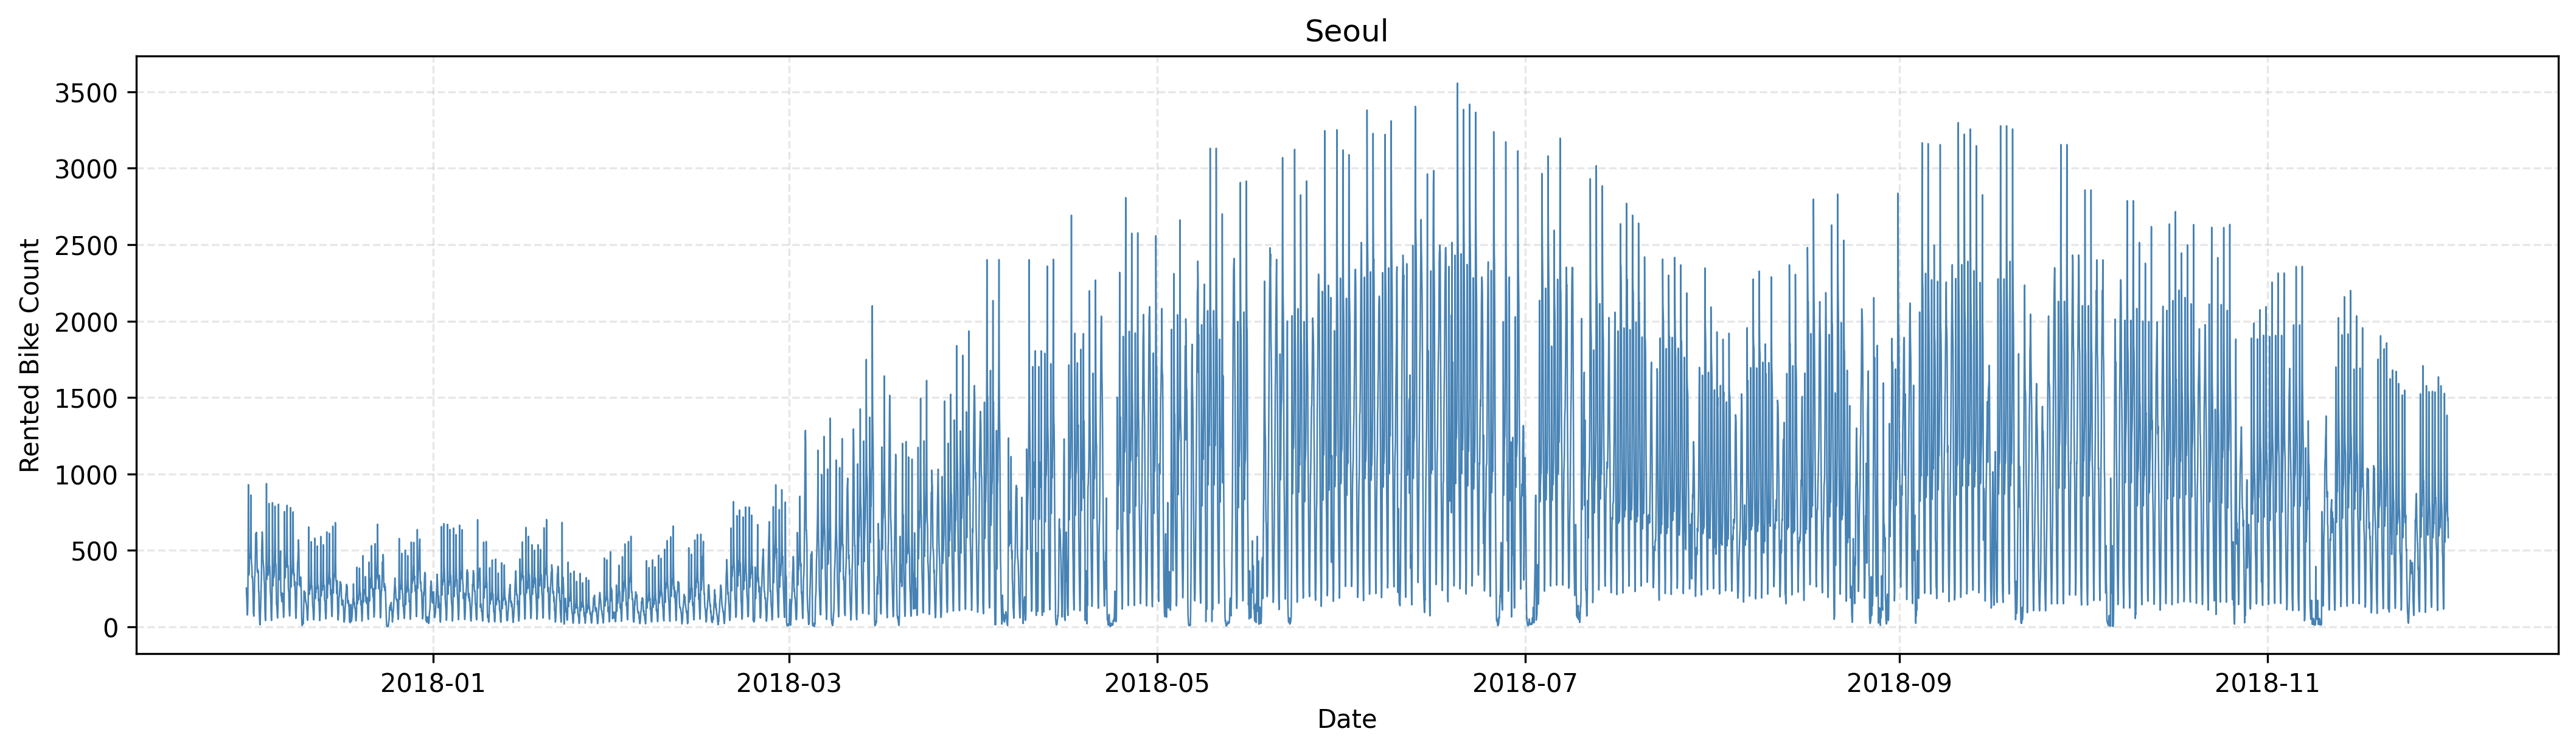

Saved → Seoul


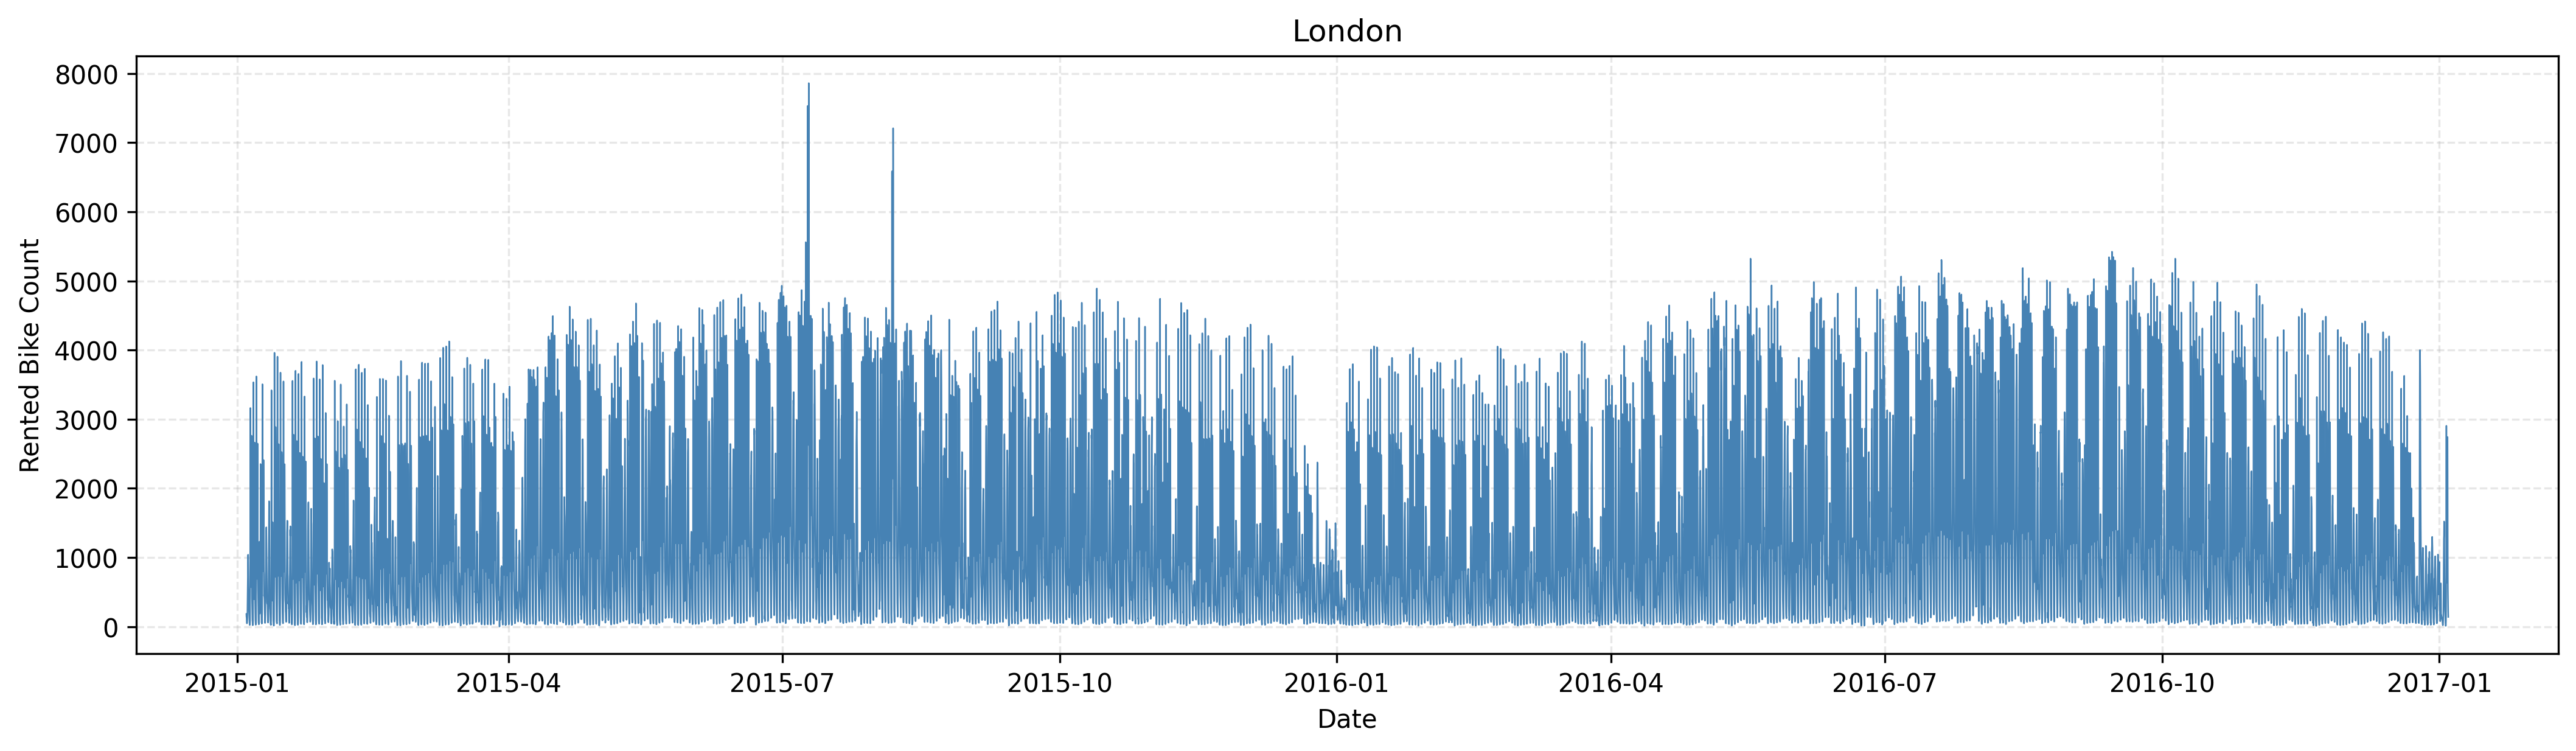

Saved → London


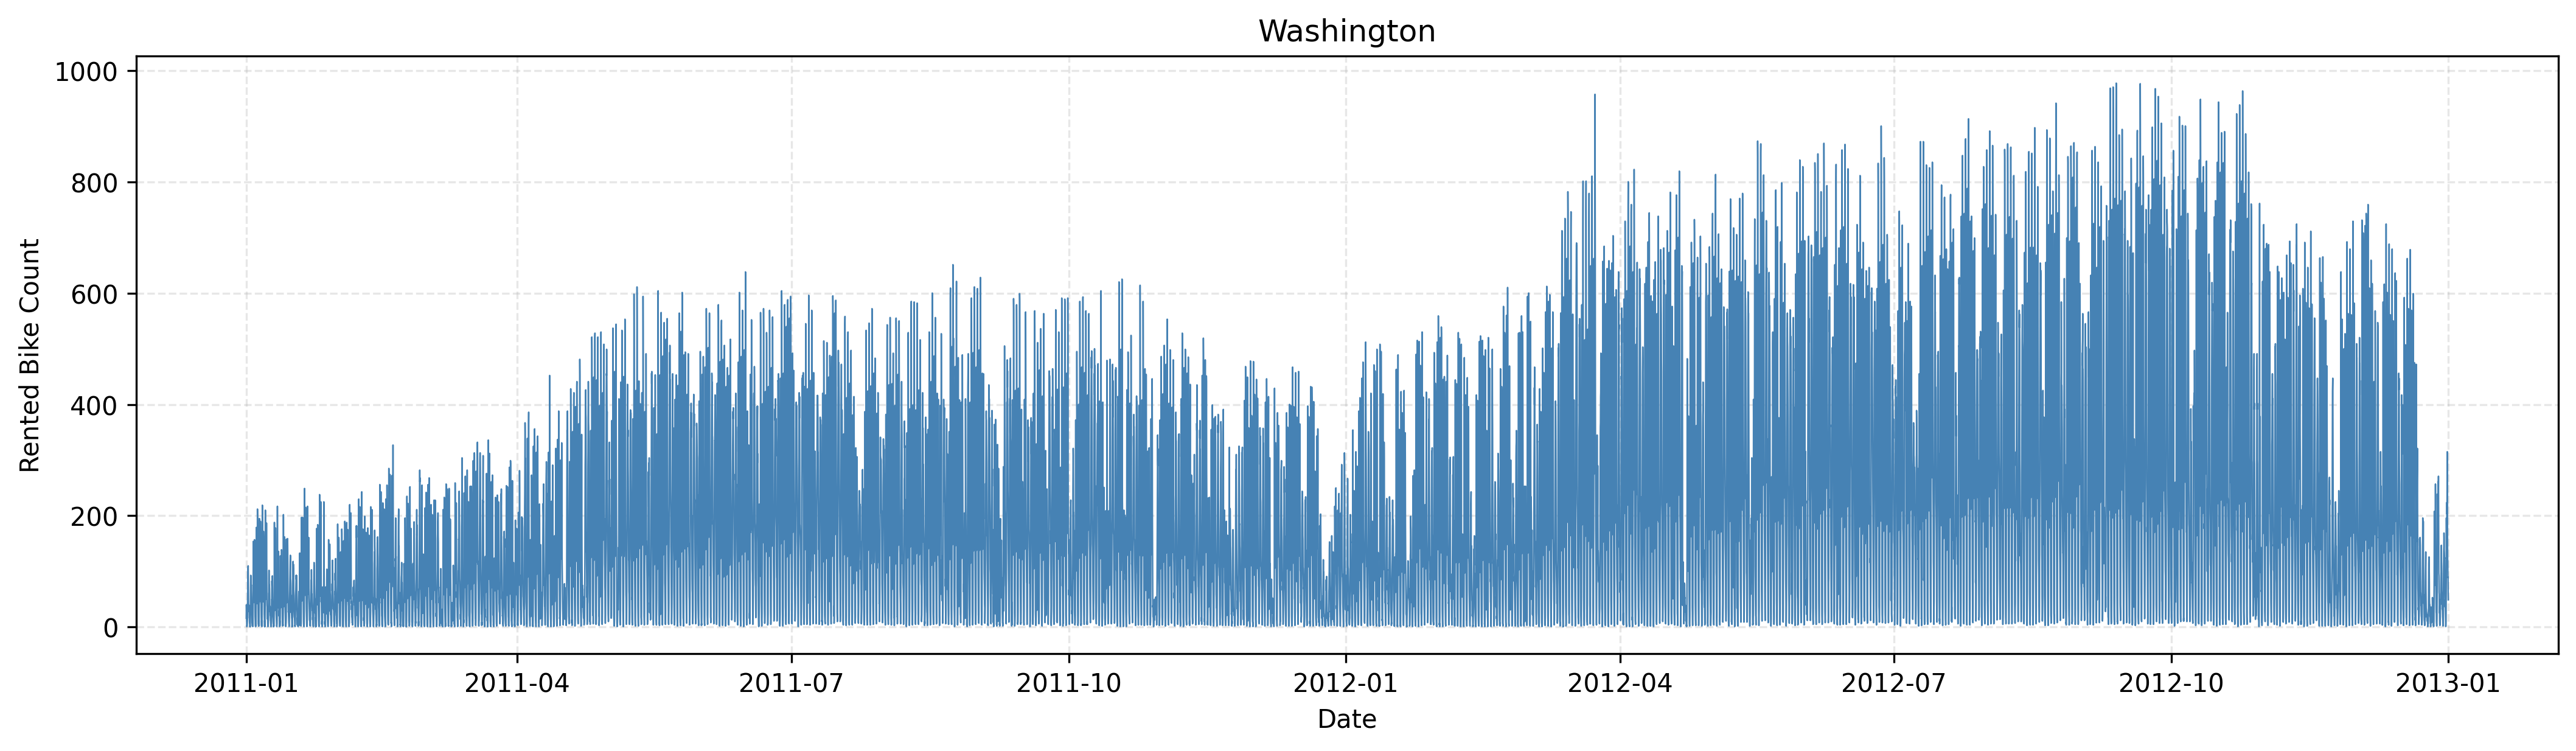

Saved → Washington


In [54]:
city_data = {
    'Seoul':      ('../data/SeoulBikeData.csv', 'Date',      'Rented Bike Count'),
    'London':     ('../data/LondonBikeData.csv', 'timestamp', 'cnt'),
    'Washington': ('../data/WashingtonBikeData.csv','timestamp', 'cnt'),
}

city_data = {k: v for k, v in city_data.items() if k.lower() in DATASETS}
for city, (path, date_col, count_col) in city_data.items():
    df = pd.read_csv(path, parse_dates=[date_col])
    fig, ax = plt.subplots(figsize=(14, 4), constrained_layout=True)
    ax.plot(df[date_col], df[count_col], linewidth=0.6, color='steelblue')
    ax.set_title(f'{city}')
    ax.set_xlabel('Date')
    ax.set_ylabel('Rented Bike Count')
    ax.grid(alpha=0.3, linestyle='--')
    fig.savefig(f'../results_v7/figures/{city.lower()}_rentals_over_time.png',
                dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print(f'Saved → {city}')

## Suggested figure captions for the paper (the figures contain no titles)

All results are from v7 and use clean weather unless stated. MASE is the mean absolute error divided by the in-sample seasonal-naive (24 h) MAE of the training window of each fold; lower is better. Horizons: 6, 24, 48 and 168 h.

**Cross-city figures** (`figures/cross_city/`)

- `figC1_mase_by_model_city.png` — MASE of each model in each city, geometric mean over horizons. Dotted lines: MASE of the Seasonal Naive model in each city.
- `figC2_rank_consistency.png` — Average rank by MASE (1 = best) of each model in each city: models are ranked within each horizon, then the ranks are averaged over horizons.
- `figC3_degradation_cross_city.png` — Increase in MASE from clean to degraded weather for each weather-using model and city. Each bar is the geometric mean over horizons of the degraded/clean MASE ratio.
- `figC4_mase_by_horizon_faceted.png` — MASE by forecast horizon for each model, one panel per city.
- `figC5_mase_by_horizon.png` — MASE by forecast horizon for each model, geometric mean across cities. Dashed line: Seasonal Naive.
- `figC6_degradation_mase_bars.png` — MASE of each weather-using model under clean and degraded weather (geometric mean over cities and horizons). Labels: increase from clean to degraded.
- `win_rate_heatmap.png` — Pairwise win rate (%): share of tasks (city × horizon) on which the row model has a lower MASE than the column model; ties count 0.5. In parentheses: 95% block-bootstrap interval (one-week blocks, 1000 resamples).
- `skill_scores.png` — Pairwise skill score (%): 1 − geometric mean over tasks of MASE(row model) / MASE(column model), ratios clipped to [0.01, 100]. Positive values mean the row model is more accurate. Intervals as for the win rates.
- `figRQ_forest.png` — Comparisons answering the research questions: change in MASE of the first against the second (geometric mean over the 12 city–horizon combinations; negative = lower error), with 95% intervals from the week block bootstrap (1000 resamples). Diamonds: difference of two changes, in percentage points. Right: value, interval and the number of combinations with a negative value.
- `figRQ_by_horizon.png` — The same comparisons by forecast horizon (geometric mean over the three cities), with 95% intervals: (a) Tab-PFN vs XGBoost without weather, with observed and with forecast weather; (b) change in MASE with observed weather against no weather; (c) change in MASE with forecast weather against observed weather.
- `fig12_cross_city_heatmap_MASE_by_horizon.png` — Left: pairwise win rate (%) over all tasks. Right: MASE by forecast horizon, geometric mean across cities (dashed: Seasonal Naive).
- `figures/<city>_rentals_over_time.png` — Hourly bike rentals over the full data period of each city.

**Paper figures** (`figures/paper/`, Section 6; the captions in the paper .tex are the current ones)

- `fig_skill_score_heatmap` — Pairwise skill score (%) of the row model against the column model, observed weather; in parentheses 95% CI; grey = no significant difference. Only pairs with the row model ranked higher.
- `fig_win_rate_heatmap` — Pairwise win rate (%) of the row model against the column model; in parentheses 95% CI; grey = no significant difference.
- `fig_mase_by_horizon` — MASE by forecast horizon, geometric mean over the cities, observed weather; dashed: Seasonal Naive.
- `fig_weather_settings` — MASE of TabPFN and XGBoost without weather, with forecast weather and with observed weather; dotted: Seasonal Naive.

**Per-city figures** (`figures/<city>/`, error metric is MAE in bikes per hour)

- `<city>_fig12_heatmap_MAE_by_horizon.png` — Left: rank of each model (1 = best) by MAE, RMSE, MASE and sMAPE at each horizon. Right: MAE of each model by horizon.
- `<city>_fig6_degradation_overview.png` — MAE of each weather-using model under clean and degraded weather, geometric mean over horizons. Labels: percentage increase (geometric mean of the per-horizon degraded/clean ratios, equal to the ratio of the two bars).
- `<city>_fig7_degradation_by_horizon.png` — Percentage increase in MAE from clean to degraded weather, by horizon, for each weather-using model.
- `<city>_fig9_degradation_heatmap.png` — The same percentage increase as a heatmap (model × horizon).
- `<city>_fig10_variance_comparison.png` — Distribution over folds of MAE under clean and degraded weather for each weather-using model (one panel per model), shown separately for each forecast horizon.
